# 11. Recurrent Neural Networks for Volatility Prediction

## Introduction

Financial time series exhibit temporal dependencies, changing volatility, and periods of elevated market uncertainty. Modeling these characteristics is an important problem in financial machine learning.

In the previous notebook, `10_classical_time_series_baseline.ipynb`, we investigated classical time-series models, including autoregressive (AR), moving-average (MA), and autoregressive moving-average (ARMA) models.

We examined stationarity, autocorrelation, and volatility clustering in SPY daily log returns. We then modeled squared returns using AR, MA, and ARMA, and used an ARMA(1,1) model to construct forecasts of five-day realized volatility.

Although the ARMA model captured some temporal structure, its ability to anticipate volatility increases was limited.

In this notebook, we investigate **recurrent neural networks (RNNs)** and their extensions for financial time-series prediction.

Unlike classical linear time-series models, recurrent neural networks learn nonlinear transformations of sequential observations through a hidden state that evolves over time.

We will investigate whether these architectures can extract useful predictive information from historical SPY observations and improve upon our classical and Stage-0 machine-learning baselines.

## Prediction Objective

Our original objective is to predict whether the realized volatility over the next five trading days will exceed the current historical volatility by a specified factor.

Let the daily log return be

$$
r_t=\log\left(\frac{C_t}{C_{t-1}}\right),
$$

where $C_t$ denotes the adjusted closing price of SPY on trading day $t$.

The future five-day realized volatility is

$$
RV_{t,t+5}
=
\sqrt{\frac15\sum_{k=1}^{5}r_{t+k}^2}.
$$

The historical 20-day realized volatility is

$$
Vol_{t,20}
=
\sqrt{\frac1{20}\sum_{j=0}^{19}r_{t-j}^2}.
$$

We define the binary classification target

$$
\boxed{
y_t=
\mathbb{1}
\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{t,20}}
\right)>0.2
\right\}.
}
$$

Thus:

- $y_t=1$: Future five-day volatility exceeds approximately $1.2214$ times the current 20-day volatility.
- $y_t=0$: Otherwise.

Our neural networks will estimate

$$
\hat p_t=P(y_t=1\mid \mathbf X_t),
$$

where $\mathbf X_t$ denotes a sequence of historical observations available through trading day $t$.

A binary prediction is obtained by applying a decision threshold to $\hat p_t$.

## Scope of the Notebook

We will proceed through the following stages.

### 1. Project Setup and Imports

Configure TensorFlow/Keras, import the required libraries, and establish reproducibility.

### 2. Data Preparation and Sequence Construction

Load the SPY dataset and construct chronological input sequences.

For a lookback window of length $L$, an input sequence takes the form

$$
\mathbf X_t=
\begin{bmatrix}
\mathbf x_{t-L+1}\\
\mathbf x_{t-L+2}\\
\vdots\\
\mathbf x_t
\end{bmatrix}
\in\mathbb R^{L\times d},
$$

where $d$ denotes the number of features observed at each time step.

We will ensure that no future observations enter the input sequences.

### 3. Simple Recurrent Neural Networks

Introduce the mathematical formulation of an RNN, including its hidden state, recurrent transformation, and output layer.

Implement a simple RNN using TensorFlow/Keras and evaluate its predictive performance.

### 4. Long Short-Term Memory Networks (LSTM)

Study the limitations of simple RNNs, particularly vanishing gradients and long-range dependencies.

Introduce LSTM memory cells and gating mechanisms, followed by implementation and experiments.

### 5. Gated Recurrent Units (GRU)

Introduce GRUs as an alternative gated recurrent architecture.

Compare GRUs with simple RNNs and LSTMs in terms of predictive performance and computational cost.

### 6. Model Evaluation and Comparison

Evaluate the models using:

- Accuracy
- Balanced accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Log loss

Compare neural sequence models with the previously saved ARMA baseline and, where appropriate, Stage-0 models.

All comparisons will use identical evaluation dates and target definitions.

### 7. Experiments and Analysis

Investigate the effects of sequence length, model complexity, regularization, and feature selection.

Analyze whether more expressive recurrent architectures provide measurable improvements over simpler alternatives.

## Experimental Principles

1. **Chronological splitting:** Preserve the temporal ordering of observations.
2. **No look-ahead bias:** Use only information available at each prediction date.
3. **Training-only preprocessing:** Fit normalization and other learned transformations using training data.
4. **Consistent evaluation:** Compare models on the same observations and labels.
5. **Validation-based model selection:** Use validation data for hyperparameter selection and reserve the test set for final evaluation.
6. **Reproducibility:** Record model configurations, random seeds, training histories, and evaluation results.

The primary objective is to understand recurrent neural networks through a complete financial time-series application, rather than merely maximizing predictive performance.


## 1. Project Setup and Imports

### 1.1 Computational Environment

We use **TensorFlow/Keras** to implement recurrent neural networks.

These experiments are developed in the `finance` Conda environment on an Apple Silicon MacBook Pro.

The principal libraries are:

- **NumPy:** Numerical computations and array manipulation.
- **pandas:** Financial time-series data manipulation.
- **Matplotlib:** Visualization of training histories and predictions.
- **scikit-learn:** Preprocessing and model evaluation.
- **TensorFlow/Keras:** Neural network construction, training, and inference.

We will record the TensorFlow version and available computational devices to document the experimental environment.

For reproducibility, we will also initialize random seeds. This reduces variability between runs, although complete determinism is not guaranteed across all hardware and operations.


### 1.2: Imports

In [1]:
# Import utilities for filesystem paths.
from pathlib import Path

# Import JSON for saving experiment configurations.
import json

# Import Python's random-number generator.
import random

# Import NumPy for numerical operations.
import numpy as np

# Import pandas for financial time-series manipulation.
import pandas as pd

# Import Matplotlib for visualization.
import matplotlib.pyplot as plt

# Import TensorFlow for neural network modeling.
import tensorflow as tf

# Import the Keras high-level neural network API.
from tensorflow import keras

# Import neural network layers.
from tensorflow.keras import layers

# Import the standard feature scaler.
from sklearn.preprocessing import StandardScaler

# Import classification evaluation metrics.
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    classification_report,
)

### 1.3: Reproducibility and hardware

In [2]:
# Define a fixed random seed.
SEED = 42

# Initialize Python's random-number generator.
random.seed(SEED)

# Initialize NumPy's random-number generator.
np.random.seed(SEED)

# Initialize TensorFlow/Keras random-number generators.
keras.utils.set_random_seed(SEED)

# Display the TensorFlow version.
print("TensorFlow version:", tf.__version__)

# Display the available physical devices.
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 1.4: Load data and project directories

In [3]:
# Define the repository root.
PROJECT_ROOT = Path("..")

# Define the processed-data directory.
DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Define the directory containing saved classical results.
CLASSICAL_RESULTS_DIR = PROJECT_ROOT / "results" / "classical"

# Define the directory for recurrent neural network models.
RNN_MODEL_DIR = PROJECT_ROOT / "models" / "rnn"

# Define the directory for recurrent neural network results.
RNN_RESULTS_DIR = PROJECT_ROOT / "results" / "rnn"

# Create the RNN model directory.
RNN_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Create the RNN results directory.
RNN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Display the project directories.
print("Data directory:", DATA_DIR)
print("Classical results:", CLASSICAL_RESULTS_DIR)
print("RNN models:", RNN_MODEL_DIR)
print("RNN results:", RNN_RESULTS_DIR)

Data directory: ../data/processed
Classical results: ../results/classical
RNN models: ../models/rnn
RNN results: ../results/rnn


### 1.5: Verify the saved classical baseline

In [4]:
# Define the path to the saved ARMA validation predictions.
arma_predictions_path = (
    CLASSICAL_RESULTS_DIR / "arma_validation_predictions.csv"
)

# Check whether the baseline predictions exist.
if arma_predictions_path.exists():

    # Load the ARMA validation predictions.
    arma_validation = pd.read_csv(
        arma_predictions_path,
        index_col="Date",
        parse_dates=["Date"],
    )

    # Display the number of saved validation observations.
    print("ARMA validation observations:", len(arma_validation))

    # Display the first few observations.
    display(arma_validation.head())

else:

    # Report that the expected baseline file was not found.
    print("ARMA validation predictions not found:", arma_predictions_path)

ARMA validation observations: 498


,Actual RV,Predicted RV,Historical Vol 20D,Classification Threshold,Actual Label,Predicted Label
Date,,,,,,
2021-01-04,0.008697,0.009621,0.006095,0.007445,1,1
2021-01-05,0.008138,0.009218,0.005986,0.007311,1,1
2021-01-06,0.007782,0.008796,0.006115,0.007469,1,1
2021-01-07,0.004418,0.010739,0.006917,0.008448,0,1
2021-01-08,0.004877,0.009806,0.006738,0.008230,0,1


## 2. Data Preparation and Sequence Construction

### 2.1 From Time Series to Supervised Learning

A recurrent neural network processes a sequence of observations rather than treating each observation independently.

Let

$$
\{\mathbf{x}_t\}_{t=1}^{T}
$$

be a multivariate time series, where

$$
\mathbf{x}_t\in\mathbb{R}^d
$$

contains $d$ features observed at trading day $t$.

For example, we might use

$$
\mathbf{x}_t=
\begin{bmatrix}
r_t\\
r_t^2\\
Vol_{t,20}
\end{bmatrix},
$$

where $r_t$ is the daily log return and $Vol_{t,20}$ is the historical 20-day volatility.

To predict the target $y_t$, we construct an input sequence of length $L$:

$$
\boxed{
\mathbf{X}_t=
\begin{bmatrix}
\mathbf{x}_{t-L+1}\\
\mathbf{x}_{t-L+2}\\
\vdots\\
\mathbf{x}_t
\end{bmatrix}
\in\mathbb{R}^{L\times d}.
}
$$

The corresponding supervised-learning example is

$$
(\mathbf{X}_t,y_t).
$$

Here:

- $L$ is the **lookback window**, or sequence length.
- $d$ is the number of features per time step.
- $\mathbf{X}_t$ contains observations available through day $t$.
- $y_t$ describes the future volatility-increase event over days $t+1,\ldots,t+5$.

For $N$ examples, the complete input array has shape

$$
\boxed{
(N,L,d).
}
$$

The three dimensions represent:

1. Number of training examples.
2. Number of time steps per example.
3. Number of features at each time step.

This is the standard input representation used by recurrent layers in Keras.

#### Example: Univariate Time Series

Consider the sequence

$$
x_1=2,\quad x_2=4,\quad x_3=3,\quad
x_4=5,\quad x_5=7,\quad x_6=6.
$$

Suppose we choose $L=3$ and want to predict the next observation.

We obtain:

| Input sequence | Target |
|---|---|
| $(2,4,3)$ | $5$ |
| $(4,3,5)$ | $7$ |
| $(3,5,7)$ | $6$ |

Each sequence contains three consecutive historical observations.

Notice that consecutive sequences overlap. This is called a **sliding-window construction**.

#### Non-example: Future Information Leakage

Suppose we want to predict $y_t$, but construct the input using

$$
(\mathbf{x}_{t-1},\mathbf{x}_t,\mathbf{x}_{t+1}).
$$

This is not a valid forecasting input because $\mathbf{x}_{t+1}$ is unavailable at time $t$.

A valid sequence must contain only observations through the forecast origin.

#### Exercise

1. Construct all length-$4$ input sequences from $(1,3,2,5,4,6,7)$ for next-step prediction.
2. Give an example of a valid sequence for predicting $y_t$.
3. Give an example of a sequence that introduces future information leakage.

### 2.2 Implement sliding windows with NumPy
Before applying this to SPY, let's implement the simple example above.

In [5]:
# Define a small univariate time series.
example_series = np.array([2, 4, 3, 5, 7, 6])

# Choose the lookback window.
L_example = 3

# Create containers for inputs and targets.
X_example = []
y_example = []

# Iterate over all valid windows.
for i in range(len(example_series) - L_example):

    # Extract the historical sequence.
    sequence = example_series[i:i + L_example]

    # Extract the next observation as the target.
    target = example_series[i + L_example]

    # Store the input sequence.
    X_example.append(sequence)

    # Store the target.
    y_example.append(target)

# Convert the inputs to a NumPy array.
X_example = np.array(X_example)

# Add the feature dimension required by Keras.
X_example = X_example[..., np.newaxis]

# Convert the targets to a NumPy array.
y_example = np.array(y_example)

# Display the results.
print("Input shape:", X_example.shape)
print("Target shape:", y_example.shape)

# Display each input-target pair.
for X, y in zip(X_example, y_example):
    print(X.flatten(), "->", y)

Input shape: (3, 3, 1)
Target shape: (3,)
[2 4 3] -> 5
[4 3 5] -> 7
[3 5 7] -> 6


### 2.3: Preparing the SPY dataset

In [6]:
# Define the Stage-0 processed dataset path.
processed_data_path = DATA_DIR / "spy_stage0_features.csv"

# Load the processed SPY dataset.
spy_df = pd.read_csv(processed_data_path)

# Display the dataset dimensions.
print("Dataset shape:", spy_df.shape)

# Display the available columns.
print("\nColumns:")
print(spy_df.columns.tolist())

# Inspect the first five observations.
display(spy_df.head())

Dataset shape: (4131, 29)

Columns:
['date', 'log_return', 'abs_return', 'squared_return', 'vol_5d', 'vol_10d', 'vol_20d', 'vol_60d', 'vol_ratio_5_20', 'vol_ratio_20_60', 'abs_return_lag_1', 'abs_return_lag_5', 'abs_return_lag_10', 'abs_return_lag_20', 'squared_return_lag_1', 'squared_return_lag_5', 'squared_return_lag_10', 'squared_return_lag_20', 'h0_total_persistence', 'h0_mean_persistence', 'h0_max_persistence', 'h1_total_persistence', 'h1_mean_persistence', 'h1_max_persistence', 'h1_n_features', 'h1_l1_norm', 'h1_l2_norm', 'h1_sup_norm', 'target']


,date,log_return,abs_return,squared_return,vol_5d,vol_10d,vol_20d,vol_60d,vol_ratio_5_20,vol_ratio_20_60,...,h0_mean_persistence,h0_max_persistence,h1_total_persistence,h1_mean_persistence,h1_max_persistence,h1_n_features,h1_l1_norm,h1_l2_norm,h1_sup_norm,target
0,2010-03-31,-0.003413,0.003413,0.000012,0.003322,0.004271,0.005152,0.008848,0.644720,0.582289,...,0.003322,0.007881,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
1,2010-04-01,0.006815,0.006815,0.000046,0.004449,0.004781,0.005330,0.008885,0.834670,0.599885,...,0.002969,0.007881,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
2,2010-04-05,0.008116,0.008116,0.000066,0.005735,0.005184,0.004651,0.008946,1.233187,0.519877,...,0.002615,0.004491,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
3,2010-04-06,0.002355,0.002355,0.000006,0.005098,0.004958,0.004680,0.008934,1.089330,0.523846,...,0.002702,0.004491,0.000688,0.000344,0.000555,2,8.148190e-08,0.000004,0.000278,0
4,2010-04-07,-0.005729,0.005729,0.000033,0.005698,0.004791,0.004838,0.008955,1.177664,0.540292,...,0.002828,0.005156,0.001775,0.000444,0.001358,4,4.757887e-07,0.000014,0.000679,1


### 2.4 Feature Selection and Chronological Splitting

For our initial recurrent neural network, we select three features:

$$
\mathbf{x}_t=
\begin{bmatrix}
r_t\\
r_t^2\\
Vol_{t,20}
\end{bmatrix}.
$$

These features represent daily returns, the magnitude of return fluctuations, and recent historical volatility.

We deliberately begin with a small feature set so that we can investigate the effect of sequential modeling without introducing the full set of engineered Stage-0 features.

The prediction target remains

$$
y_t=
\mathbb{1}
\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{t,20}}
\right)>0.2
\right\}.
$$

We preserve the chronological division of the dataset:

| Dataset | Period |
|---|---|
| Training | Through December 31, 2020 |
| Validation | January 1, 2021 – December 31, 2022 |
| Test | January 1, 2023 onward |

**Information leakage:** Because $y_t$ depends on five future trading days, training examples near a split boundary may have targets that use returns from the next period. We exclude these boundary observations from model fitting and validation-based model selection.

The input features themselves must also contain only information available through the corresponding forecast origin.


In [7]:
# Convert the date column to datetime.
spy_df["date"] = pd.to_datetime(spy_df["date"])

# Sort the observations chronologically.
spy_df = spy_df.sort_values("date")

# Set the date as the DataFrame index.
spy_df = spy_df.set_index("date")

# Define the initial RNN input features.
feature_columns = [
    "log_return",
    "squared_return",
    "vol_20d",
]

# Define the prediction target.
target_column = "target"

# Retain the selected features and target.
rnn_df = spy_df[feature_columns + [target_column]].copy()

# Check for missing values.
print(rnn_df.isna().sum())

# Split the data chronologically.
train_df = rnn_df.loc[:"2020-12-31"].copy()
val_df = rnn_df.loc["2021-01-01":"2022-12-31"].copy()
test_df = rnn_df.loc["2023-01-01":].copy()

# Display the split sizes.
print("Training observations:", len(train_df))
print("Validation observations:", len(val_df))
print("Test observations:", len(test_df))

log_return        0
squared_return    0
vol_20d           0
target            0
dtype: int64
Training observations: 2709
Validation observations: 503
Test observations: 919



### 2.5 Purging Boundary Observations

Our classification target is defined using the future five-day realized volatility:

$$
RV_{t,t+5}
=
\sqrt{\frac15\sum_{k=1}^{5}r_{t+k}^2}.
$$

Consequently, the target $y_t$ depends on observations from trading days $t+1$ through $t+5$.

If the forecast origin $t$ is too close to the end of the training period, the corresponding target may depend on returns belonging to the validation period.

For example, a target constructed on the final trading day of 2020 uses returns from the first five trading days of 2021.

To prevent this overlap, we exclude the final five forecast origins from the training period and the final five forecast origins from the validation period.

We call this procedure **purging**.

Importantly, purging applies to the supervised examples, not to the historical observations themselves. We may still use observations from the preceding period as inputs, provided they were available at the forecast origin.

This preserves the temporal information needed to construct sequences without allowing future target information to cross evaluation boundaries.


In [8]:
# Define the forecasting horizon in trading days.
FORECAST_HORIZON = 5

# Exclude the last five training dates from eligible training targets.
train_target_dates = train_df.index[:-FORECAST_HORIZON]

# Exclude the last five validation dates from eligible validation targets.
val_target_dates = val_df.index[:-FORECAST_HORIZON]

# Keep all test dates for now.
test_target_dates = test_df.index

# Display the number of eligible forecast origins.
print("Training targets:", len(train_target_dates))
print("Validation targets:", len(val_target_dates))
print("Test targets:", len(test_target_dates))

# Display the final eligible training date.
print("\nLast training target date:", train_target_dates[-1])

# Display the final eligible validation date.
print("Last validation target date:", val_target_dates[-1])

Training targets: 2704
Validation targets: 498
Test targets: 919

Last training target date: 2020-12-23 00:00:00
Last validation target date: 2022-12-22 00:00:00


Verify the bounaries:

In [9]:
# Display the last five eligible training dates.
print("Last eligible training dates:")
print(train_target_dates[-5:])

# Display the first five validation dates.
print("\nFirst validation dates:")
print(val_df.index[:5])

# Display the last five eligible validation dates.
print("\nLast eligible validation dates:")
print(val_target_dates[-5:])

# Display the first five test dates.
print("\nFirst test dates:")
print(test_df.index[:5])

Last eligible training dates:
DatetimeIndex(['2020-12-17', '2020-12-18', '2020-12-21', '2020-12-22',
               '2020-12-23'],
              dtype='datetime64[us]', name='date', freq=None)

First validation dates:
DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-01-07',
               '2021-01-08'],
              dtype='datetime64[us]', name='date', freq=None)

Last eligible validation dates:
DatetimeIndex(['2022-12-16', '2022-12-19', '2022-12-20', '2022-12-21',
               '2022-12-22'],
              dtype='datetime64[us]', name='date', freq=None)

First test dates:
DatetimeIndex(['2023-01-03', '2023-01-04', '2023-01-05', '2023-01-06',
               '2023-01-09'],
              dtype='datetime64[us]', name='date', freq=None)


### 2.6 Feature Standardization

Our initial RNN uses three features:

$$
\mathbf{x}_t=
\begin{bmatrix}
r_t\\
r_t^2\\
Vol_{t,20}
\end{bmatrix}.
$$

These features have different numerical scales and distributions. For example, daily log returns can be positive or negative, whereas squared returns and realized volatility are nonnegative.

Neural network optimization can become difficult when input features have substantially different scales.

We therefore standardize each feature using

$$
\boxed{
z_{t,j}=\frac{x_{t,j}-\mu_j}{\sigma_j},
}
$$

where $\mu_j$ and $\sigma_j$ are the mean and standard deviation of feature $j$, estimated from the training period.

#### Example

Suppose the training observations of a feature have mean $\mu=0.01$ and standard deviation $\sigma=0.005$.

An observation $x=0.02$ is transformed into

$$
z=\frac{0.02-0.01}{0.005}=2.
$$

Thus, the observation lies two standard deviations above the training mean.

#### Non-example: Data Leakage

Suppose we calculate $\mu$ and $\sigma$ using the entire dataset, including validation and test observations.

Although standardization does not explicitly use the target labels, this procedure allows future information to influence the preprocessing of earlier observations.

For a forecasting experiment, this constitutes information leakage.

We therefore follow three rules:

1. Fit the scaler using training features only.
2. Transform validation and test features using the same fitted scaler.
3. Never refit the scaler on validation or test observations.

Standardization changes the numerical representation of our input features but does not change their chronological ordering or the binary target labels.

We will fit the scaler using the complete training feature period, including the five observations whose labels were purged. This is appropriate because those feature observations belong to the training period; purging removes their future-dependent labels, not their observed feature values.

In [10]:
# Initialize the standardization transformer.
scaler = StandardScaler()

# Fit the scaler using training features only.
scaler.fit(train_df[feature_columns])

# Transform the features for the complete chronological dataset.
scaled_features = scaler.transform(rnn_df[feature_columns])

# Construct a DataFrame preserving dates and feature names.
scaled_df = pd.DataFrame(
    scaled_features,
    index=rnn_df.index,
    columns=feature_columns,
)

# Display the first few standardized observations.
display(scaled_df.head())

# Display the fitted training means.
print("Training means:", scaler.mean_)

# Display the fitted training standard deviations.
print("Training standard deviations:", scaler.scale_)

,log_return,squared_return,vol_20d
date,,,
2010-03-31,-0.358039,-0.224252,-0.624792
2010-04-01,0.576201,-0.152313,-0.596130
2010-04-05,0.695111,-0.112124,-0.705522
2010-04-06,0.168818,-0.236870,-0.700762
2010-04-07,-0.569600,-0.180473,-0.675327


Training means: [0.00050673 0.0001201  0.00903048]
Training standard deviations: [0.01094723 0.00048361 0.00620778]


Verify the standardization:

In [11]:
# Select standardized training observations.
scaled_train = scaled_df.loc[train_df.index]

# Display the standardized training feature means.
print("Standardized training means:")
print(scaled_train.mean())

# Display the standardized training feature standard deviations.
print("\nStandardized training standard deviations:")
print(scaled_train.std(ddof=0))

Standardized training means:
log_return       -8.524415e-18
squared_return    5.245794e-17
vol_20d           2.098317e-17
dtype: float64

Standardized training standard deviations:
log_return        1.0
squared_return    1.0
vol_20d           1.0
dtype: float64



### 2.7 Constructing Input Sequences

We now construct overlapping sequences from the standardized SPY features.

Let $L$ denote the lookback window. For each eligible forecast origin $t$, the input is

$$
\mathbf X_t=
\begin{bmatrix}
\mathbf z_{t-L+1}\\
\mathbf z_{t-L+2}\\
\vdots\\
\mathbf z_t
\end{bmatrix}
\in\mathbb R^{L\times d},
$$

where $\mathbf z_t$ is the standardized feature vector at time $t$.

The corresponding target is the binary volatility-increase label $y_t$.

For our initial experiment, we choose

$$
L=20,\qquad d=3.
$$

Thus, each input contains approximately one trading month of historical observations.

The complete input tensor has shape

$$
\boxed{
\mathbf X\in\mathbb R^{N\times20\times3}.
}
$$

We use a sliding window, so consecutive sequences overlap.

#### Chronological Alignment

Each sequence ends at its forecast origin. It contains no observations from future dates.

We also distinguish between **historical input observations** and **eligible target dates**.

For example, a validation sequence ending on January 4, 2021, may contain observations from December 2020. This is valid because those observations were already available.

However, training examples whose five-day targets extend into the validation period have been excluded.

We therefore construct sequences from the complete chronological feature history while restricting their endpoints to the eligible target dates defined in Section 2.5.

#### Exercise

For a sequence length $L=20$ and $d=3$ features:

1. What is the shape of a single input sequence?
2. What is the shape of a batch containing 32 sequences?
3. Why is it valid for the first validation sequence to contain observations from the training period?


In [12]:
# Define a function to construct supervised input sequences.
def create_sequences(features, targets, target_dates, lookback):

    # Initialize containers for sequences, labels, and dates.
    X, y, dates = [], [], []

    # Construct a mapping from dates to integer positions.
    date_to_position = {
        date: i for i, date in enumerate(features.index)
    }

    # Iterate over eligible forecast-origin dates.
    for date in target_dates:

        # Find the integer position of the forecast origin.
        end_position = date_to_position[date]

        # Calculate the beginning of the lookback window.
        start_position = end_position - lookback + 1

        # Skip observations without sufficient historical data.
        if start_position < 0:
            continue

        # Extract the sequence, including the forecast-origin observation.
        sequence = features.iloc[
            start_position:end_position + 1
        ].to_numpy()

        # Retrieve the corresponding binary target.
        target = targets.loc[date]

        # Store the input sequence.
        X.append(sequence)

        # Store the target label.
        y.append(target)

        # Store the forecast-origin date.
        dates.append(date)

    # Convert the sequences to a NumPy array.
    X = np.asarray(X, dtype=np.float32)

    # Convert the labels to a NumPy array.
    y = np.asarray(y, dtype=np.int32)

    # Convert the dates to a DatetimeIndex.
    dates = pd.DatetimeIndex(dates)

    # Return the sequences, labels, and forecast-origin dates.
    return X, y, dates

Construct the training, validation, and test tensors

In [13]:
# Define the initial lookback window.
LOOKBACK = 20

# Extract the binary target series.
target_series = rnn_df[target_column]

# Construct training sequences using eligible training target dates.
X_train, y_train, dates_train = create_sequences(
    scaled_df,
    target_series,
    train_target_dates,
    LOOKBACK,
)

# Construct validation sequences using eligible validation target dates.
X_val, y_val, dates_val = create_sequences(
    scaled_df,
    target_series,
    val_target_dates,
    LOOKBACK,
)

# Construct provisional test sequences.
X_test, y_test, dates_test = create_sequences(
    scaled_df,
    target_series,
    test_target_dates,
    LOOKBACK,
)

# Display the resulting tensor shapes.
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (2685, 20, 3) (2685,)
Validation: (498, 20, 3) (498,)
Test: (919, 20, 3) (919,)


Verify the temporal alignment:

In [14]:
# Verify that every sequence has the expected dimensions.
assert X_train.shape[1:] == (LOOKBACK, len(feature_columns))
assert X_val.shape[1:] == (LOOKBACK, len(feature_columns))
assert X_test.shape[1:] == (LOOKBACK, len(feature_columns))

# Verify that the number of sequences matches the number of labels.
assert len(X_train) == len(y_train) == len(dates_train)
assert len(X_val) == len(y_val) == len(dates_val)
assert len(X_test) == len(y_test) == len(dates_test)

# Verify that the chronological split boundaries are respected.
assert dates_train.max() < dates_val.min()
assert dates_val.max() < dates_test.min()

# Display the first and last forecast-origin dates.
print("Training:", dates_train.min(), "to", dates_train.max())
print("Validation:", dates_val.min(), "to", dates_val.max())
print("Test:", dates_test.min(), "to", dates_test.max())

Training: 2010-04-28 00:00:00 to 2020-12-23 00:00:00
Validation: 2021-01-04 00:00:00 to 2022-12-22 00:00:00
Test: 2023-01-03 00:00:00 to 2026-09-01 00:00:00


Since our ARMA baseline contains 498 validation predictions, we should confirm that the RNN validation examples refer to the same dates.

In [15]:
# Retrieve the dates of the saved ARMA validation predictions.
arma_dates = pd.DatetimeIndex(arma_validation.index)

# Compare the ARMA and RNN validation dates.
print("ARMA validation dates:", len(arma_dates))
print("RNN validation dates:", len(dates_val))

# Verify that the forecast-origin dates match exactly.
print("Identical validation dates:", arma_dates.equals(dates_val))

ARMA validation dates: 498
RNN validation dates: 498
Identical validation dates: True


We should also verify that their classification levels agree:

In [16]:
# Retrieve the actual labels saved for ARMA.
arma_labels = arma_validation["Actual Label"].to_numpy()

# Compare ARMA labels with the RNN validation labels.
assert np.array_equal(arma_labels, y_val)

# Confirm successful target alignment.
print("ARMA and RNN validation labels match.")

ARMA and RNN validation labels match.


## 3. Simple Recurrent Neural Networks

### 3.1 Mathematical Formulation

A **recurrent neural network (RNN)** is a neural network designed to process sequential data by maintaining a hidden state that evolves as new observations arrive.

Unlike a conventional feedforward neural network, an RNN uses information from previous time steps when processing the current observation.

#### 3.1.1 Hidden State and Recurrence

Let

$$
\mathbf X=(\mathbf x_1,\mathbf x_2,\ldots,\mathbf x_L)
$$

be an input sequence of length $L$, where each observation satisfies

$$
\mathbf x_k\in\mathbb R^d.
$$

A simple RNN computes a sequence of hidden states

$$
\mathbf h_1,\mathbf h_2,\ldots,\mathbf h_L,
$$

where $\mathbf h_k\in\mathbb R^m$ and $m$ is the hidden-state dimension.

The recurrence relation is

$$
\boxed{
\mathbf h_k
=
\phi\left(
W_{xh}\mathbf x_k+
W_{hh}\mathbf h_{k-1}+
\mathbf b_h
\right).
}
$$

Here:

- $W_{xh}\in\mathbb R^{m\times d}$ maps the current input to the hidden state.
- $W_{hh}\in\mathbb R^{m\times m}$ maps the previous hidden state to the current hidden state.
- $\mathbf b_h\in\mathbb R^m$ is the bias vector.
- $\phi$ is a nonlinear activation function, commonly $\tanh$.
- $\mathbf h_0$ is the initial hidden state, usually initialized to zero.

For the hyperbolic tangent activation,

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.
$$

The hidden state combines information from the current observation and the preceding hidden state.

#### 3.1.2 Parameter Sharing Across Time

The matrices $W_{xh}$ and $W_{hh}$ and the bias $\mathbf b_h$ are the same at every time step.

For example,

$$
\begin{aligned}
\mathbf h_1
&=\phi(W_{xh}\mathbf x_1+W_{hh}\mathbf h_0+\mathbf b_h),\\
\mathbf h_2
&=\phi(W_{xh}\mathbf x_2+W_{hh}\mathbf h_1+\mathbf b_h),\\
\mathbf h_3
&=\phi(W_{xh}\mathbf x_3+W_{hh}\mathbf h_2+\mathbf b_h).
\end{aligned}
$$

This property is called **parameter sharing**.

It allows the same recurrent transformation to process sequences of different lengths without introducing a new set of parameters for every time step.

#### 3.1.3 Sequence-to-One Prediction

In our SPY volatility-classification problem, we use a sequence of historical observations to predict a single binary target.

For a sequence ending at trading day $t$,

$$
\mathbf X_t
=
(\mathbf x_{t-L+1},\ldots,\mathbf x_t),
$$

the RNN produces the final hidden state $\mathbf h_L$.

We then apply a fully connected output layer:

$$
z_t=\mathbf w^\top\mathbf h_L+b,
$$

followed by the sigmoid function

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Our predicted probability is

$$
\boxed{
\hat p_t=\sigma(\mathbf w^\top\mathbf h_L+b).
}
$$

We interpret $\hat p_t$ as the model's estimate of the probability that the next five trading days will experience a volatility increase.

The predicted binary label is

$$
\hat y_t=\mathbb 1\{\hat p_t>\tau\},
$$

where $\tau$ is the classification decision threshold.

For our initial experiment, we will use $\tau=0.5$ and investigate alternative thresholds using validation data if necessary.

**Important:** The classification decision threshold $\tau$ is distinct from the constant $0.2$ appearing in the definition of our volatility-increase target.

#### 3.1.4 Training Objective

For $N$ training examples with labels $y_i\in\{0,1\}$ and predicted probabilities $\hat p_i$, we use binary cross-entropy:

$$
\boxed{
\mathcal L
=
-\frac1N\sum_{i=1}^{N}
\left[
y_i\log\hat p_i+
(1-y_i)\log(1-\hat p_i)
\right].
}
$$

The network parameters are optimized using gradient-based methods.

Because the hidden states depend recursively on earlier hidden states, gradients are propagated backward through the sequence. This procedure is called **backpropagation through time (BPTT)**.

We will study BPTT and its limitations in more detail when introducing LSTMs.



### 3.2 A Numerical Example

Consider the scalar RNN

$$
h_k=\tanh(0.5x_k+0.8h_{k-1}),
\qquad h_0=0.
$$

Let the input sequence be

$$
(x_1,x_2,x_3)=(1,2,-1).
$$

The hidden states are

$$
\begin{aligned}
h_1&=\tanh(0.5),\\
h_2&=\tanh(1+0.8h_1),\\
h_3&=\tanh(-0.5+0.8h_2).
\end{aligned}
$$

The final state $h_3$ summarizes information propagated through the sequence.

#### Non-example: Independent Feedforward Processing

Consider instead

$$
h_k=\tanh(0.5x_k).
$$

This is not a recurrent transformation because the computation at step $k$ does not depend on the previous hidden state $h_{k-1}$.

Each observation is processed independently.

#### Exercise

1. Calculate $h_1,h_2,h_3$ for the recurrence above.
2. Repeat the calculation with $h_0=1$. How does the initial hidden state affect the result?
3. What happens if the recurrent weight $0.8$ is replaced by $0$?
4. Explain why the same parameter values are used at all three time steps.


In [17]:
#-- Verify the numerical example using numpy:
# Define the input sequence.
example_inputs = np.array([1.0, 2.0, -1.0])

# Define the input weight.
w_x = 0.5

# Define the recurrent weight.
w_h = 0.8

# Initialize the hidden state.
h = 0.0

# Iterate over the sequence.
for step, x in enumerate(example_inputs, start=1):

    # Update the hidden state using the recurrence relation.
    h = np.tanh(w_x * x + w_h * h)

    # Display the hidden state at this time step.
    print(f"h_{step} = {h:.6f}")

h_1 = 0.462117
h_2 = 0.878622
h_3 = 0.200159


### 3.3 Implementing a Simple RNN with Keras

#### 3.3.1 Model Architecture

Our input tensor has shape

$$
X_{\mathrm{train}}\in\mathbb R^{2685\times20\times3}.
$$

Each example contains 20 trading days and three features per day:

$$
\mathbf x_t=(r_t,r_t^2,Vol_{t,20}).
$$

We construct a sequence-to-one RNN classifier consisting of:

1. An input layer accepting sequences of shape $(20,3)$.
2. A simple recurrent layer with $m=16$ hidden units.
3. A dense output layer with one neuron and sigmoid activation.

The recurrent layer computes

$$
\mathbf h_k
=
\tanh(W_{xh}\mathbf x_k+W_{hh}\mathbf h_{k-1}+\mathbf b_h).
$$

Only the final hidden state $\mathbf h_{20}$ is passed to the output layer:

$$
\hat p_t=\sigma(\mathbf w^\top\mathbf h_{20}+b).
$$

Thus,

$$
\hat p_t\in(0,1).
$$

We interpret $\hat p_t$ as the model's estimated probability of a volatility-increase event.

#### Number of Trainable Parameters

For an RNN with input dimension $d$ and hidden dimension $m$, the recurrent layer contains

$$
dm+m^2+m
$$

trainable parameters.

The terms correspond to:

- $dm$ input-to-hidden weights.
- $m^2$ hidden-to-hidden weights.
- $m$ bias parameters.

For $d=3$ and $m=16$,

$$
3(16)+16^2+16=320.
$$

The dense output layer contributes

$$
16+1=17
$$

parameters.

Therefore, the complete network has

$$
\boxed{337\text{ trainable parameters}.}
$$

This relatively small model will serve as our initial neural sequence-modeling baseline.

#### 3.3.2 Construct the model
We use Keras Sequential API

In [18]:
# Define the number of input features.
n_features = X_train.shape[2]

# Define the number of recurrent hidden units.
RNN_UNITS = 16

# Construct the simple RNN classifier.
rnn_model = keras.Sequential(
    [
        # Define the input sequence dimensions.
        keras.Input(shape=(LOOKBACK, n_features)),

        # Process the sequence and return its final hidden state.
        layers.SimpleRNN(
            units=RNN_UNITS,
            activation="tanh",
        ),

        # Convert the final hidden state into a probability.
        layers.Dense(
            units=1,
            activation="sigmoid",
        ),
    ],
    name="spy_simple_rnn",
)

# Display the model architecture and parameter counts.
rnn_model.summary()

Model: "spy_simple_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

### 3.4 Compiling the Model

We train the RNN as a binary classifier.

#### Loss Function

We use binary cross-entropy:

$$
\mathcal L
=
-\frac1N\sum_{i=1}^N
\left[
y_i\log\hat p_i+
(1-y_i)\log(1-\hat p_i)
\right].
$$

This loss penalizes incorrect probability estimates, especially confident incorrect predictions.

#### Optimizer

We use the Adam optimizer, which adapts learning rates using estimates of the first and second moments of the gradients.

For the initial experiment, we choose

$$
\eta=10^{-3}.
$$

#### Evaluation Metrics

During training, we monitor binary cross-entropy and accuracy on the training and validation sets.

After training, we will calculate balanced accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC using scikit-learn.

We initially use a classification decision threshold of $0.5$.

The network architecture, learning rate, and decision threshold are initial experimental choices rather than optimized hyperparameters.

In [19]:
# Initialize the Adam optimizer.
optimizer = keras.optimizers.Adam(learning_rate=1e-3)

# Compile the RNN classifier.
rnn_model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Confirm that the model has been compiled.
print("Simple RNN compiled successfully.")

Simple RNN compiled successfully.



### 3.5 Training the Simple RNN

We train the RNN using the chronologically constructed training and validation sequences.

Our initial training configuration is:

| Hyperparameter | Value |
|---|---|
| Hidden units | 16 |
| Lookback window | 20 trading days |
| Batch size | 32 |
| Maximum epochs | 100 |
| Learning rate | 0.001 |
| Loss | Binary cross-entropy |
| Early-stopping patience | 10 epochs |

We use the validation set to monitor generalization and select the best training epoch.

The test set remains unused during training and hyperparameter selection.

**Important:** We disable batch shuffling for this initial experiment to preserve the ordering of training examples. This is not mathematically required for a stateless RNN whose sequences are independent training examples, but it makes the initial experiment easier to follow.

We also recognize that consecutive sequences overlap. Therefore, training examples are not statistically independent, even though the RNN hidden state is reset between batches.

In [20]:
# Configure early stopping based on validation loss.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

# Train the simple RNN.
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6339 - loss: 0.6502 - val_accuracy: 0.6928 - val_loss: 0.6076
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.7289 - loss: 0.5610 - val_accuracy: 0.7390 - val_loss: 0.5563
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - accuracy: 0.7412 - loss: 0.5287 - val_accuracy: 0.7450 - val_loss: 0.5390
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - accuracy: 0.7549 - loss: 0.5057 - val_accuracy: 0.7450 - val_loss: 0.5274
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step - accuracy: 0.7642 - loss: 0.4919 - val_accuracy: 0.7530 - val_loss: 0.5271
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 932us/step - accuracy: 0.7676 - loss: 0.4869 - val_accuracy: 0.7530 - val_loss: 0.5273
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step - accuracy: 0.7687 - loss: 0.4837 - val_accuracy: 0.7530 - val_loss: 0.5275
Epoch 8/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step - accuracy: 0.7683 - loss: 0.4818 - val_accura

### 3.6 Visualize the Training History

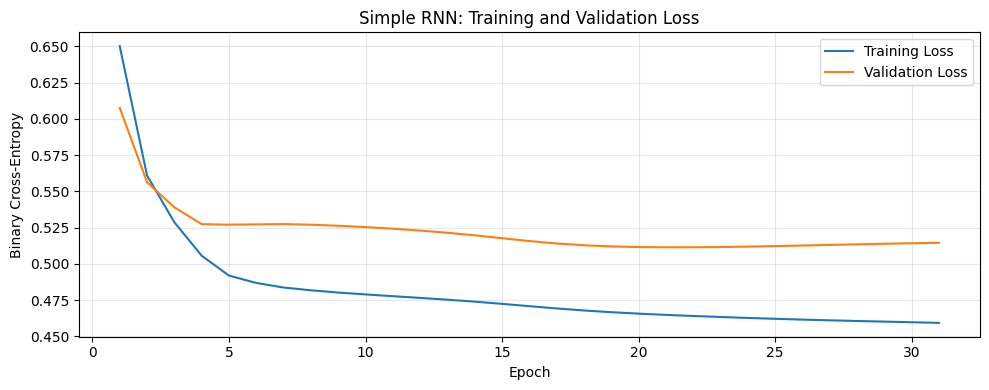

In [21]:
# Convert the training history to a DataFrame.
history_df = pd.DataFrame(rnn_history.history)

# Create an epoch index beginning at one.
history_df.index = np.arange(1, len(history_df) + 1)

# Create a figure for training and validation loss.
plt.figure(figsize=(10, 4))

# Plot the training loss.
plt.plot(
    history_df.index,
    history_df["loss"],
    label="Training Loss",
)

# Plot the validation loss.
plt.plot(
    history_df.index,
    history_df["val_loss"],
    label="Validation Loss",
)

# Label the axes.
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")

# Add a title and legend.
plt.title("Simple RNN: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

And another plot for accurcay:

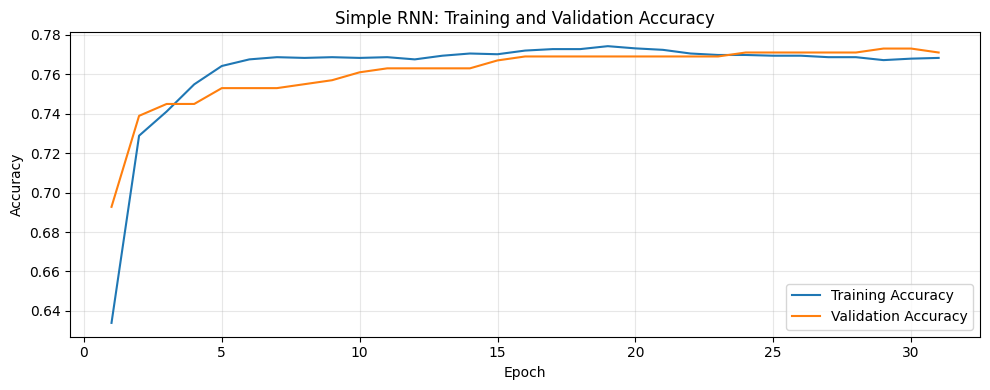

In [22]:
# Create a figure for training and validation accuracy.
plt.figure(figsize=(10, 4))

# Plot training accuracy.
plt.plot(
    history_df.index,
    history_df["accuracy"],
    label="Training Accuracy",
)

# Plot validation accuracy.
plt.plot(
    history_df.index,
    history_df["val_accuracy"],
    label="Validation Accuracy",
)

# Label the axes.
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Add a title and legend.
plt.title("Simple RNN: Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

#### 3.6.1 Interpretation of Training History

The Simple RNN exhibits rapid initial learning, with both training and validation binary cross-entropy decreasing substantially during the first few epochs.

The validation loss subsequently improves more gradually, reaching its minimum near epoch 21 at approximately $0.5115$.

Beyond this point, training loss continues to decrease while validation loss begins to increase, suggesting the onset of overfitting.

The early-stopping mechanism terminates training after 31 epochs and restores the weights corresponding to the minimum validation loss.

Training and validation accuracy both stabilize near $77\%$. However, accuracy alone is insufficient for evaluating our volatility-increase classification problem because the positive class is relatively infrequent.

Furthermore, validation accuracy can remain nearly constant even when validation cross-entropy increases, since cross-entropy evaluates predicted probabilities rather than only binary decisions.

We therefore proceed to evaluate precision, recall, F1-score, balanced accuracy, and probability-based classification metrics before comparing the RNN with the classical ARMA baseline.

### 3.7 Validation Classification Performance
First, obtain the predicted probabilities and apply the initial threshold of \(0.5\).

In [23]:
# Generate predicted probabilities on the validation set.
rnn_val_prob = rnn_model.predict(X_val, verbose=0).ravel()

# Define the initial classification decision threshold.
RNN_THRESHOLD = 0.5

# Convert probabilities into binary predictions.
rnn_val_pred = (rnn_val_prob > RNN_THRESHOLD).astype(int)

# Display the observed positive-class proportion.
print(f"Actual positive rate: {y_val.mean():.2%}")

# Display the predicted positive-class proportion.
print(f"Predicted positive rate: {rnn_val_pred.mean():.2%}")

# Inspect the first ten predicted probabilities.
print("First ten predicted probabilities:")
print(np.round(rnn_val_prob[:10], 4))

Actual positive rate: 25.30%
Predicted positive rate: 4.62%
First ten predicted probabilities:
[0.4052 0.3951 0.2787 0.1943 0.117  0.1612 0.1573 0.1509 0.1963 0.322 ]


then calculate the classification metrics

In [24]:
# Evaluate the Simple RNN on the validation set.
rnn_val_metrics = {
    "Accuracy": accuracy_score(y_val, rnn_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val, rnn_val_pred),
    "Precision": precision_score(y_val, rnn_val_pred, zero_division=0),
    "Recall": recall_score(y_val, rnn_val_pred, zero_division=0),
    "F1": f1_score(y_val, rnn_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, rnn_val_prob),
    "PR-AUC": average_precision_score(y_val, rnn_val_prob),
    "Log Loss": log_loss(y_val, rnn_val_prob),
}

# Display the evaluation results.
display(
    pd.DataFrame(
        rnn_val_metrics.items(),
        columns=["Metric", "Simple RNN"],
    )
)

# Display the confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_val, rnn_val_pred, labels=[0, 1]))

,Metric,Simple RNN
0,Accuracy,0.769076
1,Balanced Accuracy,0.559396
2,Precision,0.739130
3,Recall,0.134921
4,F1,0.228188
5,ROC-AUC,0.744133
6,PR-AUC,0.522532
7,Log Loss,0.511453


Confusion Matrix:
[[366   6]
 [109  17]]


#### 3.7.1 Experiment with different thresholds

In [25]:
# Define candidate probability thresholds.
thresholds = np.arange(0.1, 0.91, 0.05)

# Store the classification results.
threshold_results = []

# Evaluate each candidate threshold.
for threshold in thresholds:

    # Convert predicted probabilities to binary labels.
    predictions = (rnn_val_prob > threshold).astype(int)

    # Record classification performance.
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Predicted Positive Rate": predictions.mean(),
    })

# Construct a comparison table.
threshold_df = pd.DataFrame(threshold_results)

# Display the results.
display(threshold_df)

,Threshold,Precision,Recall,F1,Balanced Accuracy,Predicted Positive Rate
0,0.10,0.359712,0.793651,0.495050,0.657578,0.558233
1,0.15,0.401786,0.714286,0.514286,0.677035,0.449799
2,0.20,0.455090,0.603175,0.518771,0.679275,0.335341
3,0.25,0.500000,0.484127,0.491935,0.660074,0.244980
4,0.30,0.547368,0.412698,0.470588,0.648554,0.190763
5,0.35,0.616438,0.357143,0.452261,0.640937,0.146586
6,0.40,0.730769,0.301587,0.426966,0.631976,0.104418
7,0.45,0.648649,0.190476,0.294479,0.577765,0.074297
8,0.50,0.739130,0.134921,0.228188,0.559396,0.046185
9,0.55,0.722222,0.103175,0.180556,0.544867,0.036145


Save the selected threshold programmatically:

In [26]:
# Find the row with the highest validation F1-score.
best_threshold_row = threshold_df.loc[threshold_df["F1"].idxmax()]

# Store the selected decision threshold.
best_rnn_threshold = float(best_threshold_row["Threshold"])

# Display the selected threshold and associated metrics.
print(f"Selected RNN threshold: {best_rnn_threshold:.2f}")
print(f"Validation F1: {best_threshold_row['F1']:.4f}")
print(f"Validation balanced accuracy: {best_threshold_row['Balanced Accuracy']:.4f}")

Selected RNN threshold: 0.20
Validation F1: 0.5188
Validation balanced accuracy: 0.6793


#### 3.7.2 Generate the selected predictions

In [27]:
# Apply the validation-selected threshold.
rnn_val_pred_best = (
    rnn_val_prob > best_rnn_threshold
).astype(int)

# Display the resulting confusion matrix.
print(confusion_matrix(y_val, rnn_val_pred_best, labels=[0, 1]))

[[281  91]
 [ 50  76]]



### 3.7.3 Effect of the Classification Threshold

We investigated the sensitivity of the Simple RNN classifier to the probability decision threshold $\tau$.

Although $\tau=0.5$ produced an accuracy of approximately $76.9\%$, the corresponding recall was only $13.5\%$, indicating that the classifier missed most positive volatility-increase events.

We therefore evaluated thresholds between $0.10$ and $0.90$ using the validation dataset.

Among the tested values, the threshold $\tau=0.20$ maximized both the F1-score and balanced accuracy, giving

$$
\mathrm{F1}\approx0.5188,
\qquad
\mathrm{BalancedAccuracy}\approx0.6793.
$$

At this threshold, precision and recall were approximately

$$
\mathrm{Precision}\approx0.455,
\qquad
\mathrm{Recall}\approx0.603.
$$

The resulting F1-score exceeds the ARMA(1,1) validation F1-score of approximately $0.4504$.

This improvement suggests that the RNN's learned representations provide useful information for detecting volatility-increase events.

However, the threshold was selected using validation performance. Consequently, these results should be treated as model-selection evidence rather than an unbiased estimate of generalization performance.

The final selected threshold must be fixed before evaluation on the held-out test dataset.


### 3.8 Visualize the threshold tradeoff

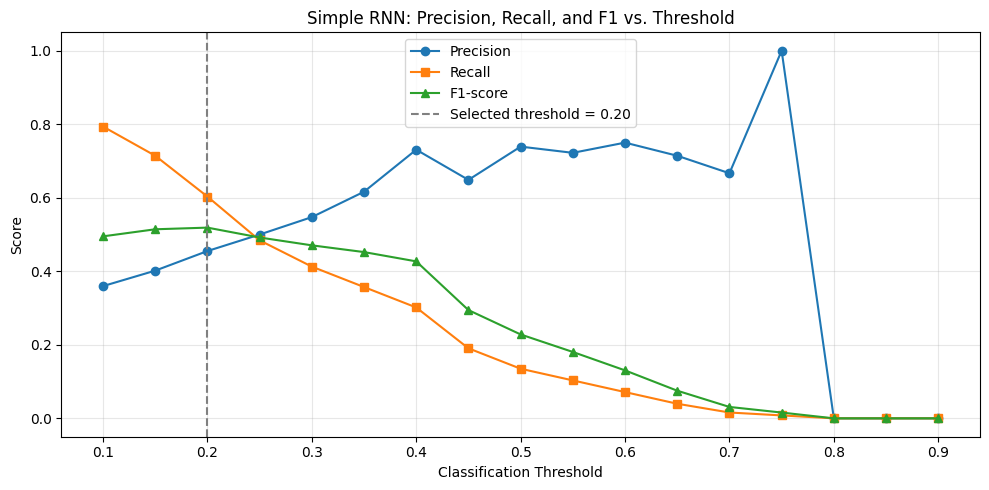

In [28]:
# Create a figure for threshold sensitivity.
plt.figure(figsize=(10, 5))

# Plot precision across classification thresholds.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision",
)

# Plot recall across classification thresholds.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="s",
    label="Recall",
)

# Plot F1-score across classification thresholds.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="^",
    label="F1-score",
)

# Mark the validation-selected threshold.
plt.axvline(
    best_rnn_threshold,
    linestyle="--",
    color="gray",
    label=f"Selected threshold = {best_rnn_threshold:.2f}",
)

# Label the axes.
plt.xlabel("Classification Threshold")
plt.ylabel("Score")

# Add the plot title.
plt.title("Simple RNN: Precision, Recall, and F1 vs. Threshold")

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()


### 3.9 Saving the Simple RNN Baseline

We have completed our initial Simple RNN experiment.

The model uses:

- Three input features: daily log returns, squared returns, and 20-day historical volatility.
- A lookback window of 20 trading days.
- A Simple RNN layer with 16 hidden units.
- A sigmoid output for binary classification.
- Binary cross-entropy as the training objective.
- Early stopping based on validation loss.

The validation-selected classification threshold is

$$
\tau^*=0.20.
$$

At this threshold, the model achieves approximately

$$
\mathrm{F1}=0.5188,
\qquad
\mathrm{BalancedAccuracy}=0.6793.
$$

We save the trained model and preprocessing objects to ensure that future comparisons with LSTM, GRU, and other architectures use reproducible experimental configurations.

The test dataset remains reserved for final evaluation.


In [29]:
# Import JSON serialization utilities.
import json

# Import joblib for saving the fitted scaler.
import joblib

# Define the output directory for the Simple RNN.
rnn_model_dir = PROJECT_ROOT / "models" / "sequence_rnn"

# Create the directory if it does not exist.
rnn_model_dir.mkdir(parents=True, exist_ok=True)

# Define the output directory for validation results.
rnn_results_dir = PROJECT_ROOT / "results" / "sequence_rnn"

# Create the results directory.
rnn_results_dir.mkdir(parents=True, exist_ok=True)

# Save the trained Keras model, including its weights.
rnn_model.save(rnn_model_dir / "simple_rnn.keras")

# Save the fitted feature scaler.
joblib.dump(scaler, rnn_model_dir / "feature_scaler.joblib")

# Construct the experiment configuration.
rnn_config = {
    "model": "SimpleRNN",
    "lookback": int(LOOKBACK),
    "features": list(feature_columns),
    "hidden_units": int(RNN_UNITS),
    "selected_threshold": float(best_rnn_threshold),
    "selection_metric": "validation_f1",
    "training_end": str(dates_train.max().date()),
    "validation_start": str(dates_val.min().date()),
    "validation_end": str(dates_val.max().date()),
}

# Save the experiment configuration as JSON.
with open(rnn_model_dir / "config.json", "w") as file:
    json.dump(rnn_config, file, indent=4)

# Construct a table of validation predictions.
rnn_validation_results = pd.DataFrame(
    {
        "date": dates_val,
        "actual_label": y_val,
        "predicted_probability": rnn_val_prob,
        "predicted_label": rnn_val_pred_best,
    }
)

# Save the validation predictions.
rnn_validation_results.to_csv(
    rnn_results_dir / "validation_predictions.csv",
    index=False,
)

# Save the threshold sensitivity results.
threshold_df.to_csv(
    rnn_results_dir / "threshold_analysis.csv",
    index=False,
)

# Save the training history.
history_df.to_csv(
    rnn_results_dir / "training_history.csv",
    index_label="epoch",
)

# Confirm successful saving.
print("Simple RNN model and experiment artifacts saved.")

Simple RNN model and experiment artifacts saved.


### 3.10 Comparison with the Classical ARMA Baseline

We compare the Simple RNN with the ARMA(1,1) baseline developed in `10_classical_time_series_baseline.ipynb`.

Both models are evaluated on the same 498 validation dates and use the same binary volatility-increase target.

| Metric | ARMA(1,1) | Simple RNN |
|---|---:|---:|
| Accuracy | 0.7108 | 0.7169 |
| Balanced accuracy | 0.6306 | 0.6793 |
| Precision | 0.4338 | 0.4551 |
| Recall | 0.4683 | 0.6032 |
| F1-score | 0.4504 | 0.5188 |

The Simple RNN achieves higher validation F1-score, balanced accuracy, and recall.

The two approaches differ fundamentally:

- ARMA forecasts future volatility indirectly through a model of squared returns.
- The RNN directly learns a mapping from historical feature sequences to binary volatility-increase labels.

The results suggest that nonlinear sequence representations may improve the detection of volatility-increase events.

However, the RNN decision threshold was selected using validation labels, so its reported validation performance is not an unbiased estimate of future generalization.

We reserve the test dataset for the final comparison of selected models.

## 4. Long Short-Term Memory (LSTM)

### 4.1 Motivation: Vanishing and Exploding Gradients

A Simple RNN computes hidden states recursively:

$$
\mathbf h_t
=
\tanh(W_{xh}\mathbf x_t+W_{hh}\mathbf h_{t-1}+\mathbf b_h).
$$

Although the hidden state can theoretically depend on observations from many earlier time steps, learning long-range dependencies can be difficult.

This is related to the **vanishing-gradient** and **exploding-gradient** problems.

#### A Simple Mathematical Example

Consider the scalar linear recurrence

$$
h_t=wh_{t-1}.
$$

After $T$ steps,

$$
h_T=w^T h_0.
$$

Therefore,

$$
\boxed{
\frac{\partial h_T}{\partial h_0}=w^T.
}
$$

If $|w|<1$, then

$$
\lim_{T\to\infty}|w|^T=0.
$$

Thus, the influence of the initial hidden state becomes increasingly small.

If $|w|>1$, then

$$
\lim_{T\to\infty}|w|^T=\infty.
$$

In this case, gradients can grow rapidly.

For nonlinear, vector-valued RNNs, backpropagation involves products of Jacobian matrices:

$$
\frac{\partial \mathbf h_T}{\partial \mathbf h_k}
=
\frac{\partial \mathbf h_T}{\partial \mathbf h_{T-1}}
\cdots
\frac{\partial \mathbf h_{k+1}}{\partial \mathbf h_k}.
$$

Repeated multiplication can cause gradients to become extremely small or large.

#### Why This Matters for Financial Time Series

Our initial Simple RNN uses a lookback window of 20 trading days.

However, volatility dynamics may depend on patterns occurring over longer periods, such as prolonged market turbulence or transitions between volatility regimes.

A Simple RNN may struggle to preserve relevant information across many recurrent steps.

An LSTM introduces a separate cell state and gating mechanisms that make it easier to preserve and update information over longer sequences.

LSTMs do not completely eliminate gradient-related difficulties, but their architecture provides a more effective mechanism for learning long-range dependencies.

#### Exercise

1. For $w=0.5$, calculate $\partial h_{10}/\partial h_0$.
2. Repeat for $w=1.2$.
3. Explain why very small gradients can make it difficult to learn relationships involving distant observations.
4. Give an example of a financial time series where information from several weeks earlier might be relevant to a prediction today.



### 4.2 Architecture of an LSTM Cell

An LSTM maintains two state vectors:

1. The **hidden state** $\mathbf h_t$, representing information exposed at time $t$.
2. The **cell state** $\mathbf c_t$, providing a memory pathway across time steps.

At time $t$, the LSTM receives the current input $\mathbf x_t$, previous hidden state $\mathbf h_{t-1}$, and previous cell state $\mathbf c_{t-1}$.

#### Forget Gate

The forget gate controls retention of previous memory:

$$
\boxed{
\mathbf f_t=\sigma(W_f[\mathbf h_{t-1};\mathbf x_t]+\mathbf b_f).
}
$$

Here $\sigma$ is the sigmoid function and $[\cdot;\cdot]$ denotes vector concatenation.

Each component of $\mathbf f_t$ lies between $0$ and $1$.

#### Input Gate

The input gate determines how much new information enters memory:

$$
\boxed{
\mathbf i_t=\sigma(W_i[\mathbf h_{t-1};\mathbf x_t]+\mathbf b_i).
}
$$

The candidate cell state is

$$
\boxed{
\widetilde{\mathbf c}_t
=
\tanh(W_c[\mathbf h_{t-1};\mathbf x_t]+\mathbf b_c).
}
$$

#### Cell-State Update

The updated cell state combines retained memory and new information:

$$
\boxed{
\mathbf c_t
=
\mathbf f_t\odot\mathbf c_{t-1}
+
\mathbf i_t\odot\widetilde{\mathbf c}_t.
}
$$

The operation $\odot$ denotes componentwise multiplication.

This additive memory update helps the LSTM retain information and propagate gradients across time.

#### Output Gate

The output gate determines how much information from the updated cell state is exposed:

$$
\boxed{
\mathbf o_t=\sigma(W_o[\mathbf h_{t-1};\mathbf x_t]+\mathbf b_o).
}
$$

The hidden state becomes

$$
\boxed{
\mathbf h_t=\mathbf o_t\odot\tanh(\mathbf c_t).
}
$$

### 4.3 A Numerical Example

Consider a scalar LSTM cell with

$$
c_{t-1}=0.8,\quad
f_t=0.9,\quad
i_t=0.3,\quad
\widetilde c_t=0.5,\quad
o_t=0.7.
$$

The updated memory is

$$
\begin{aligned}
c_t
&=f_tc_{t-1}+i_t\widetilde c_t\\
&=(0.9)(0.8)+(0.3)(0.5)\\
&=\boxed{0.87}.
\end{aligned}
$$

The hidden state is

$$
\begin{aligned}
h_t
&=o_t\tanh(c_t)\\
&=0.7\tanh(0.87)\\
&\approx\boxed{0.491}.
\end{aligned}
$$

The forget gate retains most of the previous memory, while the input gate allows a smaller contribution from the candidate memory.

**Non-example:** A conventional Simple RNN update,

$$
\mathbf h_t=\tanh(W_x\mathbf x_t+W_h\mathbf h_{t-1}+\mathbf b),
$$

is not an LSTM update because it has no separate cell state or learned memory gates.

### Exercises

1. Repeat the numerical example with $f_t=0.2$, keeping all other values unchanged. What happens to the cell state?
2. What happens when $f_t=1$ and $i_t=0$?
3. Construct another example in which the LSTM almost completely replaces its previous memory.
4. Explain why the cell-state update may help reduce the vanishing-gradient problem.



### 4.4 Building an LSTM Classifier with TensorFlow/Keras

We now implement an LSTM classifier for predicting volatility-increase events using historical SPY observations.

Our input sequences have the form

$$
X_t=(\mathbf x_{t-19},\ldots,\mathbf x_t),
$$

where

$$
\mathbf x_t=
\begin{pmatrix}
r_t\\
r_t^2\\
Vol_{20,t}
\end{pmatrix}.
$$

Each sequence contains 20 trading days and three standardized features.

Our target is the same binary variable used in the Simple RNN experiment:

$$
y_t=
\mathbf 1\left\{
\log\left(\frac{RV_{t,t+5}}{Vol_{20,t}}\right)>0.2
\right\}.
$$

We construct a sequence-to-one classifier:

$$
X_t
\xrightarrow{\mathrm{LSTM}}
\mathbf h_t
\xrightarrow{\mathrm{Dense+Sigmoid}}
\widehat p_t,
$$

where

$$
\widehat p_t=P(y_t=1\mid X_t)
$$

is the model's estimated probability of a volatility-increase event.

The initial architecture consists of:

1. An input layer accepting tensors of shape $(20,3)$.
2. An LSTM layer with 16 hidden units.
3. A dense output layer with one sigmoid-activated neuron.

We use binary cross-entropy as the loss function:

$$
\mathcal L
=
-\frac1N\sum_{i=1}^{N}
\left[
y_i\log(\widehat p_i)
+
(1-y_i)\log(1-\widehat p_i)
\right].
$$

For a controlled comparison with the Simple RNN, we retain the same input data, training configuration, and early-stopping strategy.

The LSTM architecture has more trainable parameters than a Simple RNN with the same number of hidden units, because it contains four sets of recurrent transformations.

Our immediate goal is to establish a baseline LSTM model before conducting any hyperparameter optimization.


#### 4.4.1 Construct the LSTM model

In [30]:
# Set the number of LSTM hidden units.
LSTM_UNITS = 16

# Construct the LSTM classification model.
lstm_model = tf.keras.Sequential(
    [
        # Define the expected sequence dimensions.
        tf.keras.layers.Input(
            shape=(LOOKBACK, len(feature_columns))
        ),

        # Process the input sequence with an LSTM layer.
        tf.keras.layers.LSTM(
            units=LSTM_UNITS,
        ),

        # Convert the final hidden state into a binary probability.
        tf.keras.layers.Dense(
            units=1,
            activation="sigmoid",
        ),
    ],
    name="SPY_LSTM_Classifier",
)

# Display the model architecture and parameter counts.
lstm_model.summary()

Model: "SPY_LSTM_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297 (5.07 KB)

 Trainable params: 1,297 (5.07 KB)

 Non-trainable params: 0 (0.00 B)

#### 4.4.2 Compile the model

In [31]:
# Compile the LSTM model for binary classification.
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# Confirm the model is ready for training.
print("LSTM model compiled successfully.")

LSTM model compiled successfully.


#### 4.4.3 Configure early stopping

In [32]:
# Configure early stopping based on validation loss.
lstm_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

# Display the early-stopping configuration.
print("Early stopping configured.")

Early stopping configured.


#### 4.4.4 Train the LSTM model

In [33]:
# Train the LSTM classifier.
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[lstm_early_stopping],
    shuffle=False,
    verbose=1,
)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6194 - loss: 0.6511 - val_accuracy: 0.7470 - val_loss: 0.5633
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7471 - loss: 0.5403 - val_accuracy: 0.7470 - val_loss: 0.5470
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7471 - loss: 0.5226 - val_accuracy: 0.7470 - val_loss: 0.5380
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7471 - loss: 0.5108 - val_accuracy: 0.7470 - val_loss: 0.5265
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7479 - loss: 0.5004 - val_accuracy: 0.7470 - val_loss: 0.5152
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7542 - loss: 0.4913 - val_accuracy: 0.7470 - val_loss: 0.5058
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7564 - loss: 0.4840 - val_accuracy: 0.7590 - val_loss: 0.4995
Epoch 8/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7605 - loss: 0.4784 - val_accuracy: 0.7610 - v

### 4.5 Inspect the training history

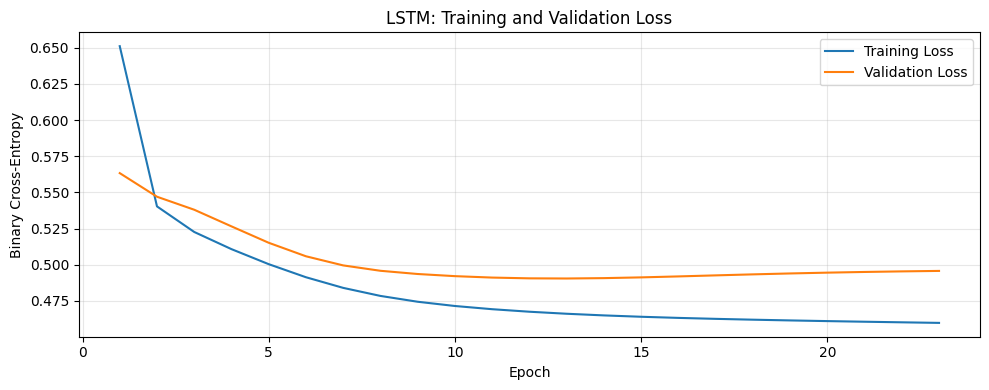

In [34]:
# Convert the LSTM training history to a DataFrame.
lstm_history_df = pd.DataFrame(lstm_history.history)

# Number the training epochs starting from one.
lstm_history_df.index = np.arange(1, len(lstm_history_df) + 1)

# Create a figure for the training and validation losses.
plt.figure(figsize=(10, 4))

# Plot the training loss.
plt.plot(
    lstm_history_df.index,
    lstm_history_df["loss"],
    label="Training Loss",
)

# Plot the validation loss.
plt.plot(
    lstm_history_df.index,
    lstm_history_df["val_loss"],
    label="Validation Loss",
)

# Label the axes.
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")

# Add a title and legend.
plt.title("LSTM: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

get the epoch with the lowest validation loss:

In [35]:
# Identify the epoch with the lowest validation loss.
best_lstm_epoch = lstm_history_df["val_loss"].idxmin()

# Retrieve the minimum validation loss.
best_lstm_val_loss = lstm_history_df["val_loss"].min()

# Display the results.
print(f"Best LSTM epoch: {best_lstm_epoch}")
print(f"Minimum validation loss: {best_lstm_val_loss:.4f}")

Best LSTM epoch: 13
Minimum validation loss: 0.4905



### 4.6 LSTM Validation Classification Performance

The LSTM achieved its minimum validation binary cross-entropy of approximately $0.4905$ at epoch $13$.

Although this is lower than the minimum validation loss of our Simple RNN, a lower cross-entropy does not necessarily imply better classification performance at a fixed decision threshold.

We therefore evaluate the LSTM on the same $498$ validation observations used for the Simple RNN and ARMA(1,1).

We begin with the conventional probability decision threshold $\tau=0.5$, then investigate how classification performance changes with $\tau$.

As before, the decision threshold $\tau$ must be distinguished from the $0.2$ threshold appearing in the definition of the binary volatility-increase target.


#### 4.6.1 General predicted probabilities

In [36]:
# Generate LSTM predicted probabilities on the validation dataset.
lstm_val_prob = lstm_model.predict(X_val, verbose=0).ravel()

# Define the initial probability decision threshold.
LSTM_THRESHOLD = 0.5

# Convert predicted probabilities into binary classifications.
lstm_val_pred = (lstm_val_prob > LSTM_THRESHOLD).astype(int)

# Display the observed positive-class proportion.
print(f"Actual positive rate: {y_val.mean():.2%}")

# Display the predicted positive-class proportion.
print(f"Predicted positive rate: {lstm_val_pred.mean():.2%}")

# Inspect the first ten predicted probabilities.
print("First ten predicted probabilities:")
print(np.round(lstm_val_prob[:10], 4))

Actual positive rate: 25.30%
Predicted positive rate: 6.22%
First ten predicted probabilities:
[0.3847 0.3062 0.2608 0.1463 0.1163 0.1541 0.1598 0.158  0.1947 0.293 ]


#### 4.6.2 Evaluate classification metrics

In [37]:
# Calculate validation classification metrics.
lstm_val_metrics = {
    "Accuracy": accuracy_score(y_val, lstm_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val, lstm_val_pred),
    "Precision": precision_score(y_val, lstm_val_pred, zero_division=0),
    "Recall": recall_score(y_val, lstm_val_pred, zero_division=0),
    "F1": f1_score(y_val, lstm_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, lstm_val_prob),
    "PR-AUC": average_precision_score(y_val, lstm_val_prob),
    "Log Loss": log_loss(y_val, lstm_val_prob),
}

# Display the evaluation metrics as a table.
display(
    pd.DataFrame(
        lstm_val_metrics.items(),
        columns=["Metric", "LSTM"],
    )
)

# Display the confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_val, lstm_val_pred, labels=[0, 1]))

,Metric,LSTM
0,Accuracy,0.777108
1,Balanced Accuracy,0.580517
2,Precision,0.741935
3,Recall,0.182540
4,F1,0.292994
5,ROC-AUC,0.768945
6,PR-AUC,0.565078
7,Log Loss,0.490476


Confusion Matrix:
[[364   8]
 [103  23]]



#### 4.6.3 Threshold Sensitivity Analysis

At the initial probability threshold $\tau=0.5$, the LSTM achieves a validation F1-score of approximately $0.2930$.

However, its recall is only $0.1825$, meaning that most positive volatility-increase events are not identified.

We therefore investigate how the classification metrics change as the probability threshold varies.

For consistency with the Simple RNN experiment, we evaluate thresholds from $0.10$ to $0.90$ in increments of $0.05$.

We select the threshold maximizing validation F1-score:

$$
\tau_{\mathrm{LSTM}}^*
=
\underset{\tau\in\mathcal T}{\operatorname{argmax}}
\ \mathrm{F1}_{\mathrm{validation}}(\tau),
$$

where

$$
\mathcal T=\{0.10,0.15,\ldots,0.90\}.
$$

This threshold is selected using validation data only. The held-out test dataset remains untouched.


In [38]:
# Define the candidate classification thresholds.
lstm_thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

# Initialize a list for threshold evaluation results.
lstm_threshold_results = []

# Evaluate each candidate threshold.
for threshold in lstm_thresholds:

    # Convert probabilities into binary predictions.
    predictions = (lstm_val_prob > threshold).astype(int)

    # Record classification metrics.
    lstm_threshold_results.append(
        {
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "Predicted Positive Rate": predictions.mean(),
        }
    )

# Construct the threshold comparison table.
lstm_threshold_df = pd.DataFrame(lstm_threshold_results)

# Display the results.
display(lstm_threshold_df)

,Threshold,Precision,Recall,F1,Balanced Accuracy,Predicted Positive Rate
0,0.10,0.363636,0.825397,0.504854,0.668075,0.574297
1,0.15,0.409692,0.738095,0.526912,0.688940,0.455823
2,0.20,0.455056,0.642857,0.532895,0.691052,0.357430
3,0.25,0.525926,0.563492,0.544061,0.695725,0.271084
4,0.30,0.594340,0.500000,0.543103,0.692204,0.212851
5,0.35,0.641975,0.412698,0.502415,0.667371,0.162651
6,0.40,0.639344,0.309524,0.417112,0.625192,0.122490
7,0.45,0.695652,0.253968,0.372093,0.608167,0.092369
8,0.50,0.741935,0.182540,0.292994,0.580517,0.062249
9,0.55,0.800000,0.126984,0.219178,0.558116,0.040161


Select the best threshold:

In [39]:
# Find the threshold maximizing validation F1.
best_lstm_row = lstm_threshold_df.loc[
    lstm_threshold_df["F1"].idxmax()
]

# Store the selected threshold.
best_lstm_threshold = float(best_lstm_row["Threshold"])

# Generate predictions using the selected threshold.
lstm_val_pred_best = (
    lstm_val_prob > best_lstm_threshold
).astype(int)

# Display the selected threshold and validation performance.
print(f"Selected LSTM threshold: {best_lstm_threshold:.2f}")
print(f"Validation F1: {best_lstm_row['F1']:.4f}")
print(
    "Validation balanced accuracy: "
    f"{best_lstm_row['Balanced Accuracy']:.4f}"
)

# Display the confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_val, lstm_val_pred_best, labels=[0, 1]))

Selected LSTM threshold: 0.25
Validation F1: 0.5441
Validation balanced accuracy: 0.6957
Confusion Matrix:
[[308  64]
 [ 55  71]]



#### 4.6.4 Interpretation of the LSTM Classification Results

We evaluated the LSTM classifier using probability thresholds between $0.10$ and $0.90$.

The threshold maximizing validation F1-score was

$$
\tau_{\mathrm{LSTM}}^*=0.25.
$$

At this threshold, the LSTM achieved

$$
\mathrm{F1}\approx 0.5441,
\qquad
\mathrm{BalancedAccuracy}\approx 0.6957.
$$

The confusion matrix was

$$
\begin{pmatrix}
308 & 64\\
55 & 71
\end{pmatrix}.
$$

Thus, the model correctly identified $71$ of the $126$ positive volatility-increase events, giving

$$
\mathrm{Precision}\approx 0.5259,
\qquad
\mathrm{Recall}\approx 0.5635.
$$

The LSTM outperformed both the Simple RNN and ARMA(1,1) in validation F1-score and balanced accuracy.

The selected threshold differs from that of the Simple RNN ($0.20$). This is expected because the models produce different probability distributions, and their optimal classification thresholds need not coincide.

**Limitations.** The threshold was selected using validation data. Therefore, these results are useful for model selection but do not constitute an unbiased estimate of out-of-sample performance.

The held-out test dataset will be evaluated only after the model architectures, hyperparameters, and classification thresholds have been finalized.


### 4.7 Hyperparameter Tuning of the LSTM

Our initial LSTM classifier used $16$ hidden units and a lookback window of $20$ trading days.

Although this configuration achieved a validation F1-score of approximately $0.5441$, these hyperparameters were not optimized.

We now investigate how the architecture and training configuration affect predictive performance.

#### 4.7.1 Effect of the Number of LSTM Units

The hidden-state dimension $h$ determines the number of features that the LSTM can retain in its recurrent representation.

For input dimension $d$, a standard LSTM layer has

$$
N_{\mathrm{LSTM}}=4h(d+h+1)
$$

trainable parameters.

We consider

$$
h\in\{8,16,32,64\}.
$$

For each configuration, we will:

1. Train an LSTM using the same training and validation datasets.
2. Restore the weights corresponding to the minimum validation loss.
3. Generate validation probabilities.
4. Select the classification threshold maximizing validation F1-score.
5. Record F1-score, balanced accuracy, ROC-AUC, PR-AUC, and validation log loss.

All other hyperparameters will initially remain unchanged.

The objective is to determine whether increasing model capacity improves volatility-increase classification, or whether a smaller recurrent representation generalizes better.


In [41]:
# Define the candidate numbers of LSTM units.
lstm_units_list = [8, 16, 32, 64]

# Store the experiment results.
lstm_units_results = []

# Store trained models for later inspection.
lstm_tuned_models = {}

# Set the random seed for reproducibility.
tf.keras.utils.set_random_seed(42)

# Iterate over the candidate hidden-state dimensions.
for units in lstm_units_list:

    # Clear the previous Keras computational graph.
    tf.keras.backend.clear_session()

    # Reset the random seed for this experiment.
    tf.keras.utils.set_random_seed(42)

    # Construct the LSTM classifier.
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=X_train.shape[1:]),
        tf.keras.layers.LSTM(units),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    # Compile the model.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Stop training when validation loss stops improving.
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    # Train the model.
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Generate validation probabilities.
    probabilities = model.predict(X_val, verbose=0).ravel()

    # Search for the best classification threshold.
    thresholds = np.arange(0.10, 0.91, 0.05)

    # Calculate F1 at every candidate threshold.
    f1_values = [
        f1_score(
            y_val,
            (probabilities > threshold).astype(int),
            zero_division=0
        )
        for threshold in thresholds
    ]

    # Select the threshold with maximum validation F1.
    best_index = np.argmax(f1_values)

    # Retrieve the selected threshold.
    best_threshold = float(thresholds[best_index])

    # Construct the selected binary predictions.
    predictions = (probabilities > best_threshold).astype(int)

    # Record the experiment results.
    lstm_units_results.append({
        "Units": units,
        "Parameters": model.count_params(),
        "Best Epoch": np.argmin(history.history["val_loss"]) + 1,
        "Validation Loss": min(history.history["val_loss"]),
        "Threshold": best_threshold,
        "F1": f1_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

    # Store the trained model.
    lstm_tuned_models[units] = model

# Construct the comparison table.
lstm_units_df = pd.DataFrame(lstm_units_results)

# Display results ordered by validation F1.
display(lstm_units_df.sort_values("F1", ascending=False))

,Units,Parameters,Best Epoch,Validation Loss,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC
1,16,1297,36,0.461155,0.25,0.598639,0.741679,0.806388,0.565209
3,64,17473,15,0.473766,0.20,0.586572,0.729903,0.804724,0.556593
0,8,393,29,0.483765,0.20,0.555184,0.708397,0.783005,0.552409
2,32,4641,10,0.485083,0.15,0.550725,0.710317,0.779698,0.541570



#### 4.7.2 Stability Across Random Seeds

Neural-network training depends on random initialization and, potentially, the ordering of training batches.

Consequently, the performance of a particular architecture can vary between training runs.

We investigate the stability of our two strongest configurations:

$$
h\in\{16,64\}.
$$

For each configuration, we repeat training using three random seeds:

$$
s\in\{42,123,2026\}.
$$

For each run, we restore the weights corresponding to the minimum validation loss and evaluate the model on the validation dataset.

We report the mean and standard deviation of F1-score, ROC-AUC, and validation log loss.

The objective is to determine whether the apparent advantage of the 16-unit LSTM is consistent across different random initializations.

The held-out test dataset remains unused.


In [42]:

# Define the LSTM configurations.
units_list = [16, 64]

# Define the random seeds.
seeds = [42, 123, 2026]

# Store results from all experiments.
stability_results = []

# Iterate over the hidden-state dimensions.
for units in units_list:

    # Repeat the experiment with different seeds.
    for seed in seeds:

        # Clear the previous Keras session.
        tf.keras.backend.clear_session()

        # Set the random seed.
        tf.keras.utils.set_random_seed(seed)

        # Construct the LSTM classifier.
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=X_train.shape[1:]),
            tf.keras.layers.LSTM(units),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        # Compile the model.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        # Define early stopping.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the model.
        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(X_val, verbose=0).ravel()

        # Define candidate classification thresholds.
        thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)

        # Calculate F1 for every threshold.
        f1_values = [
            f1_score(
                y_val,
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in thresholds
        ]

        # Select the threshold maximizing validation F1.
        best_index = np.argmax(f1_values)

        # Retrieve the selected threshold.
        best_threshold = float(thresholds[best_index])

        # Record the experiment results.
        stability_results.append({
            "Units": units,
            "Seed": seed,
            "Best Epoch": np.argmin(history.history["val_loss"]) + 1,
            "Threshold": best_threshold,
            "F1": f1_values[best_index],
            "ROC-AUC": roc_auc_score(y_val, probabilities),
            "PR-AUC": average_precision_score(y_val, probabilities),
            "Log Loss": log_loss(y_val, probabilities)
        })

# Construct a DataFrame containing all runs.
stability_df = pd.DataFrame(stability_results)

# Display the individual experiments.
display(stability_df)


,Units,Seed,Best Epoch,Threshold,F1,ROC-AUC,PR-AUC,Log Loss
0,16,42,36,0.25,0.598639,0.806388,0.565209,0.461155
1,16,123,19,0.25,0.575540,0.787421,0.539494,0.477825
2,16,2026,17,0.10,0.543478,0.767601,0.544648,0.501530
3,64,42,15,0.20,0.586572,0.804724,0.556593,0.473766
4,64,123,15,0.10,0.568365,0.791965,0.577602,0.477314
5,64,2026,12,0.20,0.569536,0.777052,0.553492,0.499454


#### 4.7.3 Interpretation of the Stability Experiment

We repeated the training of the 16-unit and 64-unit LSTM classifiers using three random seeds.

The 16-unit LSTM achieved the highest individual validation F1-score, approximately $0.5986$. However, its performance varied considerably across random initializations.

The 64-unit LSTM exhibited a smaller standard deviation in validation F1-score, suggesting greater stability in this limited experiment.

The mean F1-scores were approximately

$$
\overline{F1}_{16}=0.5726,
\qquad
\overline{F1}_{64}=0.5748.
$$

These values are very close, and three seeds are insufficient to establish a statistically reliable difference.

Moreover, the 16-unit model requires substantially fewer trainable parameters than the 64-unit model.

**Conclusion.** We retain 16 LSTM units as our provisional configuration because it offers competitive predictive performance at considerably lower computational cost.

This choice is provisional and will be revisited if subsequent experiments provide evidence favoring a larger architecture.

All results remain validation-set measurements; the held-out test dataset has not been used.



#### 4.7.4 Effect of Lookback Window Length

The lookback length $L$ determines how many historical trading days the LSTM receives when predicting the volatility-increase event at forecast origin $t$.

For $d$ features, the input sequence is

$$
X_t =
\begin{pmatrix}
\mathbf{x}_{t-L+1}\\
\mathbf{x}_{t-L+2}\\
\vdots\\
\mathbf{x}_t
\end{pmatrix}
\in\mathbb{R}^{L\times d}.
$$

We investigate

$$
L\in\{10,20,40,60\}.
$$

A shorter sequence may be sufficient to capture recent volatility changes, while a longer sequence may provide information about more persistent market regimes.

However, longer sequences also increase computational cost and may introduce irrelevant historical information.

We retain $16$ LSTM units and repeat each experiment using three random seeds.

**Experimental controls:**

1. Use the same three input features and training-fitted scaler.
2. Keep the chronological training, validation, and test boundaries unchanged.
3. Preserve the five-day purge at the training and validation boundaries.
4. Evaluate every configuration on identical validation forecast-origin dates.
5. Restore the model weights corresponding to minimum validation loss.
6. Select classification thresholds using validation data only.

The test dataset remains untouched.

Because longer lookback windows remove more observations at the beginning of the training period, we will use common training forecast origins across all configurations. This isolates the effect of lookback length from changes in the training sample.


Step 1: Construct a sequence for different lookback lengths:

In [43]:

# Define the candidate lookback lengths.
lookback_lengths = [10, 20, 40, 60]

# Identify the maximum lookback length.
max_lookback = max(lookback_lengths)

# Define the forecast horizon in trading days.
forecast_horizon = 5

# Retrieve the chronological dates.
all_dates = pd.DatetimeIndex(rnn_df.index)

# Define the last training date.
train_end = pd.Timestamp("2020-12-31")

# Define the last validation date.
val_end = pd.Timestamp("2022-12-31")

# Identify the training boundary in the complete date index.
train_boundary = all_dates.searchsorted(train_end, side="right")

# Identify the validation boundary in the complete date index.
val_boundary = all_dates.searchsorted(val_end, side="right")

# Use common training origins for all lookback lengths.
train_positions = np.arange(
    max_lookback - 1,
    train_boundary - forecast_horizon
)

# Use validation origins whose targets remain inside validation.
val_positions = np.arange(
    train_boundary,
    val_boundary - forecast_horizon
)

# Display the number of eligible forecast origins.
print("Common training origins:", len(train_positions))
print("Common validation origins:", len(val_positions))

Common training origins: 2645
Common validation origins: 498


Step 2: Build the sequence tensors

In [44]:

# Apply the existing training-fitted scaler to all historical features.
scaled_features = scaler.transform(rnn_df[feature_columns])

# Retrieve the binary classification targets.
all_targets = rnn_df[target_column].to_numpy(dtype=np.int64)

# Define a function to construct sequences at specified forecast origins.
def make_lookback_sequences(features, targets, positions, lookback):

    # Store the input sequences.
    X = []

    # Store the corresponding binary targets.
    y = []

    # Iterate over the selected forecast origins.
    for position in positions:

        # Extract the lookback observations ending at the forecast origin.
        sequence = features[position - lookback + 1:position + 1]

        # Append the input sequence.
        X.append(sequence)

        # Append the target corresponding to the forecast origin.
        y.append(targets[position])

    # Convert the sequences to a NumPy array.
    X = np.asarray(X, dtype=np.float32)

    # Convert the targets to a NumPy array.
    y = np.asarray(y, dtype=np.int64)

    # Return the constructed tensors.
    return X, y


# Store the datasets for different lookback lengths.
lookback_datasets = {}

# Iterate over the candidate lookback lengths.
for lookback in lookback_lengths:

    # Construct the training sequences.
    X_train_L, y_train_L = make_lookback_sequences(
        scaled_features,
        all_targets,
        train_positions,
        lookback
    )

    # Construct the validation sequences.
    X_val_L, y_val_L = make_lookback_sequences(
        scaled_features,
        all_targets,
        val_positions,
        lookback
    )

    # Store the tensors.
    lookback_datasets[lookback] = {
        "X_train": X_train_L,
        "y_train": y_train_L,
        "X_val": X_val_L,
        "y_val": y_val_L
    }

    # Display the tensor dimensions.
    print(
        f"L={lookback}: "
        f"Train {X_train_L.shape}, "
        f"Validation {X_val_L.shape}"
    )


L=10: Train (2645, 10, 3), Validation (498, 10, 3)
L=20: Train (2645, 20, 3), Validation (498, 20, 3)
L=40: Train (2645, 40, 3), Validation (498, 40, 3)
L=60: Train (2645, 60, 3), Validation (498, 60, 3)


Step 3: Verify alignment and absence of leakage

In [45]:

# Retrieve the reference targets for the shortest lookback.
reference_train_targets = lookback_datasets[10]["y_train"]

# Retrieve the reference validation targets.
reference_val_targets = lookback_datasets[10]["y_val"]

# Verify that all configurations use identical training targets.
for lookback in lookback_lengths:
    assert np.array_equal(
        lookback_datasets[lookback]["y_train"],
        reference_train_targets
    )

# Verify that all configurations use identical validation targets.
for lookback in lookback_lengths:
    assert np.array_equal(
        lookback_datasets[lookback]["y_val"],
        reference_val_targets
    )

# Verify that training targets end before the validation boundary.
assert train_positions[-1] + forecast_horizon < train_boundary

# Verify that validation targets end before the test boundary.
assert val_positions[-1] + forecast_horizon < val_boundary

# Verify that every input sequence has the correct feature dimension.
for lookback in lookback_lengths:
    assert lookback_datasets[lookback]["X_train"].shape[1:] == (
        lookback,
        len(feature_columns)
    )

# Display the common validation date range.
print("Validation begins:", all_dates[val_positions[0]])
print("Validation ends:", all_dates[val_positions[-1]])

# Display the number of validation observations.
print("Validation observations:", len(val_positions))


Validation begins: 2021-01-04 00:00:00
Validation ends: 2022-12-22 00:00:00
Validation observations: 498


Step 4: Train the LSTM model

In [46]:

# Define the random seeds.
lookback_seeds = [42, 123, 2026]

# Fix the number of LSTM units.
lstm_units = 16

# Store experiment results.
lookback_results = []

# Iterate over the lookback lengths.
for lookback in lookback_lengths:

    # Retrieve the dataset for this lookback length.
    dataset = lookback_datasets[lookback]

    # Repeat training with different random seeds.
    for seed in lookback_seeds:

        # Clear the previous Keras session.
        tf.keras.backend.clear_session()

        # Set the random seed.
        tf.keras.utils.set_random_seed(seed)

        # Construct the LSTM classifier.
        model = tf.keras.Sequential([
            tf.keras.layers.Input(
                shape=(lookback, len(feature_columns))
            ),
            tf.keras.layers.LSTM(lstm_units),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        # Compile the model.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        # Define early stopping.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the model.
        history = model.fit(
            dataset["X_train"],
            dataset["y_train"],
            validation_data=(
                dataset["X_val"],
                dataset["y_val"]
            ),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            dataset["X_val"],
            verbose=0
        ).ravel()

        # Define candidate probability thresholds.
        thresholds = np.round(
            np.arange(0.10, 0.901, 0.05),
            2
        )

        # Calculate validation F1 for each threshold.
        f1_values = [
            f1_score(
                dataset["y_val"],
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in thresholds
        ]

        # Select the threshold maximizing validation F1.
        best_index = np.argmax(f1_values)

        # Retrieve the selected threshold.
        best_threshold = float(thresholds[best_index])

        # Generate binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the results.
        lookback_results.append({
            "Lookback": lookback,
            "Seed": seed,
            "Best Epoch": np.argmin(
                history.history["val_loss"]
            ) + 1,
            "Threshold": best_threshold,
            "F1": f1_score(
                dataset["y_val"],
                predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                dataset["y_val"],
                predictions
            ),
            "ROC-AUC": roc_auc_score(
                dataset["y_val"],
                probabilities
            ),
            "PR-AUC": average_precision_score(
                dataset["y_val"],
                probabilities
            ),
            "Log Loss": log_loss(
                dataset["y_val"],
                probabilities
            )
        })

# Construct the experiment results table.
lookback_results_df = pd.DataFrame(lookback_results)

# Display the individual experiments.
display(lookback_results_df)


,Lookback,Seed,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,10,42,8,0.30,0.552301,0.698733,0.763292,0.536551,0.495217
1,10,123,10,0.20,0.536145,0.695917,0.759025,0.528146,0.495615
2,10,2026,8,0.15,0.519337,0.682156,0.757702,0.531555,0.505798
3,20,42,22,0.25,0.573379,0.721774,0.793160,0.559931,0.467068
4,20,123,37,0.20,0.590476,0.740015,0.791795,0.553945,0.471849
5,20,2026,24,0.15,0.570513,0.722798,0.776540,0.556148,0.499030
6,40,42,11,0.20,0.564417,0.719918,0.779762,0.570128,0.474780
7,40,123,14,0.20,0.546012,0.703981,0.779143,0.554038,0.479120
8,40,2026,8,0.10,0.524422,0.688364,0.767601,0.558129,0.493794
9,60,42,13,0.20,0.559271,0.715886,0.782514,0.564772,0.470080


Step 5: Summarize the result

In [47]:
# Group the experiments by lookback length.
lookback_summary = lookback_results_df.groupby("Lookback").agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean")
)

# Display the summary statistics.
display(lookback_summary.round(4))

,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Lookback,,,,,,
10,0.5359,0.0165,0.6923,0.7600,0.5321,0.4989
20,0.5781,0.0108,0.7282,0.7872,0.5567,0.4793
40,0.5450,0.0200,0.7041,0.7755,0.5608,0.4826
60,0.5485,0.0124,0.7070,0.7757,0.5553,0.4809


#### 4.7.5 Interpretation of the Lookback-Length Experiment

We investigated four lookback lengths,

$$
L\in\{10,20,40,60\},
$$

using an LSTM with 16 hidden units. Each configuration was trained with three different random seeds.

To ensure a controlled comparison, all configurations used the same training forecast origins, validation dates, features, and preprocessing procedure.

The **20-day lookback** achieved the highest mean validation F1-score,

$$
\overline{\mathrm{F1}}=0.5781,
$$

with standard deviation

$$
\sigma_{\mathrm{F1}}\approx 0.0108.
$$

It also achieved the highest mean balanced accuracy and ROC-AUC, and the lowest mean log loss.

Increasing the lookback beyond 20 days did not improve F1. In particular, the 40-day and 60-day configurations obtained mean F1-scores of approximately 0.5450 and 0.5485, respectively.

These findings suggest that a 20-day historical window provides a useful balance between recent temporal information and model complexity for the present prediction task.

However, the experiment does not establish that financial volatility possesses an intrinsic 20-day memory. The preferred lookback length depends on the dataset, feature representation, model architecture, and validation period.

Furthermore, variation across random seeds measures sensitivity to training randomness rather than robustness across different market regimes.

**Decision:** Retain $L=20$ and 16 LSTM units as the provisional configuration for subsequent experiments.

The held-out test set remains untouched.


### 4.7.6 Effect of Dropout Regularization

Our previous experiments identified 16 LSTM units and a lookback length of 20 trading days as a promising configuration.

However, the training and validation loss curves exhibited a persistent gap, suggesting that the model may benefit from regularization.

We now investigate **dropout**, a regularization technique that randomly suppresses selected neural-network activations during training.

#### Definition: Dropout

Let

$$
h=(h_1,\ldots,h_d)\in\mathbb R^d
$$

be a vector of neural-network activations.

For a dropout rate $p\in[0,1)$, define independent random variables

$$
m_i\sim\operatorname{Bernoulli}(1-p).
$$

Using *inverted dropout*, the regularized activations are

$$
\widetilde h_i=\frac{m_i}{1-p}h_i.
$$

Thus, each activation is set to zero with probability $p$, while surviving activations are rescaled.

The scaling ensures that

$$
\mathbb E[\widetilde h_i\mid h_i]=h_i.
$$

At inference time, dropout is disabled.

#### Example

Suppose

$$
h=(2,4,6,8),\qquad p=0.5.
$$

If the sampled mask is

$$
m=(1,0,1,0),
$$

then

$$
\widetilde h=(4,0,12,0).
$$

The surviving activations are multiplied by $2$ because $1/(1-p)=2$.

#### Non-example

Multiplying every activation by $0.5$ deterministically is not dropout. Dropout requires randomly sampled masks during training.

#### Dropout in an LSTM

TensorFlow/Keras provides two distinct regularization parameters:

1. `dropout`: Regularizes the input-to-gate transformations within the LSTM.
2. `recurrent_dropout`: Regularizes the recurrent hidden-state-to-gate transformations.

These should not be confused with adding a separate `Dropout` layer after the LSTM output.

For the first experiment, we fix

$$
p_{\mathrm{recurrent}}=0
$$

and investigate

$$
p_{\mathrm{dropout}}\in\{0,0.1,0.2,0.3\}.
$$

The case $p=0$ provides the unregularized baseline.

**Exercise:** Explain why dropout introduces randomness during training but does not introduce randomness into ordinary inference predictions.


#### Step 1. Define the experimental configuration
We will reuse the existing X_train, X_val, y_train, and y_val arrays. These correspond to the 20-day lookback experiment.

In [48]:

# Define the dropout rates to investigate.
dropout_rates = [0.0, 0.1, 0.2, 0.3]

# Define the random seeds for repeated experiments.
dropout_seeds = [42, 123, 2026]

# Fix the number of LSTM units.
DROPOUT_UNITS = 16

# Fix the recurrent dropout rate.
RECURRENT_DROPOUT = 0.0

# Fix the training configuration.
DROPOUT_EPOCHS = 100
DROPOUT_BATCH_SIZE = 32

# Define the candidate classification thresholds.
dropout_thresholds = np.round(
    np.arange(0.10, 0.91, 0.05), 2
)

# Initialize a list to collect experiment results.
dropout_results = []

# Initialize a dictionary to store trained models.
dropout_models = {}

# Display the experiment configuration.
print("Dropout rates:", dropout_rates)
print("Random seeds:", dropout_seeds)
print("LSTM units:", DROPOUT_UNITS)
print("Lookback:", X_train.shape[1])
print("Number of input features:", X_train.shape[2])


Dropout rates: [0.0, 0.1, 0.2, 0.3]
Random seeds: [42, 123, 2026]
LSTM units: 16
Lookback: 20
Number of input features: 3


#### Step 3. Train and evaluate the models
We will use the same early-stopping strategy as before. For every run, we restore the weights from the epoch with the lowest validation loss.

To maintain consistency with our previous experiments, we select the classification threshold by validation F1. This is appropriate for model development, although it introduces some selection optimism.

In [49]:

# Iterate over the candidate dropout rates.
for dropout_rate in dropout_rates:

    # Repeat each configuration with different random seeds.
    for seed in dropout_seeds:

        # Reset the TensorFlow/Keras state.
        tf.keras.backend.clear_session()

        # Set the random seed for reproducibility.
        tf.keras.utils.set_random_seed(seed)

        # Construct the LSTM classifier.
        model = tf.keras.Sequential([
            tf.keras.layers.Input(
                shape=(X_train.shape[1], X_train.shape[2])
            ),
            tf.keras.layers.LSTM(
                units=DROPOUT_UNITS,
                dropout=dropout_rate,
                recurrent_dropout=RECURRENT_DROPOUT
            ),
            tf.keras.layers.Dense(
                1,
                activation="sigmoid"
            )
        ])

        # Compile the model.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        # Stop training when validation loss stops improving.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the model.
        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=DROPOUT_EPOCHS,
            batch_size=DROPOUT_BATCH_SIZE,
            callbacks=[early_stopping],
            shuffle=False,
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val,
            verbose=0
        ).ravel()

        # Calculate F1 at each candidate threshold.
        f1_values = [
            f1_score(
                y_val,
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in dropout_thresholds
        ]

        # Identify the threshold maximizing validation F1.
        best_index = int(np.argmax(f1_values))

        # Retrieve the selected threshold.
        best_threshold = float(
            dropout_thresholds[best_index]
        )

        # Generate binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the results.
        dropout_results.append({
            "Dropout": dropout_rate,
            "Seed": seed,
            "Best Epoch": np.argmin(
                history.history["val_loss"]
            ) + 1,
            "Threshold": best_threshold,
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_val, probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val, probabilities
            ),
            "Log Loss": log_loss(
                y_val, probabilities
            )
        })

        # Retain the trained model for later inspection.
        dropout_models[(dropout_rate, seed)] = model

        # Display a short progress message.
        print(
            f"Dropout={dropout_rate:.1f}, "
            f"Seed={seed}, "
            f"F1={f1_values[best_index]:.4f}"
        )

# Convert the results into a DataFrame.
dropout_results_df = pd.DataFrame(dropout_results)

# Display all experiment results.
display(dropout_results_df.round(4))


Dropout=0.0, Seed=42, F1=0.5449
Dropout=0.0, Seed=123, F1=0.5490
Dropout=0.0, Seed=2026, F1=0.5405
Dropout=0.1, Seed=42, F1=0.5542
Dropout=0.1, Seed=123, F1=0.5796
Dropout=0.1, Seed=2026, F1=0.5590
Dropout=0.2, Seed=42, F1=0.5578
Dropout=0.2, Seed=123, F1=0.5541
Dropout=0.2, Seed=2026, F1=0.5617
Dropout=0.3, Seed=42, F1=0.5446
Dropout=0.3, Seed=123, F1=0.5515
Dropout=0.3, Seed=2026, F1=0.5493


,Dropout,Seed,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,0.0,42,9,0.20,0.5449,0.7027,0.7670,0.5531,0.4881
1,0.0,123,14,0.20,0.5490,0.7043,0.7701,0.5487,0.4887
2,0.0,2026,8,0.30,0.5405,0.6931,0.7647,0.5489,0.4889
3,0.1,42,10,0.30,0.5542,0.7012,0.7674,0.5511,0.4841
4,0.1,123,34,0.20,0.5796,0.7307,0.7867,0.5378,0.4739
5,0.1,2026,7,0.35,0.5590,0.7015,0.7666,0.5491,0.4833
6,0.2,42,9,0.30,0.5578,0.7039,0.7669,0.5525,0.4836
7,0.2,123,12,0.35,0.5541,0.6989,0.7653,0.5438,0.4829
8,0.2,2026,7,0.35,0.5617,0.7041,0.7670,0.5485,0.4819
9,0.3,42,10,0.35,0.5446,0.6923,0.7663,0.5478,0.4823


#### Step 4. Summarize the experiment

In [50]:
# Group the experiments by dropout rate.
dropout_summary = dropout_results_df.groupby("Dropout").agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean")
)

# Display the summary statistics.
display(dropout_summary.round(4))

,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Dropout,,,,,,
0.0,0.5448,0.0042,0.7000,0.7673,0.5502,0.4886
0.1,0.5643,0.0135,0.7112,0.7736,0.5460,0.4804
0.2,0.5579,0.0038,0.7023,0.7664,0.5483,0.4828
0.3,0.5485,0.0035,0.7012,0.7682,0.5387,0.4817


#### Step 5. Visualize the effect of dropout
Because the dropout rates are discrete experimental choices, we will plot their mean F1 values with markers and error bars showing one standard deviation.

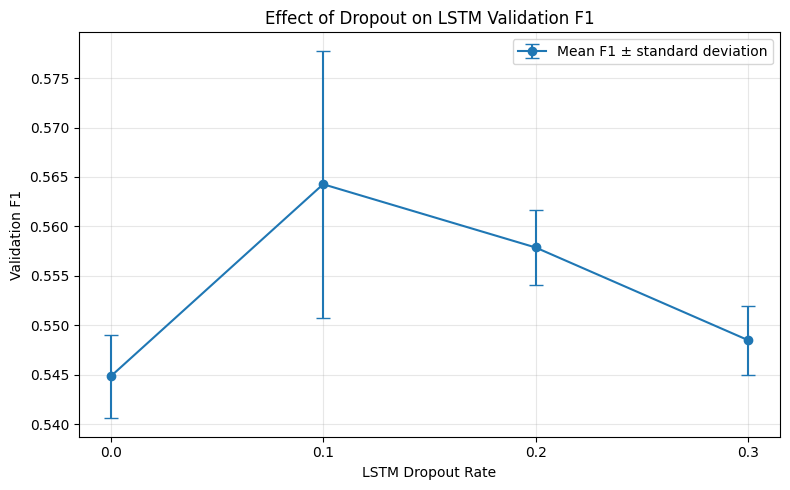

In [51]:
# Create a figure.
plt.figure(figsize=(8, 5))

# Plot mean F1 with standard-deviation error bars.
plt.errorbar(
    dropout_summary.index,
    dropout_summary["F1_mean"],
    yerr=dropout_summary["F1_std"],
    fmt="o-",
    capsize=5,
    label="Mean F1 ± standard deviation"
)

# Label the axes.
plt.xlabel("LSTM Dropout Rate")
plt.ylabel("Validation F1")

# Add the plot title.
plt.title("Effect of Dropout on LSTM Validation F1")

# Display the tested dropout values.
plt.xticks(dropout_rates)

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

We can compare the unregularized dropout runs directly with the previous \(L=20\) runs.

In [52]:

# Retrieve the L=20 results from the lookback experiment.
lookback_baseline = lookback_results_df.loc[
    lookback_results_df["Lookback"] == 20,
    ["Seed", "Best Epoch", "Threshold", "F1", "ROC-AUC", "PR-AUC", "Log Loss"]
].copy()

# Identify the source experiment.
lookback_baseline["Experiment"] = "Lookback: L=20"

# Retrieve the unregularized dropout results.
dropout_baseline = dropout_results_df.loc[
    dropout_results_df["Dropout"] == 0.0,
    ["Seed", "Best Epoch", "Threshold", "F1", "ROC-AUC", "PR-AUC", "Log Loss"]
].copy()

# Identify the source experiment.
dropout_baseline["Experiment"] = "Dropout: p=0"

# Combine both baselines.
baseline_comparison = pd.concat(
    [lookback_baseline, dropout_baseline],
    ignore_index=True
)

# Sort the comparison by random seed and experiment.
baseline_comparison = baseline_comparison.sort_values(
    ["Seed", "Experiment"]
)

# Display the comparison.
display(baseline_comparison.round(4))


,Seed,Best Epoch,Threshold,F1,ROC-AUC,PR-AUC,Log Loss,Experiment
3,42,9,0.20,0.5449,0.7670,0.5531,0.4881,Dropout: p=0
0,42,22,0.25,0.5734,0.7932,0.5599,0.4671,Lookback: L=20
4,123,14,0.20,0.5490,0.7701,0.5487,0.4887,Dropout: p=0
1,123,37,0.20,0.5905,0.7918,0.5539,0.4718,Lookback: L=20
5,2026,8,0.30,0.5405,0.7647,0.5489,0.4889,Dropout: p=0
2,2026,24,0.15,0.5705,0.7765,0.5561,0.4990,Lookback: L=20


In [53]:

# Retrieve the dataset used for the 20-day lookback experiment.
lookback_20 = lookback_datasets[20]

# Display the structure of the saved dataset.
print("Lookback dataset type:", type(lookback_20))

# Display the original baseline tensor dimensions.
print("Original X_train:", X_train.shape)
print("Original X_val:", X_val.shape)

# Display the stored lookback dataset structure.
if isinstance(lookback_20, dict):
    for key, value in lookback_20.items():
        if hasattr(value, "shape"):
            print(key, value.shape)
else:
    for index, value in enumerate(lookback_20):
        if hasattr(value, "shape"):
            print(index, value.shape)


Lookback dataset type: <class 'dict'>
Original X_train: (2685, 20, 3)
Original X_val: (498, 20, 3)
X_train (2645, 20, 3)
y_train (2645,)
X_val (498, 20, 3)
y_val (498,)


Next, compare the actual arrays

In [54]:

# Retrieve the L=20 datasets.
lookback_20 = lookback_datasets[20]

# Compare the training dataset sizes.
print("Original training:", X_train.shape)
print("Lookback training:", lookback_20["X_train"].shape)

# Compare the validation features element by element.
print(
    "Identical validation features:",
    np.array_equal(X_val, lookback_20["X_val"])
)

# Compare the validation labels.
print(
    "Identical validation labels:",
    np.array_equal(y_val, lookback_20["y_val"])
)

# Check whether the shorter training dataset is a suffix
# of the original training dataset.
n = len(lookback_20["X_train"])

print(
    "Training suffix matches:",
    np.array_equal(X_train[-n:], lookback_20["X_train"])
)

# Compare the corresponding training labels.
print(
    "Training label suffix matches:",
    np.array_equal(y_train[-n:], lookback_20["y_train"])
)


Original training: (2685, 20, 3)
Lookback training: (2645, 20, 3)
Identical validation features: True
Identical validation labels: True
Training suffix matches: True
Training label suffix matches: True


### 4.7.7 Controlled Dropout Experiment

We previously observed that the lookback and dropout experiments used different numbers of training sequences.

To isolate the effect of dropout, we now fix the dataset, architecture, and training procedure, varying only the dropout rate and random seed.

We use the $L=20$ dataset constructed during the lookback experiment. All configurations therefore use identical training and validation observations.

The dropout rates are

$$
p \in \{0,0.1,0.2,0.3\},
$$

and the random seeds are

$$
s \in \{42,123,2026\}.
$$

For each run, we select the probability decision threshold that maximizes validation F1 over the predefined threshold grid.

We compare the mean and standard deviation of F1 across seeds, together with ROC-AUC, PR-AUC, and binary cross-entropy.

The test dataset remains untouched.


Step 1. Prepare the data

In [55]:

# Retrieve the common 20-day lookback dataset.
common_dataset = lookback_datasets[20]

# Extract training features and labels.
X_train_common = common_dataset["X_train"]
y_train_common = common_dataset["y_train"]

# Extract validation features and labels.
X_val_common = common_dataset["X_val"]
y_val_common = common_dataset["y_val"]

# Verify the expected dataset dimensions.
print("Training:", X_train_common.shape, y_train_common.shape)
print("Validation:", X_val_common.shape, y_val_common.shape)

# Confirm that the validation observations are unchanged.
assert np.array_equal(X_val_common, X_val)
assert np.array_equal(y_val_common, y_val)


Training: (2645, 20, 3) (2645,)
Validation: (498, 20, 3) (498,)


Step 2. Train the LSTM models

In [56]:

# Define the dropout rates to investigate.
dropout_rates = [0.0, 0.1, 0.2, 0.3]

# Define the random seeds.
random_seeds = [42, 123, 2026]

# Define the probability thresholds to evaluate.
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

# Initialize containers for results and trained models.
controlled_dropout_results = []
controlled_dropout_models = {}

# Loop over dropout rates.
for dropout_rate in dropout_rates:

    # Repeat each configuration across random seeds.
    for seed in random_seeds:

        # Clear the previous TensorFlow model state.
        tf.keras.backend.clear_session()

        # Set the random seed for reproducibility.
        tf.keras.utils.set_random_seed(seed)

        # Construct the LSTM classifier.
        model = tf.keras.Sequential([
            tf.keras.layers.Input(
                shape=(X_train_common.shape[1], X_train_common.shape[2])
            ),
            tf.keras.layers.LSTM(
                units=16,
                dropout=dropout_rate,
                recurrent_dropout=0.0
            ),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        # Configure the optimizer and loss.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        # Stop training when validation loss stops improving.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train using the common dataset.
        history = model.fit(
            X_train_common,
            y_train_common,
            validation_data=(X_val_common, y_val_common),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            shuffle=False,
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val_common,
            verbose=0
        ).ravel()

        # Calculate F1 for every decision threshold.
        f1_values = [
            f1_score(
                y_val_common,
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in thresholds
        ]

        # Identify the threshold with the highest F1.
        best_index = np.argmax(f1_values)

        # Retrieve the selected threshold.
        best_threshold = float(thresholds[best_index])

        # Generate binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the experimental results.
        controlled_dropout_results.append({
            "Dropout": dropout_rate,
            "Seed": seed,
            "Best Epoch": np.argmin(history.history["val_loss"]) + 1,
            "Threshold": best_threshold,
            "F1": f1_score(y_val_common, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val_common, predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_val_common, probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val_common, probabilities
            ),
            "Log Loss": log_loss(
                y_val_common, probabilities
            )
        })

        # Retain the trained model for later analysis.
        controlled_dropout_models[(dropout_rate, seed)] = model

# Construct the results table.
controlled_dropout_df = pd.DataFrame(controlled_dropout_results)

# Display the individual runs.
display(controlled_dropout_df.round(4))


,Dropout,Seed,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,0.0,42,9,0.30,0.5462,0.6948,0.7672,0.5554,0.4878
1,0.0,123,13,0.20,0.5437,0.7003,0.7693,0.5503,0.4889
2,0.0,2026,8,0.35,0.5413,0.6898,0.7647,0.5503,0.4882
3,0.1,42,11,0.30,0.5565,0.7026,0.7678,0.5510,0.4835
4,0.1,123,19,0.20,0.5449,0.7039,0.7730,0.5453,0.4797
5,0.1,2026,12,0.30,0.5476,0.6972,0.7666,0.5432,0.4842
6,0.2,42,11,0.30,0.5587,0.7039,0.7674,0.5537,0.4840
7,0.2,123,17,0.25,0.5411,0.6966,0.7688,0.5392,0.4812
8,0.2,2026,9,0.25,0.5466,0.7040,0.7665,0.5430,0.4804
9,0.3,42,10,0.35,0.5388,0.6884,0.7628,0.5452,0.4857


Step 3. Summarize the results

In [57]:

# Group results by dropout rate.
controlled_dropout_summary = controlled_dropout_df.groupby(
    "Dropout"
).agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean")
)

# Display the summary.
display(controlled_dropout_summary.round(4))


,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Dropout,,,,,,
0.0,0.5437,0.0025,0.6949,0.7671,0.5520,0.4883
0.1,0.5497,0.0060,0.7012,0.7691,0.5465,0.4825
0.2,0.5488,0.0090,0.7015,0.7676,0.5453,0.4819
0.3,0.5414,0.0028,0.6959,0.7654,0.5355,0.4831


Step 4. Visualize the effect of dropout

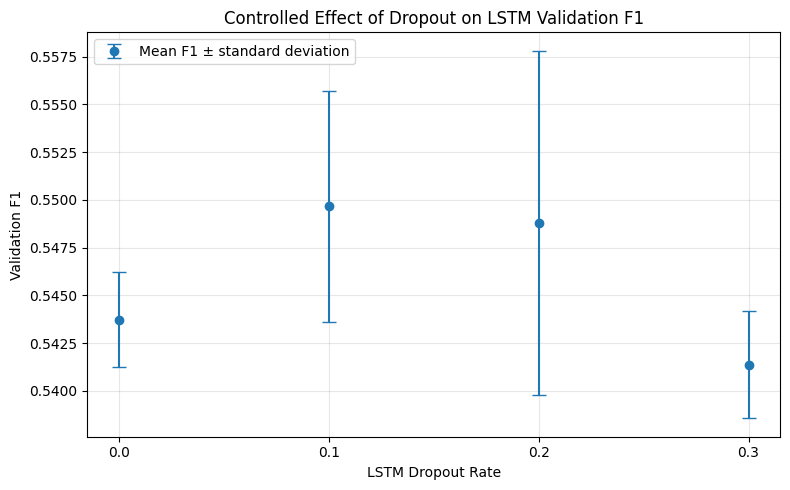

In [58]:

# Retrieve the tested dropout rates.
x = controlled_dropout_summary.index.to_numpy()

# Retrieve mean validation F1.
y = controlled_dropout_summary["F1_mean"].to_numpy()

# Retrieve standard deviations across seeds.
yerr = controlled_dropout_summary["F1_std"].to_numpy()

# Create the figure.
plt.figure(figsize=(8, 5))

# Plot discrete experimental results with error bars.
plt.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=5,
    label="Mean F1 ± standard deviation"
)

# Label the axes.
plt.xlabel("LSTM Dropout Rate")
plt.ylabel("Validation F1")

# Add the plot title.
plt.title("Controlled Effect of Dropout on LSTM Validation F1")

# Show the tested hyperparameter values.
plt.xticks(dropout_rates)

# Add the legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()



### 4.7.8 Interpretation of the Controlled Dropout Experiment

To isolate the effect of dropout, we repeated the experiment using identical training and validation observations for all configurations.

We fixed the LSTM architecture at 16 hidden units and the lookback length at $L=20$, varying dropout over

$$
p \in \{0,0.1,0.2,0.3\}.
$$

Each configuration was evaluated using three random seeds.

The highest mean validation F1 was obtained with dropout $p=0.1$:

$$
\overline{F_1}=0.5497,
\qquad
s_{F_1}=0.0060.
$$

The unregularized model achieved

$$
\overline{F_1}=0.5437,
\qquad
s_{F_1}=0.0025.
$$

Thus, the improvement in mean F1 was approximately $0.006$.

Dropout $p=0.2$ achieved a similar mean F1 of $0.5488$, but exhibited greater variability across seeds.

The unregularized model achieved the highest mean PR-AUC, while dropout $p=0.2$ achieved the lowest mean binary cross-entropy.

These findings suggest that moderate dropout may provide a small benefit, but the evidence for a substantial improvement is weak.

We provisionally select dropout $p=0.1$ for further investigation, retaining the unregularized LSTM as a baseline.

The test dataset has not been used in model selection.



# 5. Gated Recurrent Units (GRU)

## 5.1 Motivation

Recall that a Simple Recurrent Neural Network updates its hidden state according to

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b).
$$

Although this architecture can process sequential data, it may struggle to learn long-range dependencies because of the vanishing-gradient problem.

Long Short-Term Memory (LSTM) networks address this problem by introducing a separate cell state and three gates:

1. Forget gate
2. Input gate
3. Output gate

A **Gated Recurrent Unit (GRU)** is another gated recurrent architecture designed to improve the learning of dependencies across time.

GRUs were introduced by Cho et al. (2014).

Unlike LSTMs, GRUs have:

- Two gates instead of three.
- No separate cell state.
- A single hidden state that carries information through time.

Consequently, GRUs generally require fewer trainable parameters than LSTMs with the same input and hidden dimensions.

Our objective is to investigate whether this simpler architecture performs comparably to an LSTM on our volatility-increase classification task.

## 5.2 Mathematical Formulation

Let

$$
x_t \in \mathbb{R}^d
$$

denote the input vector at time $t$, and let

$$
h_{t-1} \in \mathbb{R}^m
$$

denote the previous hidden state.

A GRU uses two gates: the **update gate** and the **reset gate**.

### 5.2.1 Update Gate

The update gate is defined by

$$
\boxed{
z_t = \sigma(W_z x_t + U_z h_{t-1} + b_z).
}
$$

Here,

- $W_z \in \mathbb{R}^{m \times d}$ is the input weight matrix.
- $U_z \in \mathbb{R}^{m \times m}$ is the recurrent weight matrix.
- $b_z \in \mathbb{R}^m$ is the bias vector.
- $\sigma$ is the sigmoid activation function.

Recall that

$$
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Therefore, each component of $z_t$ lies between zero and one.

The update gate controls how much information from the previous hidden state is retained.

Under the convention used here:

- If $z_t \approx 1$, the previous hidden state is largely preserved.
- If $z_t \approx 0$, the previous hidden state is largely replaced by new information.

### 5.2.2 Reset Gate

The reset gate is defined by

$$
\boxed{
r_t = \sigma(W_r x_t + U_r h_{t-1} + b_r).
}
$$

The reset gate determines how much information from the previous hidden state is used when constructing the candidate hidden state.

For example:

- If $r_t \approx 0$, the corresponding previous-state components contribute very little to the candidate.
- If $r_t \approx 1$, those components are largely available when constructing the candidate.

This allows the GRU to selectively disregard historical information.

### 5.2.3 Candidate Hidden State

The candidate hidden state is defined by

$$
\boxed{
\widetilde{h}_t
=
\tanh\left(
W_h x_t + U_h(r_t \odot h_{t-1}) + b_h
\right).
}
$$

Here, $\odot$ denotes elementwise multiplication.

The reset gate modifies the previous hidden state before it contributes to the candidate.

Notice that $\widetilde{h}_t$ is not yet the final hidden state. It represents newly computed information that may be incorporated into the state.

### 5.2.4 Hidden-State Update

The new hidden state is

$$
\boxed{
h_t
=
z_t \odot h_{t-1}
+
(1-z_t)\odot\widetilde{h}_t.
}
$$

This is the central equation of a GRU.

The update gate determines how the previous hidden state and candidate hidden state are combined.

If $z_t$ is close to one, then

$$
h_t \approx h_{t-1}.
$$

If $z_t$ is close to zero, then

$$
h_t \approx \widetilde{h}_t.
$$

Thus, the GRU can either preserve previous information or incorporate new information, depending on the input and its current state.

**Remark.** Some references use the complementary convention for the update gate, interchanging $z_t$ and $1-z_t$ in the hidden-state update. The convention above treats $z_t$ as the retention coefficient. Also, the default TensorFlow/Keras GRU implementation (`reset_after=True`) places the reset gate differently in the candidate-state computation and uses separate input and recurrent biases.

## 5.3 Numerical Example

Consider a GRU with a one-dimensional hidden state.

Suppose that

$$
h_{t-1}=0.8,
\qquad
\widetilde{h}_t=-0.4.
$$

We investigate how the update gate influences the new hidden state.

### Example 1: Preserving Previous Information

Suppose

$$
z_t=0.9.
$$

Then

$$
\begin{aligned}
h_t
&=z_t h_{t-1}+(1-z_t)\widetilde{h}_t\\
&=0.9(0.8)+0.1(-0.4)\\
&=0.68.
\end{aligned}
$$

The resulting hidden state remains close to the previous value $0.8$.

Thus, the GRU largely preserves its previous information.

### Example 2: Incorporating New Information

Suppose instead that

$$
z_t=0.1.
$$

Then

$$
\begin{aligned}
h_t
&=0.1(0.8)+0.9(-0.4)\\
&=-0.28.
\end{aligned}
$$

The new hidden state is now much closer to the candidate value $-0.4$.

Thus, the GRU largely replaces the previous information.

### Non-example: The GRU Is Not Simply an Average

It would be incorrect to assume that the GRU always computes

$$
h_t=\frac{h_{t-1}+\widetilde{h}_t}{2}.
$$

This occurs only when the update gate equals $0.5$ in the scalar case.

In general, the gate values are learned functions of the current input and previous hidden state.

### Exercise

1. Calculate $h_t$ when $z_t=0.25$, $h_{t-1}=0.8$, and $\widetilde{h}_t=-0.4$.
2. Find an example in which the GRU completely preserves its previous hidden state.
3. Find an example in which the GRU completely replaces its previous hidden state.
4. Explain why the update gate may help preserve information across many time steps.

## 5.4 GRU and the Vanishing-Gradient Problem

Recall that repeated multiplication by Jacobian matrices during backpropagation through time can cause gradients to vanish or explode.

The GRU introduces an additive pathway through the hidden-state update:

$$
h_t
=
z_t\odot h_{t-1}
+
(1-z_t)\odot\widetilde{h}_t.
$$

When the update gate is close to one,

$$
h_t \approx h_{t-1}.
$$

Therefore, information can be carried forward with relatively little modification.

This provides a mechanism for preserving long-term information and can improve gradient propagation.

However, GRUs do not completely eliminate vanishing gradients. The effectiveness of their gating mechanism depends on the learned parameters and the data.

## 5.5 Comparison Between Simple RNN, LSTM, and GRU

| Property | Simple RNN | LSTM | GRU |
|---|---|---|---|
| Gating mechanism | No | Yes | Yes |
| Number of gates | 0 | 3 | 2 |
| Separate cell state | No | Yes | No |
| Hidden state | Yes | Yes | Yes |
| Long-range dependencies | Often difficult | Designed to help | Designed to help |
| Parameter count | Lowest | Generally highest | Generally intermediate |

### Parameter Count

For a standard LSTM with input dimension $d$ and hidden dimension $m$, the number of trainable parameters is

$$
N_{\mathrm{LSTM}}=4m(d+m+1).
$$

For the default Keras GRU implementation with `reset_after=True`, the corresponding parameter count is

$$
N_{\mathrm{GRU}}=3m(d+m+2).
$$

In our project, we have

$$
d=3,\qquad m=16.
$$

Therefore,

$$
N_{\mathrm{LSTM}}
=
4(16)(3+16+1)
=
1280,
$$

whereas

$$
N_{\mathrm{GRU}}
=
3(16)(3+16+2)
=
1008.
$$

These counts exclude the final Dense classification layer.

Thus, the GRU has fewer recurrent-layer parameters than the LSTM in this configuration.

However, fewer parameters do not necessarily imply better predictive performance.

We must evaluate the architectures experimentally.

## 5.6 GRU for Volatility-Increase Classification

Recall that our input at time $t$ consists of three features:

$$
x_t=
\begin{pmatrix}
r_t\\
r_t^2\\
Vol_{20,t}
\end{pmatrix}.
$$

We construct sequences of length $L=20$:

$$
X_t=(x_{t-19},x_{t-18},\ldots,x_t).
$$

The GRU processes this sequence and produces a final hidden state

$$
h_t\in\mathbb{R}^{16}.
$$

A Dense layer with sigmoid activation then produces

$$
\boxed{
\widehat p_t=\sigma(w^\top h_t+b).
}
$$

We interpret $\widehat p_t$ as the model's estimated probability of a volatility-increase event.

Given a classification decision threshold $\tau$, the predicted label is

$$
\widehat y_t=
\begin{cases}
1,&\widehat p_t>\tau,\\
0,&\widehat p_t\leq\tau.
\end{cases}
$$

As in our previous experiments, the probability decision threshold $\tau$ is distinct from the threshold $0.2$ used to define the volatility-increase target.

### Experimental Plan

To compare GRU with our existing LSTM experiments, we initially fix:

- Lookback length: $L=20$.
- Hidden units: $m=16$.
- Dropout: $0$.
- Recurrent dropout: $0$.
- Random seeds: $42$, $123$, and $2026$.
- Training and validation observations: identical to the controlled LSTM experiment.

We will evaluate:

1. Validation binary cross-entropy.
2. ROC-AUC and PR-AUC.
3. F1-score and balanced accuracy.
4. Sensitivity to the probability decision threshold.
5. Variation in performance across random seeds.

The held-out test dataset will not be used during model selection.

Our objective is to determine whether the simpler GRU architecture provides competitive predictive performance relative to the LSTM.

### Reference

Cho, K., van Merriënboer, B., Gülçehre, Ç., Bahdanau, D., Bougares, F., Schwenk, H., and Bengio, Y. (2014).

*Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation.*

https://arxiv.org/abs/1406.1078



## 5.7 Implementing a GRU Classifier in TensorFlow/Keras

We now implement a Gated Recurrent Unit (GRU) classifier for predicting volatility-increase events.

To make the comparison with our LSTM experiments meaningful, we initially use the following configuration:

| Hyperparameter | Value |
|---|---|
| Lookback length | 20 trading days |
| Input features | 3 |
| GRU units | 16 |
| Dropout | 0 |
| Recurrent dropout | 0 |
| Output units | 1 |
| Output activation | Sigmoid |
| Loss function | Binary cross-entropy |
| Optimizer | Adam |
| Random seed | 42 |

The architecture is

$$
\boxed{
\text{Input Sequence}
\longrightarrow
\text{GRU}(16)
\longrightarrow
\text{Dense}(1,\text{sigmoid})
}
$$

For an input sequence

$$
X_t \in \mathbb{R}^{20\times 3},
$$

the GRU produces a hidden representation

$$
h_t \in \mathbb{R}^{16}.
$$

The output layer computes

$$
\widehat p_t = \sigma(w^\top h_t+b).
$$

We train the model by minimizing binary cross-entropy:

$$
\mathcal L
=
-\frac{1}{N}
\sum_{i=1}^{N}
\left[
y_i\log(\widehat p_i)
+
(1-y_i)\log(1-\widehat p_i)
\right].
$$

As before, we use the chronological training and validation splits. The held-out test dataset remains untouched.

This first experiment establishes a GRU baseline. Hyperparameter tuning and comparisons across random seeds will follow.


Step 1. Retrieve the controlled dataset

In [59]:
# Retrieve the dataset with a 20-day lookback.
gru_data = lookback_datasets[20]

# Retrieve the training features and labels.
X_train_gru = gru_data["X_train"]
y_train_gru = gru_data["y_train"]

# Retrieve the validation features and labels.
X_val_gru = gru_data["X_val"]
y_val_gru = gru_data["y_val"]

# Inspect the shapes of the arrays.
print("Training features:", X_train_gru.shape)
print("Training labels:", y_train_gru.shape)
print("Validation features:", X_val_gru.shape)
print("Validation labels:", y_val_gru.shape)

Training features: (2645, 20, 3)
Training labels: (2645,)
Validation features: (498, 20, 3)
Validation labels: (498,)


Step 2. Construct the GRU model

In [60]:
# Import TensorFlow.
import tensorflow as tf

# Import the Keras components.
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import GRU, Dense

# Set the random seed for reproducibility.
tf.keras.utils.set_random_seed(42)

# Define the number of GRU hidden units.
GRU_UNITS = 16

# Define the input shape from the training data.
gru_input_shape = X_train_gru.shape[1:]

# Define the input layer.
gru_inputs = Input(shape=gru_input_shape)

# Apply a GRU layer to the input sequence.
gru_hidden = GRU(
    units=GRU_UNITS,
    dropout=0.0,
    recurrent_dropout=0.0,
    return_sequences=False
)(gru_inputs)

# Apply a sigmoid output layer for binary classification.
gru_outputs = Dense(
    units=1,
    activation="sigmoid"
)(gru_hidden)

# Construct the complete GRU model.
gru_model = Model(
    inputs=gru_inputs,
    outputs=gru_outputs,
    name="volatility_gru"
)

# Compile the model.
gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture and parameter counts.
gru_model.summary()

Model: "volatility_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 20, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 16)             │         1,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

Step 3. Train the GRU

In [61]:
# Define early stopping based on validation loss.
gru_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the GRU classifier.
gru_history = gru_model.fit(
    X_train_gru,
    y_train_gru,
    validation_data=(X_val_gru, y_val_gru),
    epochs=100,
    batch_size=32,
    callbacks=[gru_early_stopping],
    verbose=1,
    shuffle=False
)

Epoch 1/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6994 - loss: 0.6201 - val_accuracy: 0.7470 - val_loss: 0.5444
Epoch 2/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7497 - loss: 0.5148 - val_accuracy: 0.7470 - val_loss: 0.5147
Epoch 3/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7520 - loss: 0.4903 - val_accuracy: 0.7530 - val_loss: 0.5097
Epoch 4/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7637 - loss: 0.4819 - val_accuracy: 0.7590 - val_loss: 0.5080
Epoch 5/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7709 - loss: 0.4783 - val_accuracy: 0.7590 - val_loss: 0.5082
Epoch 6/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7724 - loss: 0.4764 - val_accuracy: 0.7610 - val_loss: 0.5087
Epoch 7/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7739 - loss: 0.4752 - val_accuracy: 0.7691 - val_loss: 0.5090
Epoch 8/100
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7758 - loss: 0.4742 - val_accuracy: 0.7691 - v

Step 4. Visualize training and validation loss

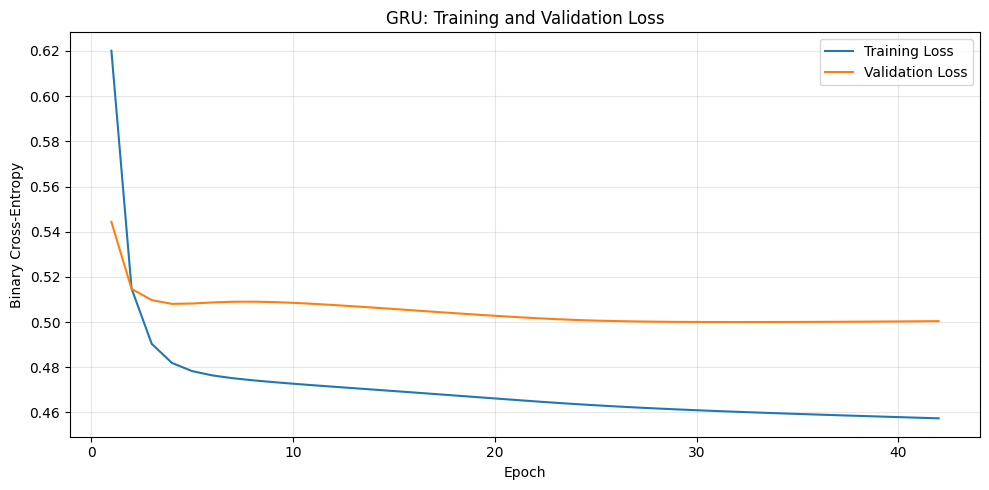

In [62]:
# Convert the training history into a DataFrame.
gru_history_df = pd.DataFrame(gru_history.history)

# Create an epoch index starting at one.
gru_history_df.index = gru_history_df.index + 1

# Create the figure.
plt.figure(figsize=(10, 5))

# Plot the training loss.
plt.plot(
    gru_history_df.index,
    gru_history_df["loss"],
    label="Training Loss"
)

# Plot the validation loss.
plt.plot(
    gru_history_df.index,
    gru_history_df["val_loss"],
    label="Validation Loss"
)

# Label the axes.
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")

# Add a title.
plt.title("GRU: Training and Validation Loss")

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

Step 5. Identify the best epoch

In [63]:
# Find the epoch with the lowest validation loss.
best_gru_epoch = int(gru_history_df["val_loss"].idxmin())

# Retrieve the minimum validation loss.
best_gru_val_loss = gru_history_df["val_loss"].min()

# Display the results.
print(f"Best GRU epoch: {best_gru_epoch}")
print(f"Minimum validation loss: {best_gru_val_loss:.4f}")

Best GRU epoch: 32
Minimum validation loss: 0.5000



### 5.7.1 Interpretation of GRU Training

The GRU classifier achieved its minimum validation binary cross-entropy at epoch 32:

$$
\mathcal{L}_{\mathrm{val}}^{\mathrm{GRU}} \approx 0.5000.
$$

The training loss decreased rapidly during the initial epochs and continued to decline throughout training. The validation loss improved more slowly and eventually stabilized near $0.500$.

The persistent gap between training and validation loss suggests some overfitting, although the validation curve does not exhibit a pronounced upward trend.

For comparison, our earlier LSTM experiment achieved a minimum validation loss of approximately $0.4905$ at epoch 13. However, the two results should not yet be interpreted as a fully controlled architectural comparison.

A lower binary cross-entropy does not necessarily imply a higher F1-score, since cross-entropy evaluates predicted probabilities whereas F1 depends on a classification decision threshold.

We therefore proceed to evaluate the GRU's classification performance on the validation dataset.



## 5.8 GRU Validation Classification Performance

We now evaluate the GRU classifier on the validation dataset.

The GRU produces a probability estimate

$$
\widehat p_t = P(y_t=1\mid X_t),
$$

where $y_t=1$ denotes a volatility-increase event.

To obtain binary predictions, we introduce a classification threshold $\tau$:

$$
\widehat y_t =
\begin{cases}
1, & \widehat p_t > \tau,\\
0, & \widehat p_t \leq \tau.
\end{cases}
$$

We begin with the conventional threshold $\tau=0.5$ and evaluate accuracy, balanced accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, and binary cross-entropy.

We then investigate how classification performance changes with $\tau$ and select the threshold maximizing validation F1.

The threshold $\tau$ is distinct from the constant $0.2$ used to define the volatility-increase target.

All threshold selection is performed exclusively on the validation dataset. The held-out test dataset remains untouched.


#### 5.8.1 Generate predicted probabilities

In [64]:
# Generate GRU probabilities for the validation dataset.
gru_val_prob = gru_model.predict(
    X_val_gru,
    verbose=0
).ravel()

# Define the initial classification threshold.
GRU_THRESHOLD = 0.5

# Convert predicted probabilities into binary labels.
gru_val_pred = (gru_val_prob > GRU_THRESHOLD).astype(int)

# Display the observed positive-class proportion.
print(f"Actual positive rate: {y_val_gru.mean():.2%}")

# Display the predicted positive-class proportion.
print(f"Predicted positive rate: {gru_val_pred.mean():.2%}")

# Inspect the first ten predicted probabilities.
print("First ten predicted probabilities:")
print(np.round(gru_val_prob[:10], 4))

Actual positive rate: 25.30%
Predicted positive rate: 6.22%
First ten predicted probabilities:
[0.3802 0.2848 0.228  0.1275 0.1045 0.1434 0.1445 0.1366 0.1801 0.2854]


#### 5.8.2 Evaluate Classification metrics

In [65]:
# Calculate the validation classification metrics.
gru_val_metrics = {
    "Accuracy": accuracy_score(y_val_gru, gru_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val_gru, gru_val_pred),
    "Precision": precision_score(y_val_gru, gru_val_pred, zero_division=0),
    "Recall": recall_score(y_val_gru, gru_val_pred, zero_division=0),
    "F1": f1_score(y_val_gru, gru_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_gru, gru_val_prob),
    "PR-AUC": average_precision_score(y_val_gru, gru_val_prob),
    "Log Loss": log_loss(y_val_gru, gru_val_prob)
}

# Display the evaluation results.
display(
    pd.DataFrame(
        gru_val_metrics.items(),
        columns=["Metric", "GRU"]
    )
)

# Display the confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_val_gru, gru_val_pred, labels=[0, 1]))

,Metric,GRU
0,Accuracy,0.769076
1,Balanced Accuracy,0.569892
2,Precision,0.677419
3,Recall,0.166667
4,F1,0.267516
5,ROC-AUC,0.766940
6,PR-AUC,0.541623
7,Log Loss,0.500015


Confusion Matrix:
[[362  10]
 [105  21]]


#### 5.8.3 Investigate the classification threshold

In [66]:
# Define the classification thresholds.
gru_thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

# Initialize a list for storing threshold results.
gru_threshold_results = []

# Evaluate each candidate threshold.
for threshold in gru_thresholds:

    # Convert predicted probabilities into binary predictions.
    predictions = (gru_val_prob > threshold).astype(int)

    # Record the classification performance.
    gru_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_gru, predictions, zero_division=0),
        "Recall": recall_score(y_val_gru, predictions, zero_division=0),
        "F1": f1_score(y_val_gru, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val_gru, predictions),
        "Predicted Positive Rate": predictions.mean()
    })

# Construct the threshold comparison table.
gru_threshold_df = pd.DataFrame(gru_threshold_results)

# Display the results.
display(gru_threshold_df.round(4))

,Threshold,Precision,Recall,F1,Balanced Accuracy,Predicted Positive Rate
0,0.10,0.3843,0.8175,0.5228,0.6870,0.5382
1,0.15,0.4466,0.7302,0.5542,0.7119,0.4137
2,0.20,0.4839,0.5952,0.5338,0.6901,0.3112
3,0.25,0.5630,0.5317,0.5469,0.6960,0.2390
4,0.30,0.5652,0.4127,0.4771,0.6526,0.1847
5,0.35,0.6301,0.3651,0.4623,0.6462,0.1466
6,0.40,0.6071,0.2698,0.3736,0.6054,0.1124
7,0.45,0.6364,0.2222,0.3294,0.5896,0.0884
8,0.50,0.6774,0.1667,0.2675,0.5699,0.0622
9,0.55,0.7917,0.1508,0.2533,0.5687,0.0482


#### 5.8.4 Select the best threshold

In [67]:
# Find the row with the highest validation F1.
best_gru_row = gru_threshold_df.loc[
    gru_threshold_df["F1"].idxmax()
]

# Retrieve the selected threshold.
best_gru_threshold = float(best_gru_row["Threshold"])

# Generate predictions using the selected threshold.
gru_val_pred_best = (
    gru_val_prob > best_gru_threshold
).astype(int)

# Display the selected threshold and its performance.
print(f"Selected GRU threshold: {best_gru_threshold:.2f}")
print(f"Validation F1: {best_gru_row['F1']:.4f}")
print(
    "Validation balanced accuracy: "
    f"{best_gru_row['Balanced Accuracy']:.4f}"
)

# Display the resulting confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_val_gru, gru_val_pred_best, labels=[0, 1]))

Selected GRU threshold: 0.15
Validation F1: 0.5542
Validation balanced accuracy: 0.7119
Confusion Matrix:
[[258 114]
 [ 34  92]]


#### 5.8.5 Visualize threshold senstitivity

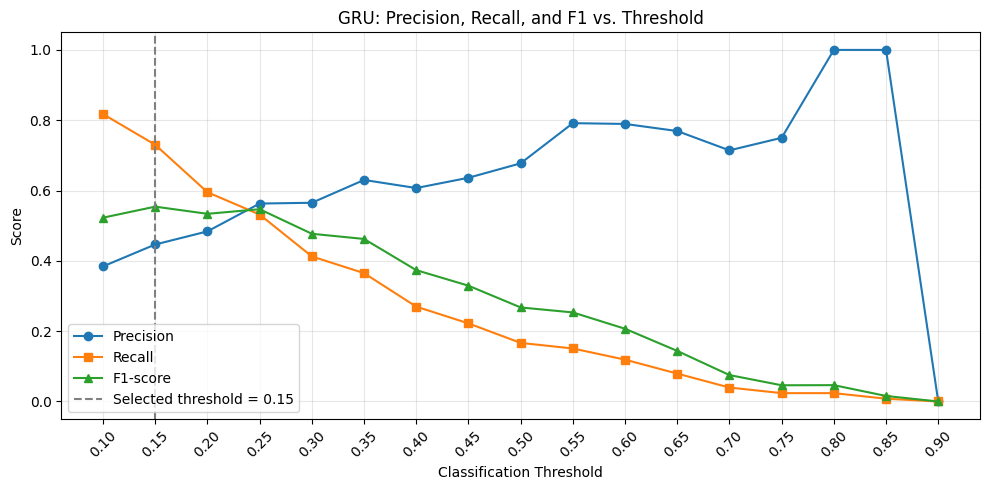

In [68]:
# Create the figure.
plt.figure(figsize=(10, 5))

# Plot precision against the threshold.
plt.plot(
    gru_threshold_df["Threshold"],
    gru_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

# Plot recall against the threshold.
plt.plot(
    gru_threshold_df["Threshold"],
    gru_threshold_df["Recall"],
    marker="s",
    label="Recall"
)

# Plot F1 against the threshold.
plt.plot(
    gru_threshold_df["Threshold"],
    gru_threshold_df["F1"],
    marker="^",
    label="F1-score"
)

# Mark the selected threshold.
plt.axvline(
    best_gru_threshold,
    linestyle="--",
    color="gray",
    label=f"Selected threshold = {best_gru_threshold:.2f}"
)

# Label the axes.
plt.xlabel("Classification Threshold")
plt.ylabel("Score")

# Add the plot title.
plt.title("GRU: Precision, Recall, and F1 vs. Threshold")

# Display the tested threshold values.
plt.xticks(gru_thresholds, rotation=45)

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()


### 5.8.6 Interpretation of GRU Validation Results

The GRU achieves a validation ROC-AUC of approximately $0.7669$, PR-AUC of $0.5416$, and log loss of $0.5000$.

At the conventional classification threshold $\tau=0.5$, the model exhibits high precision ($0.6774$) but low recall ($0.1667$). Consequently, its F1-score is only $0.2675$.

By selecting the threshold that maximizes validation F1, we obtain

$$
\tau^* = 0.15.
$$

At this threshold, the GRU achieves

$$
\text{F1}=0.5542,
\qquad
\text{Balanced Accuracy}=0.7119.
$$

The corresponding confusion matrix is

$$
\begin{pmatrix}
258 & 114\\
34 & 92
\end{pmatrix}.
$$

Thus, the classifier correctly identifies 92 of the 126 volatility-increase events, while generating 114 false-positive predictions.

**Comparison with LSTM.** The initial LSTM achieved an F1-score of $0.5441$ and balanced accuracy of $0.6957$ after threshold selection. The GRU therefore performs slightly better on these two metrics, although the LSTM achieved higher PR-AUC.

These results suggest that the GRU is a competitive alternative to the LSTM for our volatility classification problem.

However, the comparison is preliminary. Neural-network training depends on random initialization, and the architectures have not yet undergone equivalent hyperparameter tuning.

Furthermore, the decision threshold was selected using the same validation observations on which F1 is reported. Consequently, the selected F1-score is an optimistic estimate of future performance.

We will next investigate the stability of the GRU across random seeds and examine the effects of its hyperparameters. Final generalization performance will be assessed only on the held-out test dataset.


## 5.9 GRU Hyperparameter Tuning

Our initial GRU classifier achieved a validation F1-score of approximately $0.5542$ after selecting the classification threshold.

However, the initial architecture used 16 GRU units. This choice was made to provide a controlled comparison with the Simple RNN and LSTM, rather than because 16 units were known to be optimal.

We now investigate how the number of GRU units affects predictive performance.

### 5.9.1 Effect of the Number of GRU Units

The number of GRU units determines the dimension of the hidden state,

$$
h_t \in \mathbb{R}^d,
$$

where $d$ is the number of units.

Increasing $d$ allows the model to represent more complex temporal dependencies, but also increases the number of trainable parameters and the risk of overfitting.

For a GRU with input dimension $m$ and hidden dimension $d$, the number of trainable parameters in the TensorFlow/Keras implementation with `reset_after=True` is

$$
N_{\mathrm{GRU}} = 3d(m+d+2).
$$

The factor of three corresponds to the update gate, reset gate, and candidate hidden-state computation.

We will compare

$$
d \in \{8,16,32,64\}.
$$

To investigate sensitivity to random initialization, each configuration will be trained using

$$
\text{seed} \in \{42,123,2026\}.
$$

All other settings remain fixed:

- Lookback window: 20 trading days.
- Dropout: $0$.
- Recurrent dropout: $0$.
- Input features: the same three features used previously.
- Training and validation periods: unchanged.
- Early stopping: based on validation binary cross-entropy.
- Classification threshold: selected by maximizing validation F1.

The primary comparison metric is the mean validation F1-score across random seeds. We will also examine its standard deviation, balanced accuracy, ROC-AUC, PR-AUC, and log loss.

The held-out test dataset will not be used during hyperparameter selection.

##### Step 1. Define the experiment

We already have the 20-day lookback dataset stored in lookback_datasets[20]. We will reuse it to ensure that the GRU experiments use the same observations.

In [69]:
# Retrieve the 20-day lookback dataset.
gru_dataset = lookback_datasets[20]

# Extract training features and labels.
X_train_gru = gru_dataset["X_train"]
y_train_gru = gru_dataset["y_train"]

# Extract validation features and labels.
X_val_gru = gru_dataset["X_val"]
y_val_gru = gru_dataset["y_val"]

# Define the candidate numbers of GRU units.
gru_units_list = [8, 16, 32, 64]

# Define the random seeds.
gru_seeds = [42, 123, 2026]

# Define the classification thresholds.
gru_tuning_thresholds = np.round(
    np.arange(0.10, 0.91, 0.05), 2
)

# Inspect the dataset dimensions.
print("Training:", X_train_gru.shape)
print("Validation:", X_val_gru.shape)

Training: (2645, 20, 3)
Validation: (498, 20, 3)


##### Step 2. Train the GRU models
We will use a single GRU layer followed by a sigmoid output layer, keeping the architecture consistent across all experiments.

One important methodological detail: we must restore the weights from the epoch with the lowest validation loss, rather than evaluate the final epoch's weights.

In [70]:
# Import the required TensorFlow/Keras components.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Import the evaluation metrics.
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)

# Initialize containers for results and trained models.
gru_units_results = []
gru_tuned_models = {}

# Iterate over the candidate hidden-state dimensions.
for units in gru_units_list:

    # Repeat each experiment across random seeds.
    for seed in gru_seeds:

        # Clear the previous Keras model state.
        keras.backend.clear_session()

        # Set the random seed.
        keras.utils.set_random_seed(seed)

        # Construct the GRU classifier.
        model = keras.Sequential([
            layers.Input(shape=X_train_gru.shape[1:]),
            layers.GRU(
                units,
                dropout=0.0,
                recurrent_dropout=0.0,
            ),
            layers.Dense(1, activation="sigmoid"),
        ])

        # Compile the model.
        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="binary_crossentropy",
        )

        # Define early stopping.
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
        )

        # Train the model.
        history = model.fit(
            X_train_gru,
            y_train_gru,
            validation_data=(X_val_gru, y_val_gru),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0,
            shuffle=False,
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val_gru,
            verbose=0,
        ).ravel()

        # Evaluate F1 across classification thresholds.
        f1_values = [
            f1_score(
                y_val_gru,
                (probabilities > threshold).astype(int),
                zero_division=0,
            )
            for threshold in gru_tuning_thresholds
        ]

        # Identify the threshold maximizing validation F1.
        best_index = int(np.argmax(f1_values))

        # Retrieve the selected threshold.
        best_threshold = float(
            gru_tuning_thresholds[best_index]
        )

        # Construct the corresponding binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the experiment results.
        gru_units_results.append({
            "Units": units,
            "Seed": seed,
            "Parameters": model.count_params(),
            "Best Epoch": int(
                np.argmin(history.history["val_loss"]) + 1
            ),
            "Validation Loss": min(
                history.history["val_loss"]
            ),
            "Threshold": best_threshold,
            "F1": f1_score(y_val_gru, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val_gru, predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_val_gru, probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val_gru, probabilities
            ),
            "Log Loss": log_loss(
                y_val_gru, probabilities
            ),
        })

        # Store the trained model for later inspection.
        gru_tuned_models[(units, seed)] = model

        # Report completion of the current run.
        print(
            f"Units={units:2d}, Seed={seed}, "
            f"F1={f1_values[best_index]:.4f}"
        )

# Construct the results DataFrame.
gru_units_df = pd.DataFrame(gru_units_results)

# Display results ordered by hidden-state dimension and seed.
display(
    gru_units_df.sort_values(["Units", "Seed"]).round(4)
)

Units= 8, Seed=42, F1=0.5269
Units= 8, Seed=123, F1=0.5547
Units= 8, Seed=2026, F1=0.5480
Units=16, Seed=42, F1=0.5542
Units=16, Seed=123, F1=0.5520
Units=16, Seed=2026, F1=0.5246
Units=32, Seed=42, F1=0.5303
Units=32, Seed=123, F1=0.5193
Units=32, Seed=2026, F1=0.5396
Units=64, Seed=42, F1=0.5260
Units=64, Seed=123, F1=0.5420
Units=64, Seed=2026, F1=0.5349


,Units,Seed,Parameters,Best Epoch,Validation Loss,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,8,42,321,9,0.5074,0.15,0.5269,0.6889,0.7524,0.4996,0.5074
1,8,123,321,40,0.4952,0.20,0.5547,0.7048,0.7715,0.5429,0.4952
2,8,2026,321,72,0.5022,0.20,0.5480,0.7007,0.7671,0.5431,0.5022
3,16,42,1025,32,0.5000,0.15,0.5542,0.7119,0.7669,0.5416,0.5000
4,16,123,1025,54,0.4978,0.20,0.5520,0.7034,0.7713,0.5436,0.4978
5,16,2026,1025,4,0.5048,0.15,0.5246,0.6874,0.7564,0.5252,0.5048
6,32,42,3585,3,0.5053,0.20,0.5303,0.6917,0.7428,0.4964,0.5053
7,32,123,3585,3,0.5001,0.15,0.5193,0.6831,0.7513,0.5069,0.5001
8,32,2026,3585,17,0.5008,0.15,0.5396,0.6998,0.7631,0.5410,0.5008
9,64,42,13313,2,0.4966,0.20,0.5260,0.6887,0.7471,0.4928,0.4966


##### Step 3. Summarize performance across random seeds

In [71]:
# Group the experiments by the number of GRU units.
gru_units_summary = gru_units_df.groupby("Units").agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean"),
)

# Display the summary statistics.
display(gru_units_summary.round(4))

,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Units,,,,,,
8,0.5432,0.0145,0.6982,0.7637,0.5285,0.5016
16,0.5436,0.0165,0.7009,0.7649,0.5368,0.5009
32,0.5297,0.0102,0.6915,0.7524,0.5147,0.5021
64,0.5343,0.0080,0.6908,0.7542,0.5221,0.4979


##### Step 4. Visualize the results

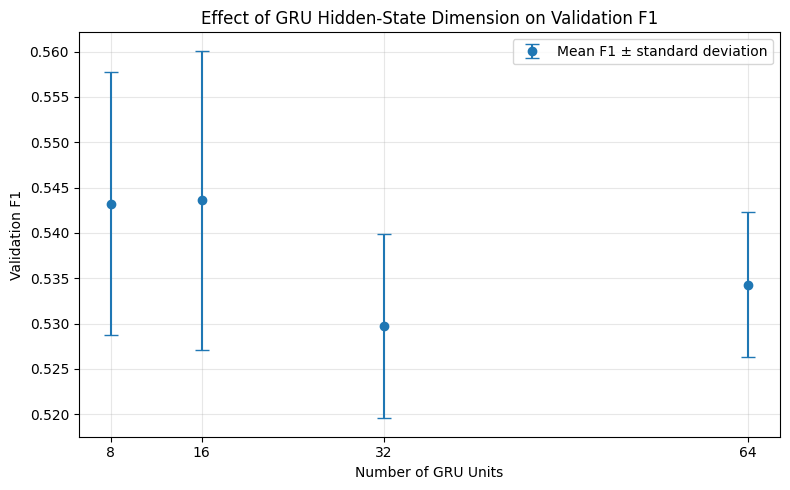

In [72]:
# Create the figure.
plt.figure(figsize=(8, 5))

# Plot mean F1 and its standard deviation.
plt.errorbar(
    gru_units_summary.index,
    gru_units_summary["F1_mean"],
    yerr=gru_units_summary["F1_std"],
    fmt="o",
    capsize=5,
    label="Mean F1 ± standard deviation",
)

# Label the axes.
plt.xlabel("Number of GRU Units")
plt.ylabel("Validation F1")

# Add the plot title.
plt.title("Effect of GRU Hidden-State Dimension on Validation F1")

# Display the tested hidden-state dimensions.
plt.xticks(gru_units_list)

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

##### Step 5. Select the provisional best number of units
We will use the highest mean F1 across the three seeds as our selection criterion.

In [73]:
# Identify the hidden-state dimension with the highest mean F1.
best_gru_units = int(
    gru_units_summary["F1_mean"].idxmax()
)

# Retrieve the corresponding mean F1.
best_gru_mean_f1 = gru_units_summary.loc[
    best_gru_units, "F1_mean"
]

# Retrieve the corresponding standard deviation.
best_gru_std_f1 = gru_units_summary.loc[
    best_gru_units, "F1_std"
]

# Display the selected configuration.
print(f"Selected GRU units: {best_gru_units}")
print(f"Mean validation F1: {best_gru_mean_f1:.4f}")
print(f"F1 standard deviation: {best_gru_std_f1:.4f}")

Selected GRU units: 16
Mean validation F1: 0.5436
F1 standard deviation: 0.0165


### 5.9.2 Interpretation of GRU Hidden-State Dimension Experiments

We investigated the effect of the GRU hidden-state dimension using

$$
d \in \{8,16,32,64\},
$$

with three random seeds for each configuration.

The highest mean validation F1-score was obtained with 16 GRU units:

$$
\overline{F1}_{16} \approx 0.5436,
\qquad
s_{F1,16} \approx 0.0165.
$$

However, the configuration with 8 units achieved a nearly identical mean F1-score of approximately $0.5432$.

Increasing the hidden-state dimension to 32 or 64 units did not improve predictive performance. In particular, the mean validation F1-scores decreased to approximately $0.5297$ and $0.5343$, respectively.

The 64-unit model exhibited the smallest variation across random seeds, but its average predictive performance remained below that of the smaller models.

These results suggest that additional GRU capacity does not necessarily improve the detection of future volatility-increase events.

Moreover, the differences between the 8-unit and 16-unit configurations are small relative to the observed variation across random seeds.

We therefore retain **16 GRU units as our provisional configuration**, rather than claiming that this dimension is definitively optimal.

The next experiment will investigate whether changing the lookback window improves GRU performance while keeping the hidden-state dimension fixed.

The held-out test dataset remains untouched.



### 5.9.3 Effect of Lookback Window Length

Having investigated the effect of the GRU hidden-state dimension, we now examine the effect of the input sequence length.

For a lookback window of length $L$, the GRU receives the sequence

$$
X_t^{(L)}
=
\left(
\mathbf{x}_{t-L+1},
\mathbf{x}_{t-L+2},
\ldots,
\mathbf{x}_t
\right),
$$

where $\mathbf{x}_t \in \mathbb{R}^3$ is the feature vector observed on trading day $t$.

The classifier estimates

$$
\widehat{p}_t
=
P\left(
y_t=1 \mid X_t^{(L)}
\right),
$$

where $y_t=1$ represents a future five-day volatility-increase event.

We investigate

$$
L \in \{10,20,40,60\}.
$$

**Motivation.** Shorter lookback windows emphasize recent market behavior, whereas longer windows provide additional historical information that may help the GRU identify persistent volatility patterns.

However, longer sequences may also introduce irrelevant information and increase the difficulty of learning useful temporal dependencies.

We therefore investigate whether increasing $L$ improves out-of-sample validation performance.

**Controlled experimental setup**

- GRU units: 16.
- Lookback windows: 10, 20, 40, and 60 trading days.
- Random seeds: 42, 123, and 2026.
- Dropout and recurrent dropout: 0.
- Optimizer: Adam, learning rate $0.001$.
- Batch size: 32.
- Maximum epochs: 100.
- Early stopping: validation binary cross-entropy, patience 10.
- Model selection: highest mean validation F1 across seeds.

For each trained model, the classification threshold is selected using the validation dataset.

All configurations will be evaluated on the same validation observations and labels.

The held-out test dataset will not be used.


##### Step 1. Verify dataset consistency
Before training, we should verify that the validation labels are identical across all lookback lengths.

In [74]:
# Define the lookback lengths to investigate.
gru_lookback_lengths = [10, 20, 40, 60]

# Define the random seeds.
gru_lookback_seeds = [42, 123, 2026]

# Retrieve the reference validation labels.
reference_y_val = lookback_datasets[20]["y_val"]

# Inspect the datasets.
for lookback in gru_lookback_lengths:

    # Retrieve the dataset for this lookback length.
    dataset = lookback_datasets[lookback]

    # Verify that validation labels match the reference.
    labels_match = np.array_equal(
        reference_y_val,
        dataset["y_val"],
    )

    # Display the dataset dimensions and consistency check.
    print(
        f"L={lookback:2d} | "
        f"Train={dataset['X_train'].shape} | "
        f"Validation={dataset['X_val'].shape} | "
        f"Labels match={labels_match}"
    )

    # Stop the experiment if validation labels differ.
    assert labels_match, (
        f"Validation labels differ for L={lookback}"
    )

L=10 | Train=(2645, 10, 3) | Validation=(498, 10, 3) | Labels match=True
L=20 | Train=(2645, 20, 3) | Validation=(498, 20, 3) | Labels match=True
L=40 | Train=(2645, 40, 3) | Validation=(498, 40, 3) | Labels match=True
L=60 | Train=(2645, 60, 3) | Validation=(498, 60, 3) | Labels match=True


##### Step 2. Train GRU models across lookback lengths
We will reuse the architecture and training protocol from the GRU-units experiment.

In [75]:
# Initialize containers for the experiment results.
gru_lookback_results = []
gru_lookback_models = {}

# Iterate over lookback lengths.
for lookback in gru_lookback_lengths:

    # Retrieve the dataset for this lookback length.
    dataset = lookback_datasets[lookback]

    # Extract training features and labels.
    X_train_current = dataset["X_train"]
    y_train_current = dataset["y_train"]

    # Extract validation features and labels.
    X_val_current = dataset["X_val"]
    y_val_current = dataset["y_val"]

    # Repeat the experiment across random seeds.
    for seed in gru_lookback_seeds:

        # Clear the previous TensorFlow/Keras session.
        keras.backend.clear_session()

        # Set the random seed.
        keras.utils.set_random_seed(seed)

        # Construct the GRU classifier.
        model = keras.Sequential([
            layers.Input(shape=X_train_current.shape[1:]),
            layers.GRU(
                16,
                dropout=0.0,
                recurrent_dropout=0.0,
            ),
            layers.Dense(1, activation="sigmoid"),
        ])

        # Compile the model.
        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="binary_crossentropy",
        )

        # Configure early stopping.
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
        )

        # Train the model.
        history = model.fit(
            X_train_current,
            y_train_current,
            validation_data=(X_val_current, y_val_current),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0,
            shuffle=False,
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val_current,
            verbose=0,
        ).ravel()

        # Evaluate F1 at each candidate threshold.
        f1_values = [
            f1_score(
                y_val_current,
                (probabilities > threshold).astype(int),
                zero_division=0,
            )
            for threshold in gru_tuning_thresholds
        ]

        # Identify the threshold maximizing validation F1.
        best_index = int(np.argmax(f1_values))

        # Retrieve the selected threshold.
        best_threshold = float(
            gru_tuning_thresholds[best_index]
        )

        # Generate binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the experiment results.
        gru_lookback_results.append({
            "Lookback": lookback,
            "Seed": seed,
            "Best Epoch": int(
                np.argmin(history.history["val_loss"]) + 1
            ),
            "Threshold": best_threshold,
            "F1": f1_score(
                y_val_current,
                predictions,
                zero_division=0,
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val_current,
                predictions,
            ),
            "ROC-AUC": roc_auc_score(
                y_val_current,
                probabilities,
            ),
            "PR-AUC": average_precision_score(
                y_val_current,
                probabilities,
            ),
            "Log Loss": log_loss(
                y_val_current,
                probabilities,
            ),
        })

        # Store the trained model.
        gru_lookback_models[(lookback, seed)] = model

        # Report progress.
        print(
            f"Lookback={lookback:2d}, "
            f"Seed={seed}, "
            f"F1={f1_values[best_index]:.4f}"
        )

# Construct the results DataFrame.
gru_lookback_df = pd.DataFrame(gru_lookback_results)

# Display the individual experiment results.
display(gru_lookback_df.round(4))

Lookback=10, Seed=42, F1=0.5528
Lookback=10, Seed=123, F1=0.5382
Lookback=10, Seed=2026, F1=0.5364
Lookback=20, Seed=42, F1=0.5542
Lookback=20, Seed=123, F1=0.5520
Lookback=20, Seed=2026, F1=0.5246
Lookback=40, Seed=42, F1=0.5476
Lookback=40, Seed=123, F1=0.5556
Lookback=40, Seed=2026, F1=0.5259
Lookback=60, Seed=42, F1=0.5583
Lookback=60, Seed=123, F1=0.5523
Lookback=60, Seed=2026, F1=0.5259


,Lookback,Seed,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,10,42,51,0.15,0.5528,0.7094,0.7705,0.5370,0.5043
1,10,123,30,0.15,0.5382,0.6973,0.7651,0.5325,0.5071
2,10,2026,5,0.15,0.5364,0.6971,0.7619,0.5309,0.5075
3,20,42,32,0.15,0.5542,0.7119,0.7669,0.5416,0.5000
4,20,123,54,0.20,0.5520,0.7034,0.7713,0.5436,0.4978
5,20,2026,4,0.15,0.5246,0.6874,0.7564,0.5252,0.5048
6,40,42,22,0.30,0.5476,0.6972,0.7733,0.5392,0.4845
7,40,123,22,0.15,0.5556,0.7167,0.7771,0.5423,0.4802
8,40,2026,3,0.25,0.5259,0.6826,0.7529,0.5256,0.5054
9,60,42,22,0.30,0.5583,0.7027,0.7754,0.5476,0.4859


##### Step 3. Summarize the results

In [76]:
# Group the experiments by lookback length.
gru_lookback_summary = gru_lookback_df.groupby("Lookback").agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean"),
)

# Display the summary statistics.
display(gru_lookback_summary.round(4))

,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Lookback,,,,,,
10,0.5425,0.0090,0.7013,0.7659,0.5335,0.5063
20,0.5436,0.0165,0.7009,0.7649,0.5368,0.5009
40,0.5430,0.0154,0.6988,0.7678,0.5357,0.4900
60,0.5455,0.0173,0.6990,0.7691,0.5404,0.4921


##### Step 4. Visualize the effect of lookback length

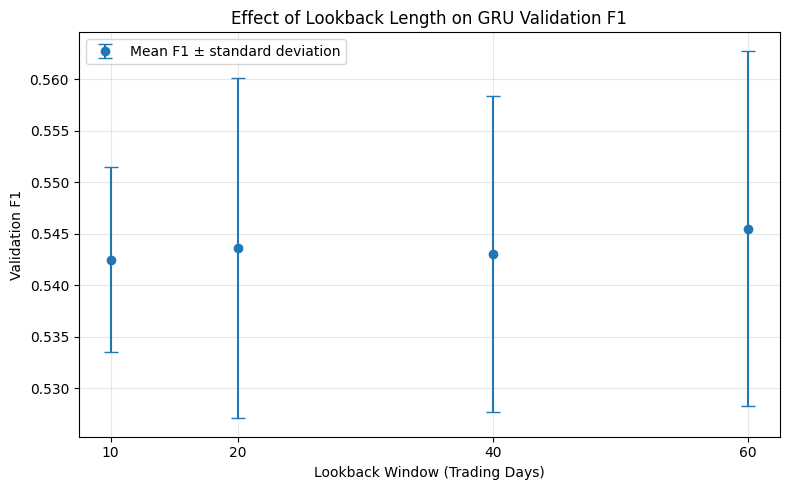

In [77]:
# Create the figure.
plt.figure(figsize=(8, 5))

# Plot mean validation F1 with standard deviation.
plt.errorbar(
    gru_lookback_summary.index,
    gru_lookback_summary["F1_mean"],
    yerr=gru_lookback_summary["F1_std"],
    fmt="o",
    capsize=5,
    label="Mean F1 ± standard deviation",
)

# Label the axes.
plt.xlabel("Lookback Window (Trading Days)")
plt.ylabel("Validation F1")

# Add the plot title.
plt.title("Effect of Lookback Length on GRU Validation F1")

# Display the tested lookback lengths.
plt.xticks(gru_lookback_lengths)

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the figure.
plt.tight_layout()
plt.show()

##### Step 5. Select the provisional best lookback length

In [78]:
# Identify the lookback length maximizing mean validation F1.
best_gru_lookback = int(
    gru_lookback_summary["F1_mean"].idxmax()
)

# Retrieve the corresponding mean F1.
best_gru_lookback_f1 = gru_lookback_summary.loc[
    best_gru_lookback,
    "F1_mean",
]

# Retrieve the corresponding standard deviation.
best_gru_lookback_std = gru_lookback_summary.loc[
    best_gru_lookback,
    "F1_std",
]

# Display the selected configuration.
print(f"Selected GRU lookback: {best_gru_lookback}")
print(f"Mean validation F1: {best_gru_lookback_f1:.4f}")
print(f"F1 standard deviation: {best_gru_lookback_std:.4f}")

Selected GRU lookback: 60
Mean validation F1: 0.5455
F1 standard deviation: 0.0173



### 5.9.4 Interpretation of GRU Lookback Experiments

We investigated the effect of lookback window length using

$$
L \in \{10,20,40,60\},
$$

while keeping the GRU hidden-state dimension fixed at 16.

Each configuration was trained using three random seeds.

The highest mean validation F1-score was obtained with a 60-day lookback:

$$
\overline{F1}_{60} \approx 0.5455,
\qquad
s_{F1,60} \approx 0.0173.
$$

However, all four configurations achieved similar mean F1-scores, ranging from approximately $0.5425$ to $0.5455$.

The maximum difference between the mean F1-scores was therefore only

$$
\Delta F1 \approx 0.0030.
$$

This difference is small relative to the variation across random seeds.

The 60-day configuration also achieved the highest mean ROC-AUC and PR-AUC, whereas the 40-day configuration achieved the lowest mean log loss.

Interestingly, the 10-day configuration exhibited the smallest F1 standard deviation, suggesting greater stability across the three random seeds.

**Comparison with LSTM.** In our earlier LSTM experiment, the 20-day lookback achieved the highest mean validation F1-score of approximately $0.5781$.

In contrast, the GRU exhibited relatively little sensitivity to the lookback length.

These observations suggest that the two recurrent architectures may utilize temporal information differently, although further experiments would be required to establish this conclusively.

**Conclusion.** Following our predefined selection criterion, we provisionally select

$$
\boxed{L=60}
$$

for the GRU classifier.

However, the evidence favoring 60 days over shorter windows is weak. We therefore retain the possibility of choosing a shorter lookback if it offers comparable performance with lower computational cost.

The next experiment will investigate the effect of dropout regularization while keeping the GRU hidden-state dimension and lookback length fixed.

The held-out test dataset remains untouched.



### 5.9.6 Effect of Dropout Regularization on GRU Performance

Our previous experiments investigated the effects of the GRU hidden-state dimension and lookback window length.

We provisionally selected the following configuration:

- **GRU units:** 16
- **Lookback length:** 60 trading days
- **Dropout:** 0

We now investigate whether dropout regularization improves the generalization performance of this configuration.

#### Dropout in a GRU

Dropout is a regularization technique in which a randomly selected fraction of neural-network activations is set to zero during training.

In a Keras GRU layer, two dropout parameters are available:

1. `dropout`: the fraction of input connections dropped during training.
2. `recurrent_dropout`: the fraction of recurrent-state connections dropped during training.

These parameters affect different parts of the recurrent computation.

In the present experiment, we vary only the input dropout rate:

$$
p \in \{0,0.1,0.2,0.3\},
$$

while keeping

$$
\text{recurrent\_dropout}=0.
$$

This allows us to isolate the effect of input dropout.

#### Example

If the dropout rate is $p=0.2$, approximately 20% of the relevant input connections are randomly suppressed during training.

During inference, dropout is disabled.

#### Experimental protocol

For each dropout rate, we train three GRU models using the random seeds

$$
s\in\{42,123,2026\}.
$$

All models use:

- 16 GRU units.
- A 60-day lookback window.
- The same training and validation datasets.
- The same optimizer, learning rate, batch size, and early-stopping procedure.
- The same classification-threshold search used in the preceding experiments.

For each run, the decision threshold is selected by maximizing validation F1 over the predefined threshold grid.

We record:

1. Best epoch and validation loss.
2. Selected classification threshold.
3. Validation F1-score.
4. Balanced accuracy.
5. ROC-AUC and PR-AUC.
6. Log loss.

We then summarize the mean and standard deviation of F1 across random seeds.

**Objective:** Determine whether input dropout improves GRU generalization compared with the unregularized baseline.

The held-out test dataset is not used during this experiment.


##### Step 1. Verify the dataset
We should explicitly use the 60-day dataset for all four dropout configurations.

In [79]:

# Retrieve the dataset for the selected 60-day lookback.
gru_dropout_dataset = lookback_datasets[60]

# Extract the training features and labels.
X_train_gru_dropout = gru_dropout_dataset["X_train"]
y_train_gru_dropout = gru_dropout_dataset["y_train"]

# Extract the validation features and labels.
X_val_gru_dropout = gru_dropout_dataset["X_val"]
y_val_gru_dropout = gru_dropout_dataset["y_val"]

# Display the dataset dimensions.
print("Training features:", X_train_gru_dropout.shape)
print("Training labels:", y_train_gru_dropout.shape)
print("Validation features:", X_val_gru_dropout.shape)
print("Validation labels:", y_val_gru_dropout.shape)

# Confirm that validation labels agree with the original evaluation.
assert np.array_equal(y_val_gru_dropout, y_val_gru)

# Confirm the selected lookback length.
assert X_train_gru_dropout.shape[1] == 60

# Confirm that the validation set contains 498 observations.
assert len(y_val_gru_dropout) == 498


Training features: (2645, 60, 3)
Training labels: (2645,)
Validation features: (498, 60, 3)
Validation labels: (498,)


##### Step 2. Train the GRU models
We will perform $4\times3=12$ training runs.

For consistency, this code uses the same general training protocol as our preceding experiments. In particular, the optimizer, learning rate, batch size, patience, and maximum epochs should match the settings already used in Section 5.9.

In [80]:

# Define the dropout rates to investigate.
gru_dropout_rates = [0.0, 0.1, 0.2, 0.3]

# Define the random seeds.
gru_dropout_seeds = [42, 123, 2026]

# Fix the selected number of GRU units.
GRU_DROPOUT_UNITS = 16

# Fix the lookback length.
GRU_DROPOUT_LOOKBACK = 60

# Define the classification thresholds.
gru_dropout_thresholds = np.arange(0.10, 0.91, 0.05)

# Store the experiment results.
gru_dropout_results = []

# Store the trained models.
gru_dropout_models = {}

# Iterate over the dropout rates.
for dropout_rate in gru_dropout_rates:

    # Iterate over the random seeds.
    for seed in gru_dropout_seeds:

        # Clear the previous Keras session.
        tf.keras.backend.clear_session()

        # Set the random seed.
        tf.keras.utils.set_random_seed(seed)

        # Construct the GRU classifier.
        model = tf.keras.Sequential([
            tf.keras.layers.Input(
                shape=(
                    GRU_DROPOUT_LOOKBACK,
                    X_train_gru_dropout.shape[2]
                )
            ),
            tf.keras.layers.GRU(
                GRU_DROPOUT_UNITS,
                dropout=dropout_rate,
                recurrent_dropout=0.0
            ),
            tf.keras.layers.Dense(
                1,
                activation="sigmoid"
            )
        ])

        # Compile the model.
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="binary_crossentropy"
        )

        # Configure early stopping.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the model.
        history = model.fit(
            X_train_gru_dropout,
            y_train_gru_dropout,
            validation_data=(
                X_val_gru_dropout,
                y_val_gru_dropout
            ),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val_gru_dropout,
            verbose=0
        ).ravel()

        # Calculate F1 at each candidate threshold.
        f1_values = [
            f1_score(
                y_val_gru_dropout,
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in gru_dropout_thresholds
        ]

        # Find the threshold maximizing validation F1.
        best_index = int(np.argmax(f1_values))

        # Retrieve the selected threshold.
        best_threshold = float(
            gru_dropout_thresholds[best_index]
        )

        # Generate predictions using that threshold.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the experiment results.
        gru_dropout_results.append({
            "Dropout": dropout_rate,
            "Seed": seed,
            "Best Epoch": int(
                np.argmin(history.history["val_loss"]) + 1
            ),
            "Threshold": best_threshold,
            "F1": f1_score(
                y_val_gru_dropout,
                predictions,
                zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val_gru_dropout,
                predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_val_gru_dropout,
                probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val_gru_dropout,
                probabilities
            ),
            "Log Loss": log_loss(
                y_val_gru_dropout,
                probabilities
            )
        })

        # Store the trained model.
        gru_dropout_models[(dropout_rate, seed)] = model

        # Display the progress.
        print(
            f"Dropout={dropout_rate:.1f}, "
            f"Seed={seed}, "
            f"F1={f1_values[best_index]:.4f}"
        )

# Construct the results DataFrame.
gru_dropout_df = pd.DataFrame(gru_dropout_results)

# Display all twelve experiments.
display(gru_dropout_df.round(4))


Dropout=0.0, Seed=42, F1=0.5440
Dropout=0.0, Seed=123, F1=0.5447
Dropout=0.0, Seed=2026, F1=0.5436
Dropout=0.1, Seed=42, F1=0.5660
Dropout=0.1, Seed=123, F1=0.5505
Dropout=0.1, Seed=2026, F1=0.5521
Dropout=0.2, Seed=42, F1=0.5759
Dropout=0.2, Seed=123, F1=0.5576
Dropout=0.2, Seed=2026, F1=0.5444
Dropout=0.3, Seed=42, F1=0.5736
Dropout=0.3, Seed=123, F1=0.5692
Dropout=0.3, Seed=2026, F1=0.5351


,Dropout,Seed,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,0.0,42,13,0.15,0.5440,0.7060,0.7752,0.5438,0.4798
1,0.0,123,12,0.35,0.5447,0.6946,0.7710,0.5367,0.4793
2,0.0,2026,23,0.10,0.5436,0.7083,0.7805,0.5314,0.4859
3,0.1,42,17,0.30,0.5660,0.7116,0.7789,0.5390,0.4733
4,0.1,123,20,0.20,0.5505,0.7079,0.7788,0.5513,0.4733
5,0.1,2026,21,0.15,0.5521,0.7128,0.7831,0.5481,0.4763
6,0.2,42,11,0.30,0.5759,0.7170,0.7760,0.5498,0.4736
7,0.2,123,12,0.30,0.5576,0.7062,0.7726,0.5510,0.4743
8,0.2,2026,22,0.15,0.5444,0.7061,0.7780,0.5515,0.4761
9,0.3,42,11,0.30,0.5736,0.7157,0.7729,0.5526,0.4750


##### Step 3. Summarize the results

In [81]:

# Group the experiments by dropout rate.
gru_dropout_summary = gru_dropout_df.groupby("Dropout").agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean")
)

# Display the summary statistics.
display(gru_dropout_summary.round(4))


,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Dropout,,,,,,
0.0,0.5441,0.0006,0.7030,0.7756,0.5373,0.4817
0.1,0.5562,0.0086,0.7108,0.7803,0.5461,0.4743
0.2,0.5593,0.0158,0.7098,0.7755,0.5508,0.4747
0.3,0.5593,0.0211,0.7089,0.7725,0.5552,0.4763


##### Step 4. Visualize the effect of dropout
Because dropout is tested at four discrete values, we will display individual points with standard-deviation error bars rather than implying a continuous relationship.

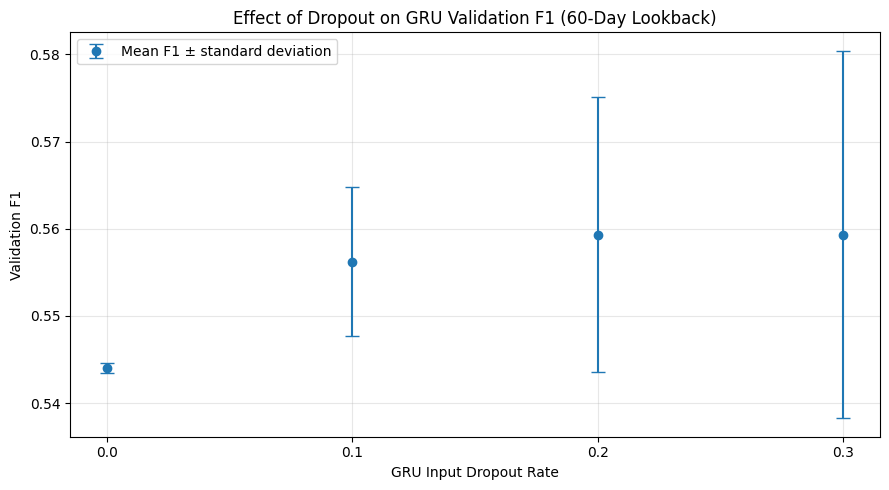

In [82]:

# Create the figure.
plt.figure(figsize=(9, 5))

# Plot mean validation F1 with standard-deviation error bars.
plt.errorbar(
    gru_dropout_summary.index,
    gru_dropout_summary["F1_mean"],
    yerr=gru_dropout_summary["F1_std"],
    fmt="o",
    capsize=5,
    label="Mean F1 ± standard deviation"
)

# Label the horizontal axis.
plt.xlabel("GRU Input Dropout Rate")

# Label the vertical axis.
plt.ylabel("Validation F1")

# Add a descriptive title.
plt.title("Effect of Dropout on GRU Validation F1 (60-Day Lookback)")

# Display the tested dropout values.
plt.xticks(gru_dropout_rates)

# Add a legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Adjust the layout.
plt.tight_layout()

# Display the figure.
plt.show()


##### Step 5. Select the provisional dropout rate

In [83]:

# Identify the dropout rate maximizing mean validation F1.
best_gru_dropout = float(
    gru_dropout_summary["F1_mean"].idxmax()
)

# Retrieve the corresponding mean F1.
best_gru_dropout_f1 = gru_dropout_summary.loc[
    best_gru_dropout,
    "F1_mean"
]

# Retrieve the corresponding F1 standard deviation.
best_gru_dropout_std = gru_dropout_summary.loc[
    best_gru_dropout,
    "F1_std"
]

# Display the selected configuration.
print(f"Selected GRU dropout: {best_gru_dropout:.2f}")
print(f"Mean validation F1: {best_gru_dropout_f1:.4f}")
print(f"F1 standard deviation: {best_gru_dropout_std:.4f}")


Selected GRU dropout: 0.30
Mean validation F1: 0.5593
F1 standard deviation: 0.0211


### 5.9.7 Interpretation of GRU Dropout Experiments

We investigated input dropout rates

$$
p\in\{0,0.1,0.2,0.3\}
$$

using 16 GRU units, a 60-day lookback window, and three random seeds.

The main findings are:

1. **Improvement in mean F1:** Dropout increased the mean validation F1 from approximately $0.5441$ without dropout to a maximum of approximately $0.5593$.

2. **Increasing variability:** The standard deviation of validation F1 increased with the dropout rate. The unregularized model was particularly stable across the three random seeds.

3. **Differences across evaluation metrics:** A dropout rate of $0.1$ achieved the highest mean ROC-AUC and lowest mean log loss, whereas $0.3$ achieved the highest mean PR-AUC.

4. **Limited evidence for strong dropout:** Although dropout rates of $0.2$ and $0.3$ achieved the highest mean F1, their improvements over $0.1$ were small relative to the observed variability.

We therefore provisionally select

$$
\boxed{p=0.1}
$$

as a stability-oriented compromise between classification performance and variability across random seeds.

This choice differs from selecting the dropout rate solely by maximum mean validation F1, which favored $p=0.3$ using unrounded results.

These experiments suggest that modest dropout can improve GRU generalization, but they do not establish a statistically significant advantage for any particular dropout rate.

The held-out test set remains untouched.


## 6. Comparative Evaluation of Recurrent Neural Networks

We have investigated three recurrent neural-network architectures for predicting increases in five-day realized volatility:

1. Simple Recurrent Neural Network (Simple RNN).
2. Long Short-Term Memory (LSTM).
3. Gated Recurrent Unit (GRU).

For the LSTM and GRU architectures, we performed controlled hyperparameter experiments involving hidden-state dimension, lookback window length, and input dropout.

We now compare their validation performance before selecting a final model.

### 6.1 Comparison of Selected LSTM and GRU Configurations

The provisional configurations are:

| Hyperparameter | LSTM | GRU |
|---|---|---|
| Hidden units | 16 | 16 |
| Lookback length | 20 trading days | 60 trading days |
| Input dropout | 0.1 | 0.1 |
| Recurrent dropout | 0 | 0 |
| Random seeds | 42, 123, 2026 | 42, 123, 2026 |

Our primary model-selection metric is the validation F1-score, averaged across the three random seeds.

We also examine:

- Standard deviation of F1 across seeds.
- Balanced accuracy.
- ROC-AUC.
- PR-AUC.
- Binary cross-entropy (log loss).

The classification decision threshold is selected from the same predefined grid for each trained model.

#### Two distinct comparison questions

We distinguish two questions:

**Question 1: Which selected configuration performs better?**

We compare the LSTM with a 20-day lookback against the GRU with a 60-day lookback.

This comparison evaluates the selected model configurations as complete predictive systems.

**Question 2: Which recurrent architecture performs better under matched conditions?**

To isolate architectural differences, we must hold the hidden-state dimension, lookback length, dropout, and training protocol fixed.

A matched experiment will therefore compare LSTM and GRU models using 16 units, a 20-day lookback, and input dropout of 0.1.

The first comparison is useful for selecting a practical predictive model. The second is useful for understanding the effect of recurrent architecture.

All comparisons use identical validation dates and labels.

The held-out test set remains untouched.


### 6.1.1 Compare the selected configurations
We already have the summary DataFrames from our hyperparameter experiments, so there is no reason to train the models again for this initial comparison.

The relevant variables are:
- controlled_dropout_summary: LSTM dropout experiment with a 20-day lookback.
- gru_dropout_summary: GRU dropout experiment with a 60-day lookback.
We will extract the results for dropout \(p=0.1\).

In [84]:

# Select the dropout rate for comparison.
comparison_dropout = 0.1

# Retrieve the LSTM results at the selected dropout rate.
lstm_selected = controlled_dropout_summary.loc[
    comparison_dropout
]

# Retrieve the GRU results at the selected dropout rate.
gru_selected = gru_dropout_summary.loc[
    comparison_dropout
]

# Construct a comparison table.
selected_model_comparison = pd.DataFrame(
    {
        "LSTM": lstm_selected,
        "GRU": gru_selected
    }
)

# Display the comparison.
display(selected_model_comparison.round(4))


,LSTM,GRU
F1_mean,0.5497,0.5562
F1_std,0.0060,0.0086
Balanced_Accuracy_mean,0.7012,0.7108
ROC_AUC_mean,0.7691,0.7803
PR_AUC_mean,0.5465,0.5461
Log_Loss_mean,0.4825,0.4743


### 6.1.2: Visualize the comparision

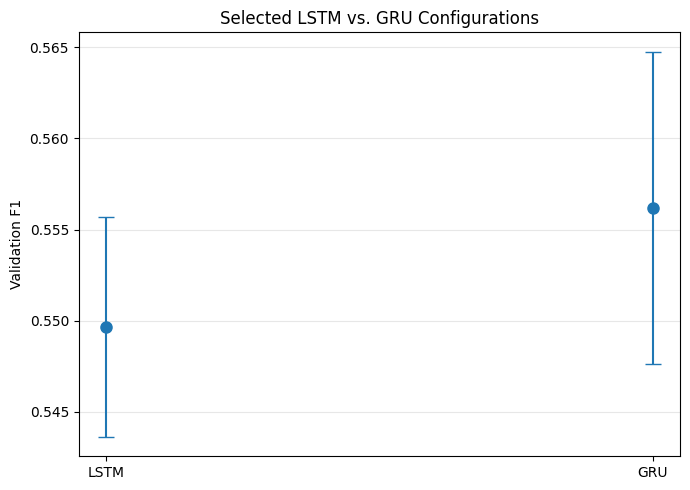

In [85]:

# Define the model names.
model_names = ["LSTM", "GRU"]

# Collect mean validation F1 scores.
mean_f1 = [
    lstm_selected["F1_mean"],
    gru_selected["F1_mean"]
]

# Collect F1 standard deviations.
std_f1 = [
    lstm_selected["F1_std"],
    gru_selected["F1_std"]
]

# Create the figure.
plt.figure(figsize=(7, 5))

# Plot mean F1 with standard-deviation error bars.
plt.errorbar(
    model_names,
    mean_f1,
    yerr=std_f1,
    fmt="o",
    capsize=6,
    markersize=8
)

# Label the vertical axis.
plt.ylabel("Validation F1")

# Add a descriptive title.
plt.title("Selected LSTM vs. GRU Configurations")

# Add a grid.
plt.grid(axis="y", alpha=0.3)

# Adjust the layout.
plt.tight_layout()

# Display the figure.
plt.show()



### 6.1.3 Results and Interpretation

The selected GRU configuration achieved a mean validation F1 of approximately $0.5562$, compared with $0.5497$ for the selected LSTM configuration.

The GRU also achieved higher mean balanced accuracy and ROC-AUC, together with lower mean log loss.

However, the LSTM exhibited slightly lower variability across random seeds and a marginally higher PR-AUC.

The difference in mean F1 was approximately

$$
\Delta F_1 = 0.5562 - 0.5497 = 0.0065.
$$

This improvement is relatively small compared with the variability observed across training runs.

Furthermore, the two configurations use different lookback lengths:

$$
L_{\mathrm{LSTM}}=20,
\qquad
L_{\mathrm{GRU}}=60.
$$

Therefore, the comparison does not isolate the effect of recurrent architecture.

**Conclusion:** The selected GRU configuration performs marginally better on several validation metrics, but the evidence is insufficient to conclude that the GRU architecture itself is superior to LSTM.

A matched-configuration experiment is required to investigate the architectural difference.


### 6.2 Matched LSTM–GRU Architecture Comparison

In Section 6.1, we compared the selected LSTM and GRU configurations. However, those models used different lookback lengths:

$$
L_{\mathrm{LSTM}}=20,
\qquad
L_{\mathrm{GRU}}=60.
$$

Consequently, their performance differences could arise from the recurrent architecture, the lookback length, or interactions between these choices.

We now perform a matched-configuration experiment to investigate the effect of recurrent architecture more directly.

#### Experimental configuration

Both architectures use:

| Hyperparameter | Value |
|---|---|
| Hidden-state dimension | 16 |
| Lookback length | 20 trading days |
| Input dropout | 0.1 |
| Recurrent dropout | 0 |
| Random seeds | 42, 123, 2026 |
| Output layer | Dense(1), sigmoid |
| Loss function | Binary cross-entropy |

We use identical training and validation observations, preprocessing, optimizer settings, early-stopping rules, and classification-threshold candidates.

The only intended architectural difference is the recurrent layer:

$$
\mathrm{LSTM}(16)
\quad\text{versus}\quad
\mathrm{GRU}(16).
$$

Although both models have the same hidden-state dimension, their numbers of trainable parameters differ because the LSTM uses four gates/candidate transformations, whereas the GRU uses three.

For each architecture, we train three models using different random seeds and calculate:

- Mean validation F1 and its standard deviation.
- Mean balanced accuracy.
- Mean ROC-AUC and PR-AUC.
- Mean log loss.
- Number of trainable parameters.

The decision threshold is selected by maximizing validation F1 over the same predefined grid for each model.

**Research question:** Under otherwise matched experimental conditions, does the LSTM or GRU architecture provide better predictive performance for our five-day volatility-increase classification task?

The held-out test dataset remains untouched.


#### Step 1. Retrieve and verify the matched dataset
We already have the required dataset in lookback_datasets[20].

In [86]:

# Retrieve the dataset with a 20-day lookback.
matched_dataset = lookback_datasets[20]

# Extract training features and labels.
X_train_matched = matched_dataset["X_train"]
y_train_matched = matched_dataset["y_train"]

# Extract validation features and labels.
X_val_matched = matched_dataset["X_val"]
y_val_matched = matched_dataset["y_val"]

# Verify the lookback dimension.
assert X_train_matched.shape[1] == 20

# Verify that training and validation features have the same number of channels.
assert X_train_matched.shape[2] == X_val_matched.shape[2]

# Verify that the validation labels match our original evaluation labels.
assert np.array_equal(y_val_matched, y_val)

# Display the dataset dimensions.
print("Training features:", X_train_matched.shape)
print("Training labels:", y_train_matched.shape)
print("Validation features:", X_val_matched.shape)
print("Validation labels:", y_val_matched.shape)


Training features: (2645, 20, 3)
Training labels: (2645,)
Validation features: (498, 20, 3)
Validation labels: (498,)


#### Step 2. Define the matched experiment
We will use the same three random seeds and classification-threshold grid for both architectures.

In [87]:
# Define the architectures to compare.
matched_architectures = ["LSTM", "GRU"]

# Define the random seeds.
matched_seeds = [42, 123, 2026]

# Fix the hidden-state dimension.
MATCHED_UNITS = 16

# Fix the input dropout rate.
MATCHED_DROPOUT = 0.1

# Define the classification thresholds.
matched_thresholds = np.arange(0.10, 0.91, 0.05)

# Store the results.
matched_results = []

# Store the trained models.
matched_models = {}


#### Step 3. Train the matched models
The following implementation uses a shared model-construction function so that the architecture is the only intended difference.

In [88]:
# Define a function to construct either recurrent architecture.
def build_matched_model(architecture):

    # Select the recurrent layer based on the requested architecture.
    if architecture == "LSTM":
        recurrent_layer = tf.keras.layers.LSTM(
            MATCHED_UNITS,
            dropout=MATCHED_DROPOUT,
            recurrent_dropout=0.0
        )

    # Construct a GRU layer when requested.
    elif architecture == "GRU":
        recurrent_layer = tf.keras.layers.GRU(
            MATCHED_UNITS,
            dropout=MATCHED_DROPOUT,
            recurrent_dropout=0.0
        )

    # Reject unsupported architecture names.
    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    # Construct the binary classifier.
    model = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(
                X_train_matched.shape[1],
                X_train_matched.shape[2]
            )
        ),
        recurrent_layer,
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    # Compile the classifier.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy"
    )

    # Return the compiled model.
    return model


#### Step 4. Run the six training experiments:

In [89]:
# Iterate over both recurrent architectures.
for architecture in matched_architectures:

    # Iterate over the three random seeds.
    for seed in matched_seeds:

        # Clear the previous TensorFlow/Keras session.
        tf.keras.backend.clear_session()

        # Set the random seed.
        tf.keras.utils.set_random_seed(seed)

        # Construct the selected architecture.
        model = build_matched_model(architecture)

        # Configure early stopping.
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        # Train the classifier.
        history = model.fit(
            X_train_matched,
            y_train_matched,
            validation_data=(
                X_val_matched,
                y_val_matched
            ),
            epochs=100,
            batch_size=32,
            callbacks=[early_stopping],
            verbose=0
        )

        # Generate validation probabilities.
        probabilities = model.predict(
            X_val_matched,
            verbose=0
        ).ravel()

        # Calculate F1 for every candidate threshold.
        f1_values = [
            f1_score(
                y_val_matched,
                (probabilities > threshold).astype(int),
                zero_division=0
            )
            for threshold in matched_thresholds
        ]

        # Identify the threshold maximizing F1.
        best_index = int(np.argmax(f1_values))

        # Retrieve the selected threshold.
        best_threshold = float(matched_thresholds[best_index])

        # Generate the selected binary predictions.
        predictions = (
            probabilities > best_threshold
        ).astype(int)

        # Record the evaluation results.
        matched_results.append({
            "Architecture": architecture,
            "Seed": seed,
            "Parameters": model.count_params(),
            "Best Epoch": int(
                np.argmin(history.history["val_loss"]) + 1
            ),
            "Threshold": best_threshold,
            "F1": f1_score(
                y_val_matched,
                predictions,
                zero_division=0
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val_matched,
                predictions
            ),
            "ROC-AUC": roc_auc_score(
                y_val_matched,
                probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val_matched,
                probabilities
            ),
            "Log Loss": log_loss(
                y_val_matched,
                probabilities
            )
        })

        # Store the trained model.
        matched_models[(architecture, seed)] = model

        # Display the progress.
        print(
            f"{architecture}, "
            f"Seed={seed}, "
            f"F1={f1_values[best_index]:.4f}"
        )

# Construct the experiment results table.
matched_df = pd.DataFrame(matched_results)

# Display all six experiments.
display(matched_df.round(4))


LSTM, Seed=42, F1=0.5714
LSTM, Seed=123, F1=0.5559
LSTM, Seed=2026, F1=0.5608
GRU, Seed=42, F1=0.5645
GRU, Seed=123, F1=0.5651
GRU, Seed=2026, F1=0.5645


,Architecture,Seed,Parameters,Best Epoch,Threshold,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,LSTM,42,1297,28,0.30,0.5714,0.7168,0.7886,0.5559,0.4673
1,LSTM,123,1297,17,0.20,0.5559,0.7156,0.7736,0.5360,0.4754
2,LSTM,2026,1297,12,0.20,0.5608,0.7124,0.7714,0.5457,0.4917
3,GRU,42,1025,20,0.25,0.5645,0.7139,0.7732,0.5456,0.4755
4,GRU,123,1025,21,0.30,0.5651,0.7115,0.7750,0.5457,0.4737
5,GRU,2026,1025,12,0.25,0.5645,0.7079,0.7726,0.5627,0.4895


#### Step 4. Summarize performance across seeds

In [90]:
# Group the experiments by architecture.
matched_summary = matched_df.groupby("Architecture").agg(
    Parameters=("Parameters", "first"),
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    ROC_AUC_mean=("ROC-AUC", "mean"),
    PR_AUC_mean=("PR-AUC", "mean"),
    Log_Loss_mean=("Log Loss", "mean")
)

# Display the summary statistics.
display(matched_summary.round(4))


,Parameters,F1_mean,F1_std,Balanced_Accuracy_mean,ROC_AUC_mean,PR_AUC_mean,Log_Loss_mean
Architecture,,,,,,,
GRU,1025,0.5647,0.0003,0.7111,0.7736,0.5514,0.4796
LSTM,1297,0.5627,0.0079,0.7149,0.7779,0.5459,0.4782


#### Step 5. Visualize the matched comparison

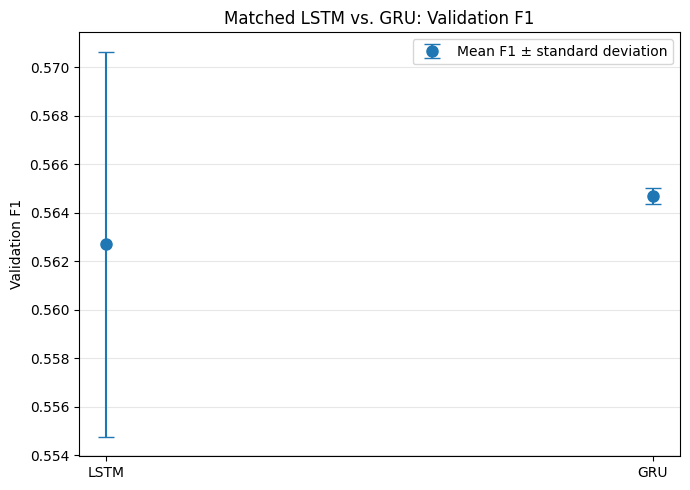

In [91]:

# Retrieve the architecture names in a fixed order.
architectures = ["LSTM", "GRU"]

# Extract the mean validation F1 values.
mean_f1 = matched_summary.loc[
    architectures,
    "F1_mean"
]

# Extract the F1 standard deviations.
std_f1 = matched_summary.loc[
    architectures,
    "F1_std"
]

# Create the figure.
plt.figure(figsize=(7, 5))

# Plot the mean F1 scores with standard-deviation error bars.
plt.errorbar(
    architectures,
    mean_f1,
    yerr=std_f1,
    fmt="o",
    capsize=6,
    markersize=8,
    label="Mean F1 ± standard deviation"
)

# Label the vertical axis.
plt.ylabel("Validation F1")

# Add a descriptive title.
plt.title("Matched LSTM vs. GRU: Validation F1")

# Add a grid and legend.
plt.grid(axis="y", alpha=0.3)
plt.legend()

# Adjust the layout.
plt.tight_layout()

# Display the figure.
plt.show()



### 6.2.5 Interpretation of the Matched Architecture Experiment

We compared LSTM and GRU classifiers under matched experimental conditions:

$$
L=20,\qquad h=16,\qquad p=0.1,
$$

using random seeds $42$, $123$, and $2026$.

The GRU achieved a slightly higher mean validation F1:

$$
\overline{F}_{1,\mathrm{GRU}}=0.5647,
\qquad
\overline{F}_{1,\mathrm{LSTM}}=0.5627.
$$

However, the difference was only $0.0020$, indicating broadly comparable classification performance.

The GRU also exhibited lower variation across random seeds:

$$
\sigma_{\mathrm{GRU}}=0.0003,
\qquad
\sigma_{\mathrm{LSTM}}=0.0079.
$$

This suggests greater stability in the present experiment, although additional runs would be necessary to establish whether this difference persists.

The LSTM achieved slightly higher ROC-AUC and lower log loss, whereas the GRU achieved higher PR-AUC. Thus, neither architecture dominated across all evaluation metrics.

The GRU required 1,025 trainable parameters compared with 1,297 for the LSTM, representing approximately a 21% reduction.

**Conclusion.** Under matched experimental conditions, the LSTM and GRU achieved similar predictive performance. The GRU offered a small advantage in mean F1, seed-to-seed stability, and parameter efficiency, while the LSTM performed slightly better on some probability-based metrics.

These results do not establish universal architectural superiority. They characterize performance on our particular dataset and validation period.


## 6.3 Final Sequence-Model Selection

We have investigated three recurrent neural network architectures:

1. Simple Recurrent Neural Network (Simple RNN).
2. Long Short-Term Memory (LSTM).
3. Gated Recurrent Unit (GRU).

For LSTM and GRU, we also investigated the effects of hidden-state dimension, lookback length, and dropout regularization. We evaluated configurations using a chronological validation dataset and multiple random seeds.

Our objective is now to select a final sequence-model configuration for predicting whether future five-day realized volatility will exceed its recent historical level by the specified threshold.

### 6.3.1 Model Selection Criterion

Let $\mathcal{M}$ denote the set of candidate model configurations. For each configuration $m\in\mathcal{M}$, we evaluate its validation F1-score across random seeds:

$$
F_1(m,s_1),\ldots,F_1(m,s_K).
$$

The mean validation F1-score is

$$
\overline{F}_1(m)
=
\frac{1}{K}\sum_{i=1}^{K}F_1(m,s_i).
$$

We use mean validation F1 as our primary selection criterion:

$$
m^*
=
\operatorname*{arg\,max}_{m\in\mathcal{M}}
\overline{F}_1(m).
$$

We additionally consider:

- Standard deviation of validation F1 across random seeds.
- Balanced accuracy.
- ROC-AUC and PR-AUC.
- Binary cross-entropy (log loss).
- Number of trainable parameters.

These secondary metrics help us assess the robustness, discrimination, calibration-related performance, and computational complexity of the candidate models.

**Important:** Each model's classification threshold is selected using validation data. The test set is not involved in hyperparameter selection, threshold selection, or model comparison.

### 6.3.2 Comparing Architectures and Configurations

We distinguish two types of comparisons.

**Matched architecture comparison**

LSTM and GRU are trained using identical hyperparameters, random seeds, datasets, and training procedures. This allows us to investigate architectural differences under controlled experimental conditions.

**Selected configuration comparison**

Each architecture is evaluated using the hyperparameters selected during its validation experiments.

This comparison addresses a different question: which experimentally selected configuration performs best for our prediction task?

Because the configurations may have different lookback lengths and regularization settings, differences in performance cannot be attributed solely to the recurrent architecture.

### 6.3.3 Model Selection and the Held-Out Test Set

After selecting the final model configuration, we will freeze:

1. The recurrent architecture.
2. The lookback length.
3. The number of hidden units.
4. The dropout rate.
5. The training and early-stopping procedure.
6. The classification threshold.

We will then evaluate the final model on the held-out test dataset.

The test dataset must not influence any of these decisions.

Since repeated experiments on the same validation period can introduce model-selection bias, the final validation performance should be regarded as an estimate used for selection rather than an unbiased estimate of future performance.

#### Step 2. Consolidate our existing results
We already have the results stored in several DataFrames. Rather than manually entering numerical values, we should construct the comparison directly from these results.

We will begin with the strongest LSTM and GRU configurations from the controlled dropout experiments, since those experiments used the selected lookback lengths.

In [92]:

# Select the LSTM configuration with the highest mean validation F1.
best_lstm_dropout = float(
    controlled_dropout_summary["F1_mean"].idxmax()
)

# Select the GRU configuration with the highest mean validation F1.
best_gru_dropout = float(
    gru_dropout_summary["F1_mean"].idxmax()
)

# Retrieve the corresponding LSTM validation statistics.
lstm_selected = controlled_dropout_summary.loc[
    best_lstm_dropout
]

# Retrieve the corresponding GRU validation statistics.
gru_selected = gru_dropout_summary.loc[
    best_gru_dropout
]

# Construct the selected-configuration comparison.
selected_comparison = pd.DataFrame(
    [
        {
            "Architecture": "LSTM",
            "Units": 16,
            "Lookback": 20,
            "Dropout": best_lstm_dropout,
            "F1 Mean": lstm_selected["F1_mean"],
            "F1 Std": lstm_selected["F1_std"],
            "Balanced Accuracy": lstm_selected["Balanced_Accuracy_mean"],
            "ROC-AUC": lstm_selected["ROC_AUC_mean"],
            "PR-AUC": lstm_selected["PR_AUC_mean"],
            "Log Loss": lstm_selected["Log_Loss_mean"],
        },
        {
            "Architecture": "GRU",
            "Units": 16,
            "Lookback": 60,
            "Dropout": best_gru_dropout,
            "F1 Mean": gru_selected["F1_mean"],
            "F1 Std": gru_selected["F1_std"],
            "Balanced Accuracy": gru_selected["Balanced_Accuracy_mean"],
            "ROC-AUC": gru_selected["ROC_AUC_mean"],
            "PR-AUC": gru_selected["PR_AUC_mean"],
            "Log Loss": gru_selected["Log_Loss_mean"],
        },
    ]
)

# Sort the configurations by their mean validation F1.
selected_comparison = selected_comparison.sort_values(
    "F1 Mean",
    ascending=False
)

# Display the comparison.
display(selected_comparison.round(4))

,Architecture,Units,Lookback,Dropout,F1 Mean,F1 Std,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
1,GRU,16,60,0.3,0.5593,0.0211,0.7089,0.7725,0.5552,0.4763
0,LSTM,16,20,0.1,0.5497,0.0060,0.7012,0.7691,0.5465,0.4825



### 6.3.4 Consolidation of Candidate Models

We now consolidate the validation results from our Simple RNN, LSTM, and GRU experiments.

Our candidate configurations include:

1. The strongest Simple RNN configuration.
2. The selected LSTM configuration.
3. The selected GRU configuration.
4. The matched LSTM experiment.
5. The matched GRU experiment.

We distinguish between a **model configuration** and an **experimental run**.

A model configuration is specified by its architecture and hyperparameters:

$$
m=(A,h,L,p),
$$

where:

- $A$ is the recurrent architecture.
- $h$ is the number of hidden units.
- $L$ is the lookback window.
- $p$ is the input dropout rate.

An experimental run additionally depends on the random seed and training procedure.

Consequently, repeated evaluations of the same configuration may produce different validation scores.

Our final comparison will preserve the experimental provenance of each result rather than treating repeated evaluations as independent model configurations.

We will use mean validation F1 as the primary selection metric, while considering variability across random seeds, probability-based metrics, and model complexity.

Before selecting the final model, we will verify that the experiments use identical validation labels and dates, together with a consistent classification-threshold selection procedure.


#### Step 1. Construct the consolidated comparison table
We already have three DataFrames:
- selected_comparison
- matched_summary
- The Simple RNN results from our earlier experiments
First, combine the LSTM and GRU results. We will add the Simple RNN after identifying its corresponding summary DataFrame.

In [93]:

# Copy the selected-configuration results.
selected_candidates = selected_comparison.copy()

# Identify the source experiment.
selected_candidates["Experiment"] = "Selected configuration"

# Copy the matched-architecture results.
matched_candidates = matched_summary.reset_index().copy()

# Rename the columns to match the selected-configuration table.
matched_candidates = matched_candidates.rename(
    columns={
        "F1_mean": "F1 Mean",
        "F1_std": "F1 Std",
        "Balanced_Accuracy_mean": "Balanced Accuracy",
        "ROC_AUC_mean": "ROC-AUC",
        "PR_AUC_mean": "PR-AUC",
        "Log_Loss_mean": "Log Loss",
        "Parameters": "Parameters",
    }
)

# Record the shared hyperparameters of the matched experiment.
matched_candidates["Units"] = 16
matched_candidates["Lookback"] = 20
matched_candidates["Dropout"] = 0.1

# Identify the source experiment.
matched_candidates["Experiment"] = "Matched architecture"

# Combine the two sets of results.
candidate_comparison = pd.concat(
    [selected_candidates, matched_candidates],
    ignore_index=True
)

# Arrange the columns consistently.
candidate_columns = [
    "Architecture",
    "Experiment",
    "Units",
    "Lookback",
    "Dropout",
    "F1 Mean",
    "F1 Std",
    "Balanced Accuracy",
    "ROC-AUC",
    "PR-AUC",
    "Log Loss",
]

# Display the consolidated results.
display(
    candidate_comparison[candidate_columns]
    .sort_values("F1 Mean", ascending=False)
    .round(4)
)


,Architecture,Experiment,Units,Lookback,Dropout,F1 Mean,F1 Std,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
2,GRU,Matched architecture,16,20,0.1,0.5647,0.0003,0.7111,0.7736,0.5514,0.4796
3,LSTM,Matched architecture,16,20,0.1,0.5627,0.0079,0.7149,0.7779,0.5459,0.4782
0,GRU,Selected configuration,16,60,0.3,0.5593,0.0211,0.7089,0.7725,0.5552,0.4763
1,LSTM,Selected configuration,16,20,0.1,0.5497,0.0060,0.7012,0.7691,0.5465,0.4825


#### Step 2. Check for repeated configurations

In [94]:
# Define the columns identifying a model configuration.
configuration_columns = [
    "Architecture",
    "Units",
    "Lookback",
    "Dropout",
]

# Identify rows corresponding to repeated configurations.
repeated_configurations = candidate_comparison.duplicated(
    subset=configuration_columns,
    keep=False
)

# Display repeated configurations and their experimental results.
display(
    candidate_comparison.loc[
        repeated_configurations,
        candidate_columns
    ].sort_values(configuration_columns).round(4)
)

,Architecture,Experiment,Units,Lookback,Dropout,F1 Mean,F1 Std,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
1,LSTM,Selected configuration,16,20,0.1,0.5497,0.0060,0.7012,0.7691,0.5465,0.4825
3,LSTM,Matched architecture,16,20,0.1,0.5627,0.0079,0.7149,0.7779,0.5459,0.4782


#### Step 3. Verify the validation labels
Before comparing model performance, check that the validation labels for the two lookback lengths are identical.

In [95]:
# Retrieve the validation labels for the 20-day lookback.
labels_20 = lookback_datasets[20]["y_val"]

# Retrieve the validation labels for the 60-day lookback.
labels_60 = lookback_datasets[60]["y_val"]

# Compare the validation dataset sizes.
print("20-day validation size:", len(labels_20))
print("60-day validation size:", len(labels_60))

# Check whether the validation labels are identical.
print(
    "Identical validation labels:",
    np.array_equal(labels_20, labels_60)
)

# Check whether the original validation labels agree.
print(
    "Original validation labels agree:",
    np.array_equal(y_val, labels_20)
)


20-day validation size: 498
60-day validation size: 498
Identical validation labels: True
Original validation labels agree: True


#### Step 4. Include the simple RNN

In [96]:

# Find existing notebook variables related to Simple RNN experiments.
rnn_variables = sorted(
    name
    for name in globals()
    if "rnn" in name.lower()
    and not name.startswith("_")
)

# Display the matching variable names.
print(rnn_variables)


['RNN_MODEL_DIR', 'RNN_RESULTS_DIR', 'RNN_THRESHOLD', 'RNN_UNITS', 'best_rnn_threshold', 'rnn_config', 'rnn_df', 'rnn_history', 'rnn_model', 'rnn_model_dir', 'rnn_results_dir', 'rnn_val_metrics', 'rnn_val_pred', 'rnn_val_pred_best', 'rnn_val_prob', 'rnn_validation_results']


#### Step 5. Inspect the Simple RNN configuration and validation results

In [97]:
# Display the Simple RNN configuration.
print("Simple RNN configuration:")
print(rnn_config)

# Display the original Simple RNN validation metrics.
print("\nSimple RNN validation metrics:")
print(rnn_val_metrics)

# Display the additional validation results.
print("\nSimple RNN validation results:")
print(rnn_validation_results)

# Display the selected classification threshold.
print("\nSelected Simple RNN threshold:")
print(best_rnn_threshold)

# Display the number of validation predictions.
print("\nNumber of validation probabilities:")
print(len(rnn_val_prob))

# Display the number of validation labels.
print("\nNumber of validation labels:")
print(len(y_val))


Simple RNN configuration:
{'model': 'SimpleRNN', 'lookback': 20, 'features': ['log_return', 'squared_return', 'vol_20d'], 'hidden_units': 16, 'selected_threshold': 0.2, 'selection_metric': 'validation_f1', 'training_end': '2020-12-23', 'validation_start': '2021-01-04', 'validation_end': '2022-12-22'}

Simple RNN validation metrics:
{'Accuracy': 0.7690763052208835, 'Balanced Accuracy': 0.5593958013312852, 'Precision': 0.7391304347826086, 'Recall': 0.1349206349206349, 'F1': 0.22818791946308725, 'ROC-AUC': 0.7441329578426352, 'PR-AUC': 0.5225319709775815, 'Log Loss': 0.5114532113075256}

Simple RNN validation results:
          date  actual_label  predicted_probability  predicted_label
0   2021-01-04             1               0.405177                1
1   2021-01-05             1               0.395120                1
2   2021-01-06             1               0.278721                1
3   2021-01-07             0               0.194342                0
4   2021-01-08             0    

##### Add simple RNN to the consolidated table

In [98]:
# Construct the Simple RNN candidate from its saved configuration and metrics.
simple_rnn_candidate = pd.DataFrame(
    [{
        "Architecture": "Simple RNN",
        "Experiment": "Single-run baseline",
        "Units": rnn_config["hidden_units"],
        "Lookback": rnn_config["lookback"],
        "Dropout": 0.0,
        "F1 Mean": rnn_val_metrics["F1"],
        "F1 Std": np.nan,
        "Balanced Accuracy": rnn_val_metrics["Balanced Accuracy"],
        "ROC-AUC": rnn_val_metrics["ROC-AUC"],
        "PR-AUC": rnn_val_metrics["PR-AUC"],
        "Log Loss": rnn_val_metrics["Log Loss"],
    }]
)

# Combine the Simple RNN with the LSTM and GRU candidates.
final_candidates = pd.concat(
    [candidate_comparison, simple_rnn_candidate],
    ignore_index=True
)

# Sort all experimental summaries by validation F1.
final_candidates = final_candidates.sort_values(
    "F1 Mean",
    ascending=False
).reset_index(drop=True)

# Display the consolidated comparison.
display(final_candidates[candidate_columns].round(4))

,Architecture,Experiment,Units,Lookback,Dropout,F1 Mean,F1 Std,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss
0,GRU,Matched architecture,16,20,0.1,0.5647,0.0003,0.7111,0.7736,0.5514,0.4796
1,LSTM,Matched architecture,16,20,0.1,0.5627,0.0079,0.7149,0.7779,0.5459,0.4782
2,GRU,Selected configuration,16,60,0.3,0.5593,0.0211,0.7089,0.7725,0.5552,0.4763
3,LSTM,Selected configuration,16,20,0.1,0.5497,0.0060,0.7012,0.7691,0.5465,0.4825
4,Simple RNN,Single-run baseline,16,20,0.0,0.2282,NaN,0.5594,0.7441,0.5225,0.5115


##### Verify the Simple RNN validation dates and labels

In [99]:
# Extract the Simple RNN validation dates.
rnn_dates = pd.to_datetime(
    rnn_validation_results["date"]
)

# Extract the corresponding validation labels.
rnn_labels = rnn_validation_results["actual_label"].to_numpy()

# Check that the Simple RNN labels agree with the sequence datasets.
print(
    "Simple RNN labels match:",
    np.array_equal(rnn_labels, lookback_datasets[20]["y_val"])
)

# Display the validation period.
print("First validation date:", rnn_dates.min())
print("Last validation date:", rnn_dates.max())

# Verify that dates are unique and chronologically ordered.
print("Unique dates:", rnn_dates.is_unique)
print("Chronological order:", rnn_dates.is_monotonic_increasing)


Simple RNN labels match: True
First validation date: 2021-01-04 00:00:00
Last validation date: 2022-12-22 00:00:00
Unique dates: True
Chronological order: True



### 6.3.5 Final Model Selection and Reproducibility

We have completed the initial experiments with three recurrent architectures:

1. Simple RNN
2. Long Short-Term Memory (LSTM)
3. Gated Recurrent Unit (GRU)

The experiments investigated hidden-state dimension, lookback length, and dropout regularization. We also performed a matched LSTM–GRU comparison using identical hyperparameters.

#### Final architecture selection

We select the following GRU configuration as our final sequence-model candidate:

| Hyperparameter | Selected value |
|---|---|
| Architecture | GRU |
| Hidden units | 16 |
| Lookback length | 20 trading days |
| Input features | Log return, squared return, 20-day volatility |
| Input dropout | 0.1 |
| Recurrent dropout | 0 |
| Training seeds | 42, 123, 2026 |
| Primary selection metric | Validation F1 |

In the matched-architecture experiment, this configuration achieved:

$$
\overline{F_1}=0.5647,
\qquad
s_{F_1}=0.0003.
$$

The corresponding LSTM configuration achieved:

$$
\overline{F_1}=0.5627,
\qquad
s_{F_1}=0.0079.
$$

The GRU also required fewer trainable parameters:

$$
N_{\mathrm{GRU}}=1025,
\qquad
N_{\mathrm{LSTM}}=1297.
$$

The difference in mean F1 is small. Therefore, these results do not establish a general superiority of GRU over LSTM. Nevertheless, the GRU provides a reasonable final candidate because of its validation performance, relatively low variability across the tested seeds, and smaller parameter count.

#### Model-selection protocol

To avoid introducing additional selection bias, we freeze the following decisions before evaluating the test set:

1. **Architecture:** GRU.
2. **Hidden-state dimension:** 16.
3. **Lookback:** 20 trading days.
4. **Input dropout:** 0.1.
5. **Recurrent dropout:** 0.
6. **Training procedure:** Retain the optimizer, loss function, batch size, early-stopping rule, and other training settings used in the matched experiment.
7. **Random seeds:** 42, 123, and 2026.
8. **Classification threshold:** Determine from the existing validation predictions using the previously established threshold grid and selection rule.
9. **Primary evaluation metric:** F1, supplemented by balanced accuracy, precision, recall, ROC-AUC, PR-AUC, and log loss.

No additional hyperparameter search will be performed.

#### Checkpoint selection

For each random seed, the training procedure identifies a checkpoint using the minimum validation loss:

$$
e_s^*
=
\operatorname*{arg\,min}_{e}
\mathcal{L}_{\mathrm{val}}(\theta_{s,e}),
$$

where $s$ denotes the random seed and $\theta_{s,e}$ denotes the model parameters at epoch $e$.

The selected checkpoint is

$$
\theta_s^*=\theta_{s,e_s^*}.
$$

This is distinct from classification-threshold selection, which uses validation F1.

#### Classification-threshold selection

For a predicted probability $\hat p_t$, the binary classification rule is

$$
\hat y_t(\tau)
=
\mathbf{1}\{\hat p_t\geq\tau\}.
$$

We use the previously established threshold grid

$$
\mathcal{T}=\{0.10,0.15,\ldots,0.90\}.
$$

To obtain one common threshold across random seeds, we select

$$
\tau^*
=
\operatorname*{arg\,max}_{\tau\in\mathcal{T}}
\frac{1}{3}
\sum_{s\in\{42,123,2026\}}
F_{1,\mathrm{val}}^{(s)}(\tau).
$$

In the event of a tie, we choose the smallest threshold.

The threshold is selected using validation predictions only. It remains fixed during test evaluation.

#### Final evaluation protocol

We retain the three trained GRU models and evaluate each on the same held-out test observations.

For every seed, we report classification metrics using the common threshold $\tau^*$.

We then summarize the test results using the mean and standard deviation across seeds.

This approach measures variability associated with the three training runs without selecting the most favorable seed after observing the test results.

The test set is used only for final evaluation, not for architecture selection, checkpoint selection, threshold tuning, or hyperparameter optimization.

#### Limitations

The validation set has been reused across multiple experiments. Consequently, the selected validation F1 may be optimistic.

Furthermore, three random seeds provide only a limited estimate of training variability. The reported standard deviations should not be interpreted as confidence intervals.

The held-out test evaluation will provide an estimate of performance on the subsequent historical period, but it cannot establish performance across all future market regimes.


##### Freeze the selected configuration

In [100]:
# Define the final GRU architecture and training seeds.
final_gru_config = {
    "architecture": "GRU",
    "hidden_units": 16,
    "lookback": 20,
    "dropout": 0.1,
    "recurrent_dropout": 0.0,
    "seeds": [42, 123, 2026],
    "selection_metric": "validation_f1",
    "checkpoint_metric": "val_loss",
}

# Preserve the previously established classification threshold grid.
final_threshold_grid = np.round(
    np.arange(0.10, 0.901, 0.05),
    2
)

# Display the frozen configuration.
print("Final sequence-model configuration:")

# Print each configuration entry.
for key, value in final_gru_config.items():
    print(f"{key}: {value}")

# Display the threshold grid.
print("Threshold grid:", final_threshold_grid)

Final sequence-model configuration:
architecture: GRU
hidden_units: 16
lookback: 20
dropout: 0.1
recurrent_dropout: 0.0
seeds: [42, 123, 2026]
selection_metric: validation_f1
checkpoint_metric: val_loss
Threshold grid: [0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9 ]


Recover the GRU validation probabilities

In [104]:

# Initialize a dictionary for the GRU validation probabilities.
gru_val_probabilities = {}

# Retrieve predictions from each trained GRU model.
for seed in final_gru_config["seeds"]:

    # Retrieve the GRU model corresponding to this seed.
    model = matched_models[("GRU", seed)]

    # Predict probabilities on the matched validation dataset.
    probabilities = model.predict(
        X_val_matched,
        verbose=0
    ).reshape(-1)

    # Store the predictions under the corresponding seed.
    gru_val_probabilities[seed] = probabilities

    # Verify the number of predictions.
    assert len(probabilities) == len(y_val_matched)

    # Display the prediction range.
    print(
        f"Seed {seed}: "
        f"{len(probabilities)} predictions, "
        f"range [{probabilities.min():.4f}, "
        f"{probabilities.max():.4f}]"
    )


Seed 42: 498 predictions, range [0.0237, 0.8705]
Seed 123: 498 predictions, range [0.0200, 0.8529]
Seed 2026: 498 predictions, range [0.0186, 0.8464]


##### Select the common classification threshold

In [105]:

# Import the F1 metric.
from sklearn.metrics import f1_score

# Retrieve the validation labels for the selected lookback.
final_y_val = y_val_matched

# Collect validation F1 scores for every threshold.
threshold_records = []

# Evaluate each candidate classification threshold.
for threshold in final_threshold_grid:

    # Store the F1 score for each training seed.
    seed_scores = []

    # Evaluate the threshold for every selected seed.
    for seed in final_gru_config["seeds"]:

        # Retrieve the saved validation probabilities.
        probabilities = np.asarray(
            gru_val_probabilities[seed]
        ).reshape(-1)

        # Check that predictions and labels have identical lengths.
        assert len(probabilities) == len(final_y_val)

        # Convert probabilities into binary predictions.
        predictions = (
            probabilities >= threshold
        ).astype(int)

        # Calculate validation F1.
        score = f1_score(
            final_y_val,
            predictions,
            zero_division=0
        )

        # Store this seed's score.
        seed_scores.append(score)

    # Store the average F1 across seeds.
    threshold_records.append({
        "Threshold": threshold,
        "Mean F1": np.mean(seed_scores),
        "F1 Std": np.std(seed_scores, ddof=1),
    })

# Construct the threshold comparison table.
final_threshold_df = pd.DataFrame(threshold_records)

# Select the highest mean F1, breaking ties toward smaller thresholds.
final_threshold_df = final_threshold_df.sort_values(
    ["Mean F1", "Threshold"],
    ascending=[False, True]
)

# Freeze the selected classification threshold.
final_gru_threshold = float(
    final_threshold_df.iloc[0]["Threshold"]
)

# Display the threshold results.
display(final_threshold_df.round(4))

# Display the selected threshold.
print(f"Final GRU threshold: {final_gru_threshold:.2f}")


,Threshold,Mean F1,F1 Std
3,0.25,0.5604,0.0071
4,0.30,0.5577,0.0107
2,0.20,0.5477,0.0021
1,0.15,0.5338,0.0089
5,0.35,0.5164,0.0295
0,0.10,0.4905,0.0058
6,0.40,0.4396,0.0623
7,0.45,0.3730,0.0605
8,0.50,0.3374,0.0545
9,0.55,0.2541,0.0519


Final GRU threshold: 0.25


Add a final consistency check

In [106]:
# Verify that the selected threshold belongs to the predefined grid.
assert final_gru_threshold in final_threshold_grid

# Verify that the selected threshold maximizes mean validation F1.
assert np.isclose(
    final_threshold_df.iloc[0]["Mean F1"],
    final_threshold_df["Mean F1"].max()
)

# Verify that all validation probabilities are finite and valid.
for seed in final_gru_config["seeds"]:

    # Retrieve the probability vector.
    probabilities = gru_val_probabilities[seed]

    # Check that all probabilities are finite.
    assert np.all(np.isfinite(probabilities))

    # Check that probabilities lie between zero and one.
    assert np.all((probabilities >= 0) & (probabilities <= 1))

#### Final Classification Threshold

We select a common classification threshold for the three independently trained GRU models by maximizing mean validation F1:

$$
\tau^*
=
\operatorname*{arg\,max}_{\tau\in\mathcal T}
\frac{1}{3}
\sum_{s\in\{42,123,2026\}}
F_1^{(s)}(\tau).
$$

The optimal threshold on the predefined grid is

$$
\boxed{\tau^*=0.25.}
$$

At this threshold, the mean validation F1 and its standard deviation are

$$
\overline{F_1}=0.5604,
\qquad
s_{F_1}=0.0071.
$$

The final classification rule is therefore

$$
\boxed{
\hat y_t^{(s)}
=
\mathbf{1}
\left\{
\hat p_t^{(s)}\geq 0.25
\right\},
}
$$

where $\hat p_t^{(s)}$ is the probability predicted by the GRU trained with random seed $s$.

The threshold is shared across all three models and will remain unchanged during held-out test evaluation.

The selected threshold is specific to the validation period, the model configuration, and the predefined threshold grid. Its performance on future observations remains to be evaluated.


## 6.4 Held-Out Test Evaluation

We now evaluate the selected GRU architecture on the held-out test dataset.

The test period has not been used for model selection, hyperparameter tuning, early stopping, or classification-threshold selection.

Our final configuration is:

- Architecture: GRU
- Hidden units: 16
- Lookback length: 60 trading days
- Input dropout: 0.3
- Recurrent dropout: 0
- Random seeds: 42, 123, 2026
- Classification threshold: 0.25

We will evaluate the three independently trained models and summarize their performance across random seeds.

### 6.4.1 Test Dataset Verification

Before generating predictions, we must verify that the test sequences are constructed consistently with the training and validation sequences.

In particular, we require:

1. Identical feature definitions and feature ordering.
2. Preprocessing transformations fitted exclusively on training data.
3. Chronologically ordered observations, with no future information in the input sequences.
4. Correct alignment between each input sequence and its corresponding target.
5. Identical test dates and labels across all three random seeds.

For a lookback length $L=60$, the input at prediction date $t$ has the form

$$
X_t =
\begin{pmatrix}
\mathbf{x}_{t-L+1}\\
\mathbf{x}_{t-L+2}\\
\vdots\\
\mathbf{x}_t
\end{pmatrix}
\in\mathbb{R}^{60\times 3},
$$

where the three features are the daily log return, squared log return, and 20-day historical volatility.

The corresponding target is the binary indicator of elevated future five-day realized volatility.

The input sequence must contain only information available at prediction time $t$.

We will first inspect the existing dataset objects and verify their shapes and alignment before evaluating the trained models.


#### Step 1. Inspect the available test sequences
We previously used lookback_datasets[60] for the GRU lookback and dropout experiments. Let's inspect its contents without making assumptions about how the test dataset was stored.

In [107]:
# Retrieve the dataset associated with the selected 60-day lookback.
final_dataset = lookback_datasets[60]

# Display the available dataset keys.
print("Available dataset keys:")
print(list(final_dataset.keys()))

# Display the shapes of the available arrays.
print("\nDataset shapes:")

# Inspect each stored dataset component.
for name, value in final_dataset.items():

    # Display the component name and shape, if available.
    print(name, getattr(value, "shape", type(value)))

# Display the expected validation sample size.
print("\nExpected validation samples:", len(y_val_matched))

# Display the selected classification threshold.
print("Frozen GRU threshold:", final_gru_threshold)

Available dataset keys:
['X_train', 'y_train', 'X_val', 'y_val']

Dataset shapes:
X_train (2645, 60, 3)
y_train (2645,)
X_val (498, 60, 3)
y_val (498,)

Expected validation samples: 498
Frozen GRU threshold: 0.25


#### Step 2. Inspect the final trained GRU models
We also need to determine whether the selected 60-day, dropout-0.3 GRU models were retained during the tuning experiments.

In [108]:
# Find notebook variables related to GRU models and experiments.
gru_objects = sorted(
    name
    for name in globals()
    if "gru" in name.lower()
    and not name.startswith("_")
)

# Display the matching variable names.
print("Available GRU-related variables:")

# Print each variable name.
for name in gru_objects:
    print(name)

Available GRU-related variables:
GRU
GRU_DROPOUT_LOOKBACK
GRU_DROPOUT_UNITS
GRU_THRESHOLD
GRU_UNITS
X_train_gru
X_train_gru_dropout
X_val_gru
X_val_gru_dropout
best_gru_dropout
best_gru_dropout_f1
best_gru_dropout_std
best_gru_epoch
best_gru_lookback
best_gru_lookback_f1
best_gru_lookback_std
best_gru_mean_f1
best_gru_row
best_gru_std_f1
best_gru_threshold
best_gru_units
best_gru_val_loss
final_gru_config
final_gru_threshold
gru_data
gru_dataset
gru_dropout_dataset
gru_dropout_df
gru_dropout_models
gru_dropout_rates
gru_dropout_results
gru_dropout_seeds
gru_dropout_summary
gru_dropout_thresholds
gru_early_stopping
gru_hidden
gru_history
gru_history_df
gru_input_shape
gru_inputs
gru_lookback_df
gru_lookback_lengths
gru_lookback_models
gru_lookback_results
gru_lookback_seeds
gru_lookback_summary
gru_model
gru_outputs
gru_seeds
gru_selected
gru_threshold_df
gru_threshold_results
gru_thresholds
gru_tuned_models
gru_tuning_thresholds
gru_units_df
gru_units_list
gru_units_results
gru_units_s

#### Step 3. Locate the selected GRU models
Let's inspect the three model collections and identify how their keys are organized.

In [109]:
# Identify the model collections we want to inspect.
model_collections = {
    "Dropout models": gru_dropout_models,
    "Lookback models": gru_lookback_models,
    "Tuned models": gru_tuned_models,
}

# Inspect each collection.
for collection_name, collection in model_collections.items():

    # Display the collection name.
    print(f"\n{collection_name}")

    # Display its Python type.
    print("Type:", type(collection))

    # Display the number of stored objects.
    print("Number of objects:", len(collection))

    # Inspect dictionary keys when applicable.
    if isinstance(collection, dict):

        # Display the available keys.
        print("Keys:", list(collection.keys()))

        # Display the type of each stored object.
        for key, value in collection.items():
            print(key, type(value))


Dropout models
Type: <class 'dict'>
Number of objects: 12
Keys: [(0.0, 42), (0.0, 123), (0.0, 2026), (0.1, 42), (0.1, 123), (0.1, 2026), (0.2, 42), (0.2, 123), (0.2, 2026), (0.3, 42), (0.3, 123), (0.3, 2026)]
(0.0, 42) <class 'keras.src.models.sequential.Sequential'>
(0.0, 123) <class 'keras.src.models.sequential.Sequential'>
(0.0, 2026) <class 'keras.src.models.sequential.Sequential'>
(0.1, 42) <class 'keras.src.models.sequential.Sequential'>
(0.1, 123) <class 'keras.src.models.sequential.Sequential'>
(0.1, 2026) <class 'keras.src.models.sequential.Sequential'>
(0.2, 42) <class 'keras.src.models.sequential.Sequential'>
(0.2, 123) <class 'keras.src.models.sequential.Sequential'>
(0.2, 2026) <class 'keras.src.models.sequential.Sequential'>
(0.3, 42) <class 'keras.src.models.sequential.Sequential'>
(0.3, 123) <class 'keras.src.models.sequential.Sequential'>
(0.3, 2026) <class 'keras.src.models.sequential.Sequential'>

Lookback models
Type: <class 'dict'>
Number of objects: 12
Keys: [(10

#### Step 4. Locate the original preprocessing and sequence-construction objects

In [110]:
# Identify notebook variables potentially related to preprocessing.
preprocessing_names = sorted(
    name
    for name in globals()
    if any(
        keyword in name.lower()
        for keyword in [
            "scaler",
            "feature",
            "sequence",
            "split",
            "test",
            "processed",
        ]
    )
    and not name.startswith("_")
)

# Display the matching variable names.
print("Preprocessing and test-related variables:")

# Print each matching name.
for name in preprocessing_names:
    print(name)

Preprocessing and test-related variables:
StandardScaler
X_test
create_sequences
dates_test
feature_columns
make_lookback_sequences
n_features
processed_data_path
scaled_features
scaler
sequence
test_df
test_target_dates
y_test


### 6.4 Final GRU Evaluation

#### Step 1. Verify the existing test data

In [111]:
# Retrieve the three selected GRU models.
final_gru_models = {
    seed: gru_dropout_models[(0.3, seed)]
    for seed in [42, 123, 2026]
}

# Display the existing test dataset shapes.
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Test dates:", len(dates_test))

# Display the selected models' expected input shapes.
for seed, model in final_gru_models.items():
    print(f"Seed {seed}: {model.input_shape}")

# Check that test labels and dates are aligned.
assert len(X_test) == len(y_test) == len(dates_test)

# Check that the test sequences have 60 days and 3 features.
assert X_test.shape[1:] == (60, 3)

# Check that every model accepts the test input dimensions.
for model in final_gru_models.values():
    assert tuple(model.input_shape[1:]) == (60, 3)

print("Test dimensions verified.")

X_test: (919, 20, 3)
y_test: (919,)
Test dates: 919
Seed 42: (None, 60, 3)
Seed 123: (None, 60, 3)
Seed 2026: (None, 60, 3)


AssertionError: 

In [112]:
# Inspect the existing sequence-construction function.
import inspect

# Display the function's signature.
print(inspect.signature(make_lookback_sequences))

# Display the original implementation.
print(inspect.getsource(make_lookback_sequences))

# Inspect the existing scaled feature array.
print("Scaled features:", scaled_features.shape)

# Inspect the existing test split.
print("Test dataframe:", test_df.shape)

# Inspect the feature ordering.
print("Features:", feature_columns)

(features, targets, positions, lookback)
def make_lookback_sequences(features, targets, positions, lookback):

    # Store the input sequences.
    X = []

    # Store the corresponding binary targets.
    y = []

    # Iterate over the selected forecast origins.
    for position in positions:

        # Extract the lookback observations ending at the forecast origin.
        sequence = features[position - lookback + 1:position + 1]

        # Append the input sequence.
        X.append(sequence)

        # Append the target corresponding to the forecast origin.
        y.append(targets[position])

    # Convert the sequences to a NumPy array.
    X = np.asarray(X, dtype=np.float32)

    # Convert the targets to a NumPy array.
    y = np.asarray(y, dtype=np.int64)

    # Return the constructed tensors.
    return X, y

Scaled features: (4131, 3)
Test dataframe: (919, 4)
Features: ['log_return', 'squared_return', 'vol_20d']


#### Step 2. Construct the correct 60-day test sequence

In [115]:
# Select the final GRU lookback.
final_lookback = 60

# Recover the global positions of the 919 test observations.
# The test period is the final chronological block of scaled_features.
test_positions = np.arange(
    len(scaled_features) - len(y_test),
    len(scaled_features)
)

# Reconstruct the 60-day test sequences.
X_test_gru = np.stack([
    scaled_features[pos - final_lookback + 1:pos + 1]
    for pos in test_positions
]).astype(np.float32)

# Preserve the existing test labels.
y_test_gru = np.asarray(y_test)

# Check the reconstructed dimensions.
assert X_test_gru.shape == (919, 60, 3)

# Verify that the final 20 observations reproduce the existing test inputs.
assert np.allclose(
    X_test_gru[:, -20:, :],
    X_test,
    rtol=1e-5,
    atol=1e-6
)

# Verify model compatibility.
for seed, model in final_gru_models.items():
    assert tuple(model.input_shape[1:]) == (60, 3)

print("Test sequences:", X_test_gru.shape)
print("Test labels:", y_test_gru.shape)
print("All checks passed.")

Test sequences: (919, 60, 3)
Test labels: (919,)
All checks passed.


#### run the final test evaluation

In [116]:
# Import classification metrics.
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)

# Store test results for each saved model.
test_records = []

# Evaluate the three selected GRU models.
for seed, model in final_gru_models.items():

    # Generate test probabilities.
    probabilities = model.predict(
        X_test_gru,
        verbose=0
    ).reshape(-1)

    # Apply the frozen validation-selected threshold.
    predictions = (
        probabilities >= final_gru_threshold
    ).astype(int)

    # Calculate the test metrics.
    test_records.append({
        "Seed": seed,
        "Accuracy": accuracy_score(y_test_gru, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test_gru, predictions),
        "Precision": precision_score(y_test_gru, predictions, zero_division=0),
        "Recall": recall_score(y_test_gru, predictions, zero_division=0),
        "F1": f1_score(y_test_gru, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_gru, probabilities),
        "PR-AUC": average_precision_score(y_test_gru, probabilities),
        "Log Loss": log_loss(y_test_gru, probabilities),
    })

# Construct and display the final results.
gru_test_results = pd.DataFrame(test_records)

display(gru_test_results.round(4))

# Summarize performance across the three seeds.
display(
    gru_test_results.drop(columns="Seed")
    .agg(["mean", "std"])
    .round(4)
)

,Seed,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss
0,42,0.6409,0.7133,0.3472,0.8368,0.4907,0.7871,0.4346,0.4407
1,123,0.6366,0.7087,0.3435,0.8316,0.4862,0.7742,0.4226,0.4460
2,2026,0.6583,0.7107,0.3551,0.8000,0.4919,0.7707,0.4200,0.4444


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss
mean,0.6453,0.7109,0.3486,0.8228,0.4896,0.7773,0.4257,0.4437
std,0.0115,0.0024,0.0060,0.0199,0.0030,0.0086,0.0078,0.0027


### Save the final GRU models

In [117]:
# Import the required libraries.
from pathlib import Path
import json

# Define the directory for final GRU models.
final_model_dir = Path("../models/gru_final")

# Create the directory if necessary.
final_model_dir.mkdir(parents=True, exist_ok=True)

# Save each selected GRU model.
for seed, model in final_gru_models.items():

    # Construct the model filename.
    model_path = final_model_dir / f"gru_seed_{seed}.keras"

    # Save the complete Keras model.
    model.save(model_path)

    # Confirm the saved location.
    print(f"Saved: {model_path}")

# Record the frozen configuration.
final_config = {
    "architecture": "GRU",
    "lookback": 60,
    "hidden_units": 16,
    "dropout": 0.3,
    "recurrent_dropout": 0.0,
    "classification_threshold": float(final_gru_threshold),
    "seeds": [42, 123, 2026],
    "features": list(feature_columns),
    "selection_metric": "mean_validation_F1",
}

# Save the configuration as JSON.
with open(final_model_dir / "config.json", "w") as file:
    json.dump(final_config, file, indent=4)

# Save the final test results.
gru_test_results.to_csv(
    final_model_dir / "test_results.csv",
    index=False
)

print("Final GRU models, configuration, and test results saved.")

Saved: ../models/gru_final/gru_seed_42.keras
Saved: ../models/gru_final/gru_seed_123.keras
Saved: ../models/gru_final/gru_seed_2026.keras
Final GRU models, configuration, and test results saved.


verify that the saved models can be loaded:

In [118]:
# Import TensorFlow.
import tensorflow as tf

# Load each saved model and verify its input dimensions.
for seed in final_config["seeds"]:

    # Construct the saved model path.
    model_path = final_model_dir / f"gru_seed_{seed}.keras"

    # Reload the saved model.
    loaded_model = tf.keras.models.load_model(model_path)

    # Verify the expected input shape.
    assert tuple(loaded_model.input_shape[1:]) == (60, 3)

    # Confirm successful loading.
    print(f"Seed {seed}: successfully loaded.")

Seed 42: successfully loaded.
Seed 123: successfully loaded.
Seed 2026: successfully loaded.


#### Save necessary artifacts

In [119]:
# Import the required libraries.
from pathlib import Path
import joblib
import json
import numpy as np
import tensorflow as tf

# Use the existing GRU model directory.
final_model_dir = Path("../models/gru_final")

# Verify that all three saved GRU models exist.
for seed in [42, 123, 2026]:
    assert (final_model_dir / f"gru_seed_{seed}.keras").is_file()

# Preserve the exact input feature ordering.
input_features = ["log_return", "squared_return", "vol_20d"]

# Verify that the scaler was fitted on these three features.
assert scaler.n_features_in_ == len(input_features)

# Save the training-fitted scaler.
joblib.dump(scaler, final_model_dir / "scaler.joblib")

# Record the information needed for future predictions.
inference_config = {
    "features": input_features,
    "lookback": 60,
    "threshold": float(final_gru_threshold),
    "model_files": [
        "gru_seed_42.keras",
        "gru_seed_123.keras",
        "gru_seed_2026.keras"
    ],
    "scaler_file": "scaler.joblib",
    "input_shape": [60, 3],
    "target_definition": "log(RV_future_5d / Vol_20d) > 0.2"
}

# Save the inference configuration.
with open(final_model_dir / "inference_config.json", "w") as file:
    json.dump(inference_config, file, indent=4)

# Verify that the scaler can be reloaded.
loaded_scaler = joblib.load(final_model_dir / "scaler.joblib")

# Verify that the saved models can be reloaded.
for filename in inference_config["model_files"]:
    model = tf.keras.models.load_model(final_model_dir / filename)
    assert tuple(model.input_shape[1:]) == (60, 3)

print("All GRU inference artifacts saved and verified.")

All GRU inference artifacts saved and verified.


## Stage 1: Results and Conclusions

### 1. Objective

The objective of Stage 1 was to investigate whether recurrent neural networks could improve volatility classification by learning temporal dependencies in historical SPY market data.

We experimented with three architectures:

1. Simple RNN
2. Long Short-Term Memory (LSTM)
3. Gated Recurrent Unit (GRU)

Each model used sequences constructed from three features:

- `log_return`
- `squared_return`
- `vol_20d`

The binary classification target was defined by

$$
y_t =
\mathbb{1}\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{20,t}}
\right)>0.2
\right\}.
$$

Thus, the models predict whether realized volatility over the next five trading days will exceed the current 20-day volatility by a specified multiplicative factor.

### 2. Model Selection

We investigated the effects of sequence length, hidden units, and dropout regularization.

The Simple RNN served as our initial recurrent baseline. We subsequently experimented with LSTM and GRU architectures, including a controlled comparison under matched configurations.

Based on validation performance, we selected the following GRU configuration:

| Hyperparameter | Selected value |
|---|---|
| Architecture | GRU |
| Hidden units | 16 |
| Lookback window | 60 trading days |
| Input dropout | 0.3 |
| Recurrent dropout | 0.0 |
| Random seeds | 42, 123, 2026 |
| Classification threshold | 0.25 |

The classification threshold was selected using validation data, before evaluating the model on the held-out test set.

### 3. Held-Out Test Performance

The selected GRU configuration was evaluated independently across three random seeds.

| Metric | Mean | Standard deviation |
|---|---:|---:|
| Accuracy | 0.6453 | 0.0115 |
| Balanced Accuracy | 0.7109 | 0.0024 |
| Precision | 0.3486 | 0.0060 |
| Recall | 0.8228 | 0.0199 |
| F1 | **0.4896** | 0.0030 |
| ROC-AUC | **0.7773** | 0.0086 |
| PR-AUC | **0.4257** | 0.0078 |
| Log Loss | 0.4437 | 0.0027 |

These results represent the mean and standard deviation of the metrics from three independently trained GRU models, rather than an ensemble prediction.

### 4. Comparison with Stage 0

We compare the selected GRU against the best Stage-0 Random Forest baseline on the same held-out test period.

| Metric | Random Forest | GRU |
|---|---:|---:|
| Accuracy | 0.5887 | **0.6453** |
| Balanced Accuracy | 0.6765 | **0.7109** |
| Precision | 0.3127 | **0.3486** |
| Recall | **0.8263** | 0.8228 |
| F1 | 0.4538 | **0.4896** |
| ROC-AUC | 0.7557 | **0.7773** |
| PR-AUC | 0.4217 | **0.4257** |
| Log Loss | 0.4538 | **0.4437** |

The GRU improves the mean test F1 score from 0.4538 to 0.4896, corresponding to an approximately **7.9% relative improvement**.

It also improves balanced accuracy, ROC-AUC, PR-AUC, and log loss, while maintaining a similar recall.

However, the improvement should not be interpreted as statistically significant without further testing.

### 5. Model Preservation

The three selected GRU models have been saved in:

`models/gru_final/`

The saved artifacts include:

- Trained Keras models for seeds 42, 123, and 2026.
- The fitted `StandardScaler`.
- Model configuration and inference metadata.
- Held-out test evaluation results.

These artifacts allow the models to be reloaded for future inference without retraining, provided the original feature-engineering procedure is reproduced.

### 6. Conclusions

Our experiments suggest that recurrent neural networks, particularly GRUs, can extract useful predictive information from historical volatility and return sequences.

The selected GRU outperformed the strongest Stage-0 Random Forest baseline on several held-out classification metrics, although the improvements were relatively modest.

The model's high recall and comparatively low precision also indicate that identifying volatility increases remains challenging, particularly when false-positive predictions are costly.

**Stage 1 is complete.** The selected GRU models and their preprocessing artifacts have been preserved for subsequent applications and inference.
